# Formula 1 Podium Prediction (Milestone 1)

**Team:** Mahmoud Ahmed Mabrouk Ghobashy (58-2432) · Zain Abdullah (58-0726) · Marawan Lasheen (58-6465) · Omar Salah (58-6370)

**Goal:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before the race starts**.

| | |
|---|---|
| **Unit of analysis** | one driver entering one race → exactly one row per `(raceId, driverId)` |
| **Target** | `podium = 1` if the driver finished 1st–3rd, else `0` |
| **Allowed features** | the starting grid, qualifying, and anything computed from *earlier* races (form, standings *before* the race) |
| **Not allowed** | current-race results, status, points, laps, pit stops, lap times, post-race standings |

## Contents
0. Setup
1. Data loading
2. EDA before cleaning
3. Data cleaning & auditing (sentinels and typing · keys · duplicates · modeling population)
4. EDA after cleaning (before/after impact)
5. Data-engineering questions (Q1 front row · Q2 home advantage · Q3 mechanical retirements)
6. Feature selection & engineering (leakage-safe features + evidence)
7. Train / validation / test split (+ training-window experiment)
8. Preprocessing & preprocessing-order experiments
9. Models (reference rule, baseline, statistical models, shallow NN)
10. Model comparison
11. Feature-group ablation
12. Explainability (permutation importance, SHAP, LIME)
13. Inference function
14. Limitations & conclusions

## 0. Setup

All libraries are standard (pandas, scikit-learn, SHAP, LIME). The shallow neural network uses scikit-learn's `MLPClassifier`, so the whole notebook runs without a deep-learning framework. Figures are also saved to `report/figures/` so the PDF report uses exactly the same plots.

In [1]:
import os
import sys
import subprocess
import warnings
warnings.filterwarnings("ignore")

# SHAP and LIME are not always pre-installed (e.g. on a fresh Kaggle image)
try:
    import shap
    import lime
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap", "lime"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.inspection import permutation_importance
import shap
import lime.lime_tabular

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# One colour system for every plot: fixed categorical order, recessive grid, one y-axis per chart
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "axes.axisbelow": True, "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=C),
})

# Figures go to report/figures when run from the repo, otherwise to ./figures (e.g. on Kaggle)
FIG_DIR = os.path.join("..", "report", "figures") if os.path.isdir(os.path.join("..", "report")) else "figures"
OUT_DIR = os.path.join("..", "data") if os.path.isdir(os.path.join("..", "data")) else "."
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight", dpi=140)

def pct_axis(ax, axis="y"):
    fmt = mtick.PercentFormatter(1.0, decimals=0)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

print("pandas", pd.__version__, "| figures ->", os.path.abspath(FIG_DIR))

pandas 2.3.3 | figures -> /kaggle/working/figures


## 1. Data loading

On Kaggle the dataset is read from `/kaggle/input`; locally it is downloaded once with `kagglehub` (pinned to dataset **version 24**, which covers 1950–2024, so results are reproducible).

The raw tables are loaded **exactly as stored** (no `na_values`), so the EDA in section 2 sees the data as it really is, including the `\N` placeholders. The `raw` dictionary is never modified: all cleaning in section 3 works on copies.

In [2]:
def find_data_dir():
    # On Kaggle: look for the folder that contains races.csv
    if os.path.exists("/kaggle/input"):
        for root, dirs, files in os.walk("/kaggle/input"):
            if "races.csv" in files:
                return root
    # Locally: download (cached after the first run)
    import kagglehub
    return kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020/versions/24")

DATA_DIR = find_data_dir()
print("Data folder:", DATA_DIR)

Data folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020


In [3]:
TABLE_NAMES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status",
]

raw = {name: pd.read_csv(os.path.join(DATA_DIR, name + ".csv")) for name in TABLE_NAMES}

table_summary = pd.DataFrame(
    [{"table": n, "rows": raw[n].shape[0], "columns": raw[n].shape[1]} for n in TABLE_NAMES]
).sort_values("rows", ascending=False)
table_summary

,table,rows,columns
9,lap_times,589081,6
5,driver_standings,34863,7
7,results,26759,18
3,constructor_standings,13391,7
2,constructor_results,12625,5
10,pit_stops,11371,7
8,qualifying,10494,9
6,races,1125,18
4,drivers,861,9
11,sprint_results,360,16


## 2. EDA before cleaning

This section looks at the raw data as stored, to find what needs cleaning. Every finding below is computed rather than read off by eye, and each one leads to a concrete cleaning decision in section 3.

### 2.1 Table sizes and how the tables connect

`results` is the central table (one row per car entry in a race). Everything we need is reached from it by joins:
`results → races → circuits`, `results → drivers`, `results → constructors`, `results → status`, and `(raceId, driverId)` links to `qualifying` and `driver_standings`. `lap_times` and `pit_stops` are large but entirely **post-race** information, so they are audited but never used as features.

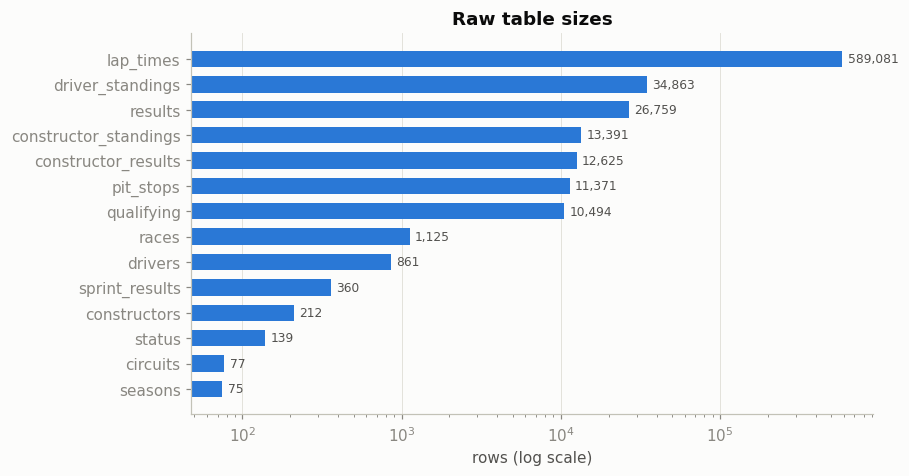

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ts = table_summary.sort_values("rows")
ax.barh(ts["table"], ts["rows"], color=C[0], height=0.65)
ax.set_xscale("log")
ax.set_xlabel("rows (log scale)")
ax.set_title("Raw table sizes")
for y, v in enumerate(ts["rows"]):
    ax.text(v * 1.08, y, f"{v:,}", va="center", fontsize=8, color=INK2)
ax.grid(axis="y", visible=False)
save_fig("eda_table_sizes")
plt.show()

### 2.2 Sentinel values (`\N`)

The CSVs mark missing values with the literal string `\N`. pandas does not recognise it, so a single `\N` turns a numeric column into a text column. The audit below counts the sentinels in every column of every table.

In [5]:
sentinel_rows = []
for name in TABLE_NAMES:
    df = raw[name]
    for col in df.columns:
        n_sent = int((df[col].astype(str) == "\\N").sum())
        n_blank = int(df[col].isna().sum())          # empty fields, which pandas already reads as NaN
        if n_sent or n_blank:
            sentinel_rows.append({"table": name, "column": col, "n_sentinel": n_sent, "n_blank": n_blank,
                                  "pct_sentinel": n_sent / len(df), "stored_dtype": str(df[col].dtype)})
sentinels = pd.DataFrame(sentinel_rows).sort_values("pct_sentinel", ascending=False).reset_index(drop=True)
print(f"{(sentinels['n_sentinel'] > 0).sum()} columns in {sentinels.loc[sentinels['n_sentinel'] > 0, 'table'].nunique()} tables contain \\N "
      f"({sentinels['n_sentinel'].sum():,} cells in total)")
print("columns that ALSO use empty fields as missing:",
      sentinels.loc[sentinels["n_blank"] > 0, ["table", "column", "n_blank"]].to_dict("records"))
sentinels.head(15)

30 columns in 6 tables contain \N (160,076 cells in total)
columns that ALSO use empty fields as missing: [{'table': 'qualifying', 'column': 'q3', 'n_blank': 46}, {'table': 'qualifying', 'column': 'q2', 'n_blank': 22}]


,table,column,n_sentinel,n_blank,pct_sentinel,stored_dtype
0,constructor_results,status,12608,0,0.9987,object
1,races,sprint_time,1110,0,0.9867,object
2,races,sprint_date,1107,0,0.9840,object
3,races,fp3_time,1072,0,0.9529,object
4,races,fp2_time,1057,0,0.9396,object
5,races,fp1_time,1057,0,0.9396,object
6,races,quali_time,1057,0,0.9396,object
7,races,fp3_date,1053,0,0.9360,object
8,drivers,number,802,0,0.9315,object
9,races,fp1_date,1035,0,0.9200,object


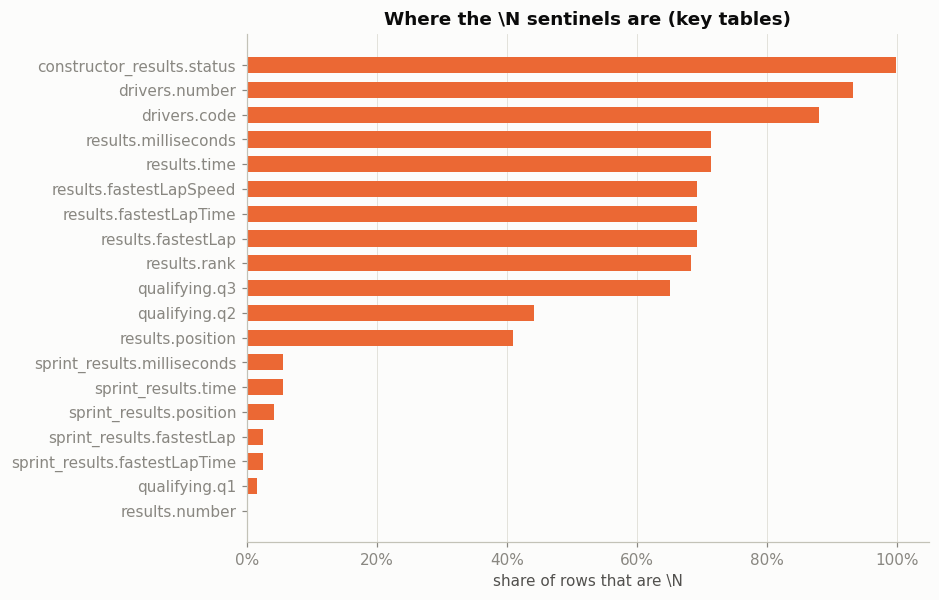

races: 11 date/time columns are mostly \N (65%–99%): the race start time is recorded only from 2005, practice/qualifying/sprint sessions only from 2021


In [6]:
plot_df = sentinels[sentinels["table"].isin(["results", "qualifying", "drivers", "sprint_results", "pit_stops", "constructor_results"])].copy()
plot_df["label"] = plot_df["table"] + "." + plot_df["column"]
plot_df = plot_df.sort_values("pct_sentinel")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_df["label"], plot_df["pct_sentinel"], color=C[1], height=0.65)
pct_axis(ax, "x")
ax.set_xlabel("share of rows that are \\N")
ax.set_title("Where the \\N sentinels are (key tables)")
ax.grid(axis="y", visible=False)
save_fig("eda_sentinels")
plt.show()
races_sent = sentinels[sentinels["table"] == "races"]
first_time = raw["races"].loc[raw["races"]["time"] != "\\N", "year"].min()
print(f"races: {len(races_sent)} date/time columns are mostly \\N ({races_sent['pct_sentinel'].min():.0%}–{races_sent['pct_sentinel'].max():.0%}): "
      f"the race start time is recorded only from {first_time}, practice/qualifying/sprint sessions only from 2021")

**What the sentinel audit shows:**
- In `results`, `position` is `\N` for every unclassified driver (about 41% of rows). This is expected, not an error, and it is why the target uses `positionOrder`, which is always filled.
- In `qualifying`, `q2` and `q3` are `\N` for drivers knocked out early. This is structural missingness, not data loss. A few `q2`/`q3` cells are **empty** instead of `\N`, so the file uses **two** encodings for "missing", and both must end up as `NaN`.
- The session schedule columns in `races` are almost entirely `\N` because the dataset only records them from 2021.

### 2.3 Semantic types

Because of the sentinels and the text formats, many columns are stored with the wrong type. The table below lists every text column with its intended meaning.

In [7]:
def guess_semantic(series):
    s = series.dropna().astype(str)
    s = s[s != "\\N"]
    if s.empty:
        return "empty"
    if pd.to_numeric(s, errors="coerce").notna().mean() > 0.99:
        return "numeric stored as text"
    if s.str.match(r"^\d{4}-\d{2}-\d{2}$").mean() > 0.99:
        return "date stored as text"
    if s.str.match(r"^\d{2}:\d{2}:\d{2}$").mean() > 0.99:
        return "clock time stored as text"
    if s.str.match(r"^\+?(\d+:)?\d+:\d{2}\.\d+$|^\d+\.\d+$").mean() > 0.9:
        return "duration stored as text"
    return "genuine text"

typing_rows = []
for name in TABLE_NAMES:
    for col in raw[name].columns:
        if not pd.api.types.is_numeric_dtype(raw[name][col]):
            typing_rows.append({"table": name, "column": col, "semantic": guess_semantic(raw[name][col]),
                                "example": raw[name][col].astype(str).loc[lambda s: s != "\\N"].iloc[0]})
typing = pd.DataFrame(typing_rows)
display(typing["semantic"].value_counts().rename("columns").to_frame())
typing[typing["semantic"] != "genuine text"].reset_index(drop=True)

,columns
semantic,
genuine text,24
numeric stored as text,12
date stored as text,7
clock time stored as text,7
duration stored as text,7


,table,column,semantic,example
0,constructor_standings,positionText,numeric stored as text,1
1,drivers,number,numeric stored as text,44
2,drivers,dob,date stored as text,1985-01-07
3,driver_standings,positionText,numeric stored as text,1
4,races,date,date stored as text,2009-03-29
5,races,time,clock time stored as text,06:00:00
6,races,fp1_date,date stored as text,2021-04-16
7,races,fp1_time,clock time stored as text,12:00:00
8,races,fp2_date,date stored as text,2021-04-16
9,races,fp2_time,clock time stored as text,15:00:00


### 2.4 Seasons, field sizes and the podium base rate

These numbers come from `results` joined to `races` to get the season year.

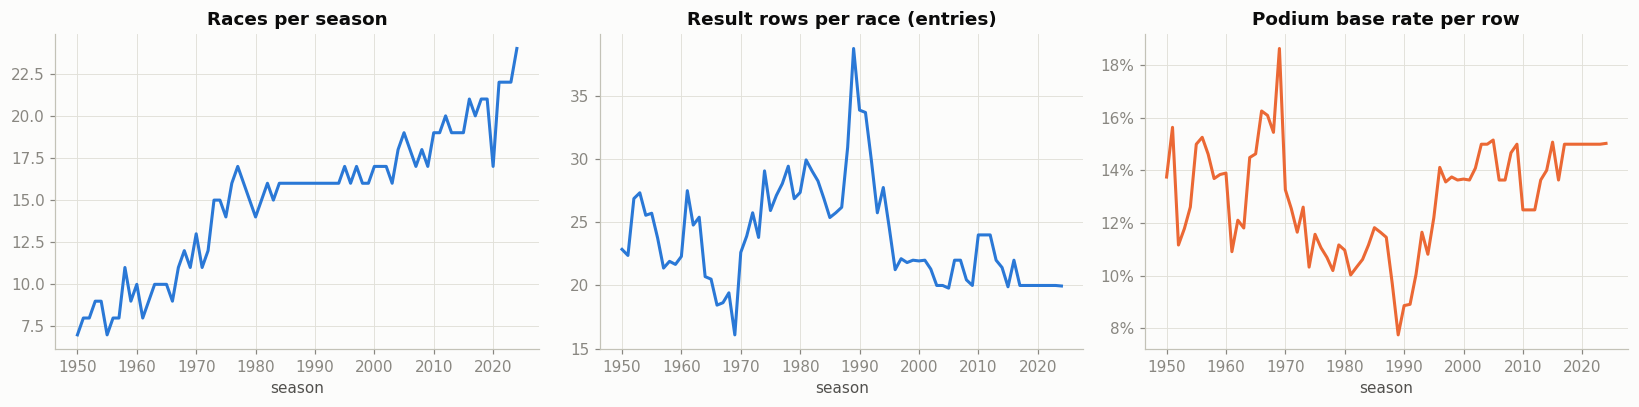

Overall podium rate (raw rows): 12.7%;  lowest season: 1989 (7.7%),  highest: 1969 (18.6%)


In [8]:
res_raw = raw["results"].merge(raw["races"][["raceId", "year", "name"]], on="raceId")
res_raw["is_podium"] = res_raw["positionOrder"] <= 3
season_raw = res_raw.groupby("year").agg(races=("raceId", "nunique"), rows=("raceId", "size"),
                                         podium_rate=("is_podium", "mean"))
season_raw["rows_per_race"] = season_raw["rows"] / season_raw["races"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(season_raw.index, season_raw["races"], color=C[0])
axes[0].set_title("Races per season")
axes[1].plot(season_raw.index, season_raw["rows_per_race"], color=C[0])
axes[1].set_title("Result rows per race (entries)")
axes[2].plot(season_raw.index, season_raw["podium_rate"], color=C[1])
axes[2].set_title("Podium base rate per row")
pct_axis(axes[2])
for ax in axes:
    ax.set_xlabel("season")
plt.tight_layout()
save_fig("eda_seasons_raw")
plt.show()
print(f"Overall podium rate (raw rows): {res_raw['is_podium'].mean():.1%};  "
      f"lowest season: {season_raw['podium_rate'].idxmin()} ({season_raw['podium_rate'].min():.1%}),  "
      f"highest: {season_raw['podium_rate'].idxmax()} ({season_raw['podium_rate'].max():.1%})")

The class is **rare and its rate drifts over time**. In the 1950s and 1980s–90s there were often more than 30 entries per race, compared with about 20 today, so the share of rows that are podiums swings from 7.7% (1989) to 18.6% (1969). Two things follow: the metrics must suit an imbalanced target (PR-AUC, F1), and the cleaning must remove rows that were never in the race at all (next plot).

### 2.5 `grid = 0` and non-starters

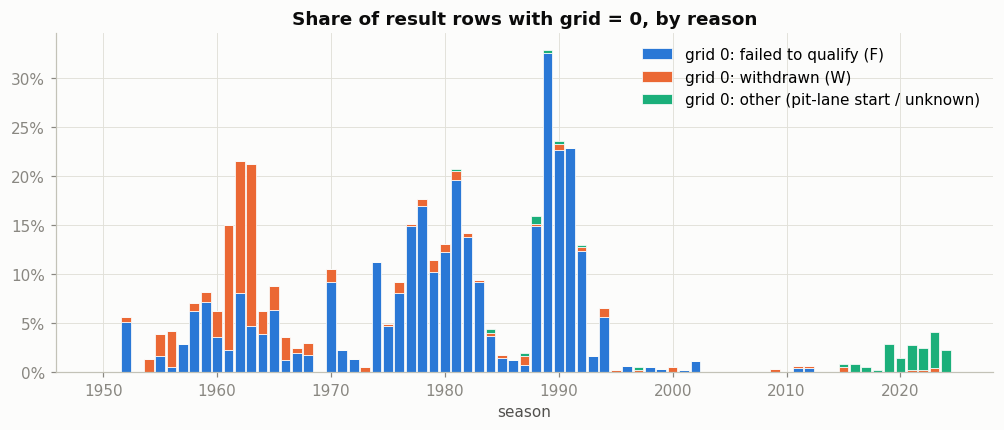

year,before 1994,1994+,All
grid0_kind,,,
grid 0: failed to qualify (F),1309,39,1348
grid 0: other (pit-lane start / unknown),13,74,87
grid 0: withdrawn (W),186,17,203
started from a grid slot,12893,12228,25121
All,14401,12358,26759


In [9]:
res_raw["grid0_kind"] = np.where(res_raw["grid"] != 0, "started from a grid slot",
                          np.where(res_raw["positionText"].isin(["F"]), "grid 0: failed to qualify (F)",
                          np.where(res_raw["positionText"].isin(["W"]), "grid 0: withdrawn (W)", "grid 0: other (pit-lane start / unknown)")))
g0 = pd.crosstab(res_raw["year"], res_raw["grid0_kind"], normalize="index").drop(columns="started from a grid slot")
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(g0))
for i, col in enumerate(["grid 0: failed to qualify (F)", "grid 0: withdrawn (W)", "grid 0: other (pit-lane start / unknown)"]):
    ax.bar(g0.index, g0[col], bottom=bottom, color=C[i], label=col, width=0.85, edgecolor="#fcfcfb", linewidth=0.5)
    bottom += g0[col].values
pct_axis(ax)
ax.set_title("Share of result rows with grid = 0, by reason")
ax.set_xlabel("season")
ax.legend(loc="upper right")
save_fig("eda_grid_zero")
plt.show()
display(pd.crosstab(res_raw["grid0_kind"], res_raw["year"] >= 1994, margins=True).rename(columns={False: "before 1994", True: "1994+"}))

**`grid = 0` means different things in different eras:**
- **Before 1994** it almost always marks a car that **never started**: it failed to qualify or pre-qualify (`F`), or was withdrawn (`W`). Those rows can never be podiums and do not answer the question "will this driver, who is on the grid, finish in the top 3?". Section 3.4 removes them.
- **From 1994** most `grid = 0` rows are **pit-lane starts**: these drivers really did race, and some finished in the points. For them `grid = 0` is a real starting position, at the back, so it must not be read as "missing" or as "pole".

### 2.6 Qualifying coverage drift

This section checks how many result rows have a matching `qualifying` row, joining on `(raceId, driverId)`.

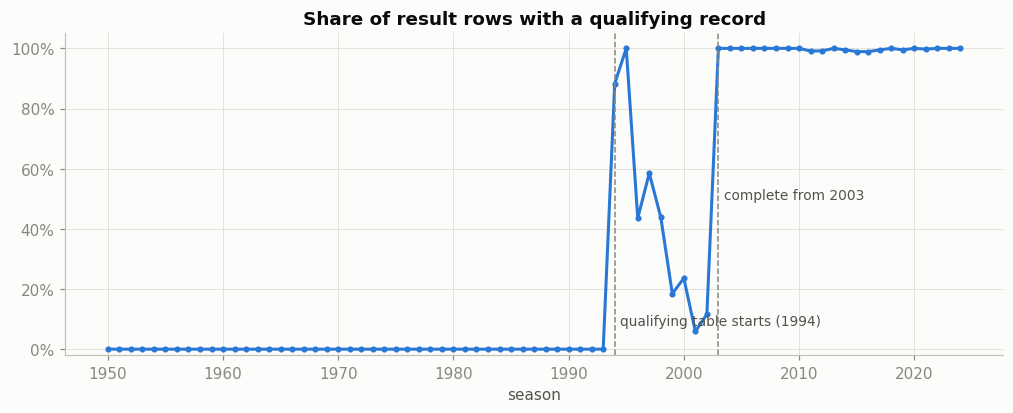

{1994: '88%', 1995: '100%', 1996: '44%', 1997: '59%', 1998: '44%', 1999: '18%', 2000: '24%', 2001: '6%', 2002: '12%', 2003: '100%', 2004: '100%'}


In [10]:
q_keys = raw["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_quali=1)
cov = res_raw.merge(q_keys, on=["raceId", "driverId"], how="left")
cov["has_quali"] = cov["has_quali"].fillna(0)
cov_season = cov.groupby("year")["has_quali"].mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(cov_season.index, cov_season.values, color=C[0], marker="o", markersize=3)
for yr, txt in [(1994, "qualifying table starts (1994)"), (2003, "complete from 2003")]:
    ax.axvline(yr, color=MUTED, linestyle="--", linewidth=1)
    ax.text(yr + 0.5, 0.08 if yr == 1994 else 0.5, txt, color=INK2, fontsize=9)
pct_axis(ax)
ax.set_ylim(-0.02, 1.05)
ax.set_title("Share of result rows with a qualifying record")
ax.set_xlabel("season")
save_fig("eda_quali_coverage")
plt.show()
print(cov_season.loc[1994:2004].map("{:.0%}".format).to_dict())

This confirms the "historical qualifying-coverage drift" the brief warns about, and it is worse than the background notes suggested. The qualifying table **begins in 1994**, and coverage is **patchy from 1996 to 2002**, dropping to 6% in 2001. It is only complete from **2003**. Any qualifying feature will therefore be missing for every pre-1994 row and for most 1996–2002 rows. Section 7 runs an experiment to decide how to handle this.

### 2.7 Duplicate `(raceId, driverId)` rows and race statuses

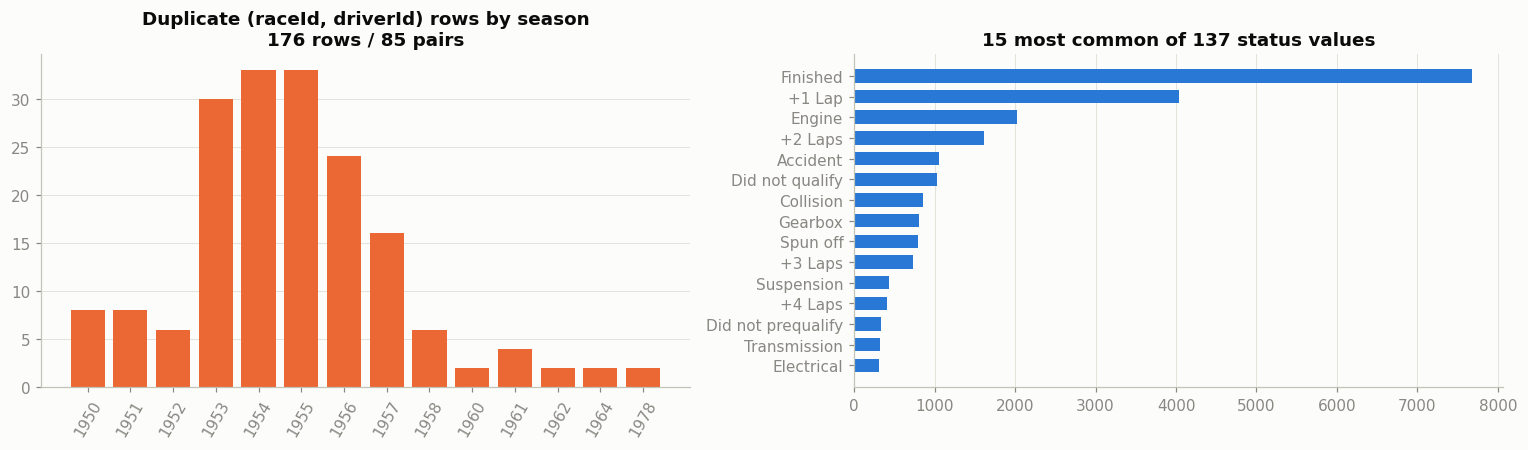

In [11]:
dup_mask = res_raw.duplicated(["raceId", "driverId"], keep=False)
dups_by_year = res_raw[dup_mask].groupby("year").size()
n_pairs = res_raw[dup_mask].groupby(["raceId", "driverId"]).ngroups
status_raw = raw["results"].merge(raw["status"], on="statusId")["status"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(dups_by_year.index.astype(str), dups_by_year.values, color=C[1])
axes[0].set_title(f"Duplicate (raceId, driverId) rows by season\n{dup_mask.sum()} rows / {n_pairs} pairs")
axes[0].tick_params(axis="x", rotation=60)
axes[0].grid(axis="x", visible=False)
top = status_raw.head(15).sort_values()
axes[1].barh(top.index, top.values, color=C[0], height=0.65)
axes[1].set_title(f"15 most common of {len(status_raw)} status values")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
save_fig("eda_duplicates_status")
plt.show()

## 3. Data cleaning & auditing

All cleaning happens on **copies** (`clean = {...}`); the `raw` dictionary and the CSV files are never modified.

### 3.1 Sentinels and semantic typing

The rules below follow directly from the audits in 2.2 and 2.3:

| Issue found in EDA | Rule |
|---|---|
| `\N` placeholder in 30 columns | replace with a real missing value (`NaN` / `NaT`) |
| numbers stored as text (`position`, `milliseconds`, `number`, …) | `pd.to_numeric` |
| dates stored as text (`races.date`, session dates, `drivers.dob`) | `pd.to_datetime` |
| race start = separate date + clock-time text columns | combine into one `race_start` timestamp (UTC) |
| durations as `m:ss.sss` text (`q1/q2/q3`, `fastestLapTime`, lap `time`, pit `duration`) | convert to **numeric seconds** |
| `results.time` mixes the winner's total time with `+gap` strings | kept as text; the numeric duration is already in `milliseconds` |
| an impossible qualifying lap (1995 Japanese GP Q1 = `16:42.640`, 10× the pole time) | lap times more than 2× the fastest time in the same session of the same race are set to missing (real slow laps in rain stay below 2×) |
| extra issues we found: stray whitespace (e.g. nationality `"Argentinian "`), circuit country written both `USA` and `United States` | strip whitespace; normalise to `USA` |

In [12]:
SENTINEL = "\\N"

def to_seconds(series):
    """Duration text -> float seconds: '1:27.452' -> 87.452, '1:34:50.616' -> 5690.616, '26.898' -> 26.898."""
    def convert(value):
        if pd.isna(value):
            return np.nan
        try:
            total = 0.0
            for part in str(value).lstrip("+").split(":"):
                total = total * 60 + float(part)
            return total
        except ValueError:
            return np.nan
    return series.map(convert).astype(float)

NUMERIC_COLS = {
    "results": ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapSpeed"],
    "sprint_results": ["number", "position", "milliseconds", "fastestLap"],
    "drivers": ["number"],
    "driver_standings": ["position"], "constructor_standings": ["position"],
}
DATE_COLS = {
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
    "drivers": ["dob"],
}
DURATION_COLS = {
    "qualifying": ["q1", "q2", "q3"],
    "results": ["fastestLapTime"],
    "sprint_results": ["fastestLapTime"],
    "lap_times": ["time"],
    "pit_stops": ["duration"],
}

clean = {}
for name in TABLE_NAMES:
    df = raw[name].copy()                                  # never touch the raw table
    df = df.replace(SENTINEL, np.nan)
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].str.strip()
    for col in NUMERIC_COLS.get(name, []):
        df[col] = pd.to_numeric(df[col], errors="raise")
    for col in DATE_COLS.get(name, []):
        df[col] = pd.to_datetime(df[col], format="%Y-%m-%d", errors="raise")
    for col in DURATION_COLS.get(name, []):
        df[col] = to_seconds(df[col])
    clean[name] = df

# implausible qualifying laps -> missing (data-entry errors, not slow laps)
quali_c = clean["qualifying"]
for col in ["q1", "q2", "q3"]:
    fastest = quali_c.groupby("raceId")[col].transform("min")
    implausible = quali_c[col] > 2 * fastest
    if implausible.any():
        print(f"{col}: {implausible.sum()} implausible lap(s) set to NaN ->",
              quali_c.loc[implausible, ["raceId", "driverId", col]].to_dict("records"))
    quali_c.loc[implausible, col] = np.nan

# race start timestamp (UTC); time of day is unknown for older races -> date only
races_c = clean["races"]
races_c["race_start"] = races_c["date"] + pd.to_timedelta(races_c["time"].fillna("00:00:00"))
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})

remaining = sum(int((clean[n].astype(str) == SENTINEL).sum().sum()) for n in TABLE_NAMES)
print("\\N cells remaining after cleaning:", remaining)

q1: 1 implausible lap(s) set to NaN -> [{'raceId': 255, 'driverId': 87, 'q1': 1002.64}]
\N cells remaining after cleaning: 0


**Checking the conversions.** Two tables store the same duration twice, once as text and once in milliseconds, which lets us test the parser instead of trusting it.

In [13]:
lap_diff = (clean["lap_times"]["time"] - clean["lap_times"]["milliseconds"] / 1000).abs()
pit_diff = (clean["pit_stops"]["duration"] - clean["pit_stops"]["milliseconds"] / 1000).abs()
print(f"lap_times : parsed text vs milliseconds, max |diff| = {lap_diff.max():.4f}s over {lap_diff.notna().sum():,} laps")
print(f"pit_stops : parsed text vs milliseconds, max |diff| = {pit_diff.max():.4f}s over {pit_diff.notna().sum():,} stops")

before_after = []
for name, cols in {"results": ["position", "milliseconds", "fastestLapTime"],
                   "qualifying": ["q1", "q2", "q3"], "races": ["date", "race_start"],
                   "drivers": ["dob", "nationality"], "pit_stops": ["duration"]}.items():
    for col in cols:
        before_after.append({"table": name, "column": col,
                             "raw dtype": str(raw[name][col].dtype) if col in raw[name] else "(new)",
                             "clean dtype": str(clean[name][col].dtype),
                             "missing after": int(clean[name][col].isna().sum()),
                             "example": clean[name][col].dropna().iloc[0]})
pd.DataFrame(before_after)

lap_times : parsed text vs milliseconds, max |diff| = 0.0000s over 589,081 laps
pit_stops : parsed text vs milliseconds, max |diff| = 0.0000s over 11,371 stops


,table,column,raw dtype,clean dtype,missing after,example
0,results,position,object,float64,10953,1.0000
1,results,milliseconds,object,float64,19079,"5,690,616.0000"
2,results,fastestLapTime,object,float64,18507,87.4520
3,qualifying,q1,object,float64,157,86.5720
4,qualifying,q2,object,float64,4647,85.1870
5,qualifying,q3,object,float64,6865,86.7140
6,races,date,object,datetime64[ns],0,2009-03-29 00:00:00
7,races,race_start,(new),datetime64[ns],0,2009-03-29 06:00:00
8,drivers,dob,object,datetime64[ns],0,1985-01-07 00:00:00
9,drivers,nationality,object,object,0,British


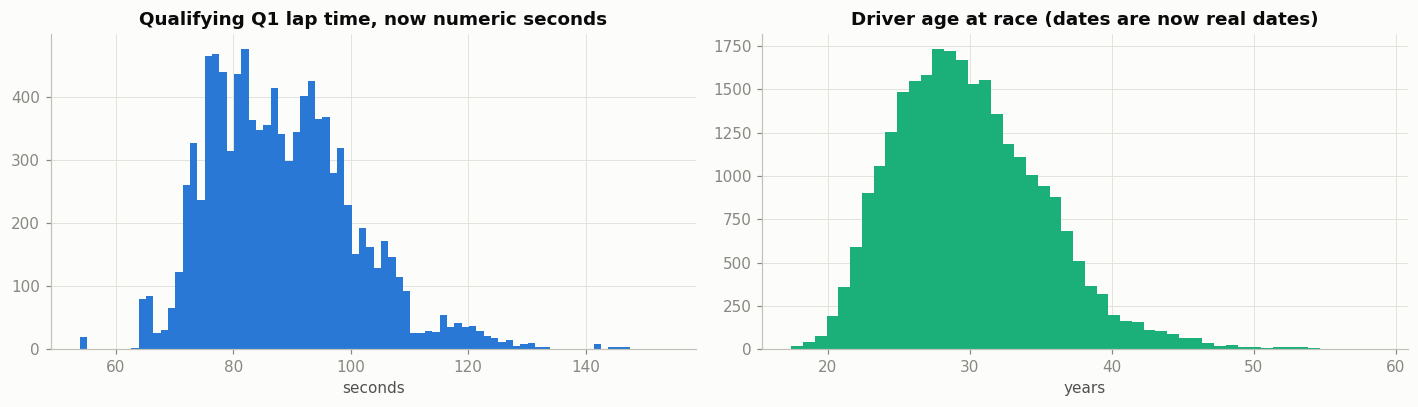

Q1 times after cleaning: 53.9s to 153.9s;  driver age at race: 17.5 to 58.8 years


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
q1 = clean["qualifying"]["q1"].dropna()
axes[0].hist(q1, bins=80, color=C[0])
axes[0].set_title("Qualifying Q1 lap time, now numeric seconds")
axes[0].set_xlabel("seconds")
age = ((clean["races"].set_index("raceId")["date"].reindex(clean["results"]["raceId"]).values
        - clean["drivers"].set_index("driverId")["dob"].reindex(clean["results"]["driverId"]).values)
       / np.timedelta64(1, "D") / 365.25)
axes[1].hist(age[~np.isnan(age)], bins=50, color=C[2])
axes[1].set_title("Driver age at race (dates are now real dates)")
axes[1].set_xlabel("years")
plt.tight_layout()
save_fig("clean_typing_examples")
plt.show()
print(f"Q1 times after cleaning: {q1.min():.1f}s to {q1.max():.1f}s;  driver age at race: {np.nanmin(age):.1f} to {np.nanmax(age):.1f} years")

### 3.2 Primary keys and foreign keys

- **Primary keys:** each table's id column, or a composite key for `lap_times` and `pit_stops`, must be **unique and non-null**.
- **Natural keys:** `races (year, round)`, `qualifying (raceId, driverId)` and the standings tables should also be unique. The `results (raceId, driverId)` check is the grain check required by the brief.
- **Foreign keys:** every reference must exist in the table it points to.

In [15]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "sprint_results": ["resultId"], "qualifying": ["qualifyId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
NATURAL_KEYS = {
    "races": ["year", "round"], "qualifying": ["raceId", "driverId"],
    "driver_standings": ["raceId", "driverId"], "constructor_standings": ["raceId", "constructorId"],
    "constructor_results": ["raceId", "constructorId"], "sprint_results": ["raceId", "driverId"],
    "results": ["raceId", "driverId"],
}

def key_check(table, cols, kind):
    df = clean[table]
    return {"table": table, "key": ", ".join(cols), "kind": kind, "rows": len(df),
            "null keys": int(df[cols].isna().any(axis=1).sum()),
            "duplicate keys": int(df.duplicated(cols).sum())}

key_report = pd.DataFrame([key_check(t, c, "primary") for t, c in PRIMARY_KEYS.items()] +
                          [key_check(t, c, "natural") for t, c in NATURAL_KEYS.items()])
key_report["ok"] = (key_report["null keys"] == 0) & (key_report["duplicate keys"] == 0)
key_report

,table,key,kind,rows,null keys,duplicate keys,ok
0,circuits,circuitId,primary,77,0,0,True
1,constructors,constructorId,primary,212,0,0,True
2,drivers,driverId,primary,861,0,0,True
3,races,raceId,primary,1125,0,0,True
4,seasons,year,primary,75,0,0,True
5,status,statusId,primary,139,0,0,True
6,results,resultId,primary,26759,0,0,True
7,sprint_results,resultId,primary,360,0,0,True
8,qualifying,qualifyId,primary,10494,0,0,True
9,driver_standings,driverStandingsId,primary,34863,0,0,True


In [16]:
FOREIGN_KEYS = [  # (child table, column, parent table, parent column)
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    ("results", "raceId", "races", "raceId"), ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"), ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"), ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "raceId", "races", "raceId"), ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"), ("sprint_results", "statusId", "status", "statusId"),
    ("driver_standings", "raceId", "races", "raceId"), ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"), ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"), ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"), ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"), ("pit_stops", "driverId", "drivers", "driverId"),
]
fk_rows = []
for child, col, parent, pcol in FOREIGN_KEYS:
    values = clean[child][col].dropna()
    orphans = ~values.isin(clean[parent][pcol])
    fk_rows.append({"child": f"{child}.{col}", "parent": f"{parent}.{pcol}", "references": len(values),
                    "orphans": int(orphans.sum()), "null refs": int(clean[child][col].isna().sum())})

# Cross-table consistency: a qualifying / lap / pit-stop row should belong to a driver who has a result in that race
res_keys = clean["results"][["raceId", "driverId"]].drop_duplicates()
for child in ["qualifying", "lap_times", "pit_stops", "sprint_results"]:
    m = clean[child][["raceId", "driverId"]].drop_duplicates().merge(res_keys, how="left", indicator=True)
    fk_rows.append({"child": f"{child}.(raceId, driverId)", "parent": "results.(raceId, driverId)",
                    "references": len(m), "orphans": int((m["_merge"] == "left_only").sum()), "null refs": 0})
fk_report = pd.DataFrame(fk_rows)
fk_report["ok"] = (fk_report["orphans"] == 0) & (fk_report["null refs"] == 0)
print(f"{fk_report['ok'].sum()} / {len(fk_report)} referential checks pass")
fk_report

27 / 27 referential checks pass


,child,parent,references,orphans,null refs,ok
0,races.circuitId,circuits.circuitId,1125,0,0,True
1,races.year,seasons.year,1125,0,0,True
2,results.raceId,races.raceId,26759,0,0,True
3,results.driverId,drivers.driverId,26759,0,0,True
4,results.constructorId,constructors.constructorId,26759,0,0,True
5,results.statusId,status.statusId,26759,0,0,True
6,qualifying.raceId,races.raceId,10494,0,0,True
7,qualifying.driverId,drivers.driverId,10494,0,0,True
8,qualifying.constructorId,constructors.constructorId,10494,0,0,True
9,sprint_results.raceId,races.raceId,360,0,0,True


qualifying vs results constructor mismatch: 10 of 10,494 driver-race pairs


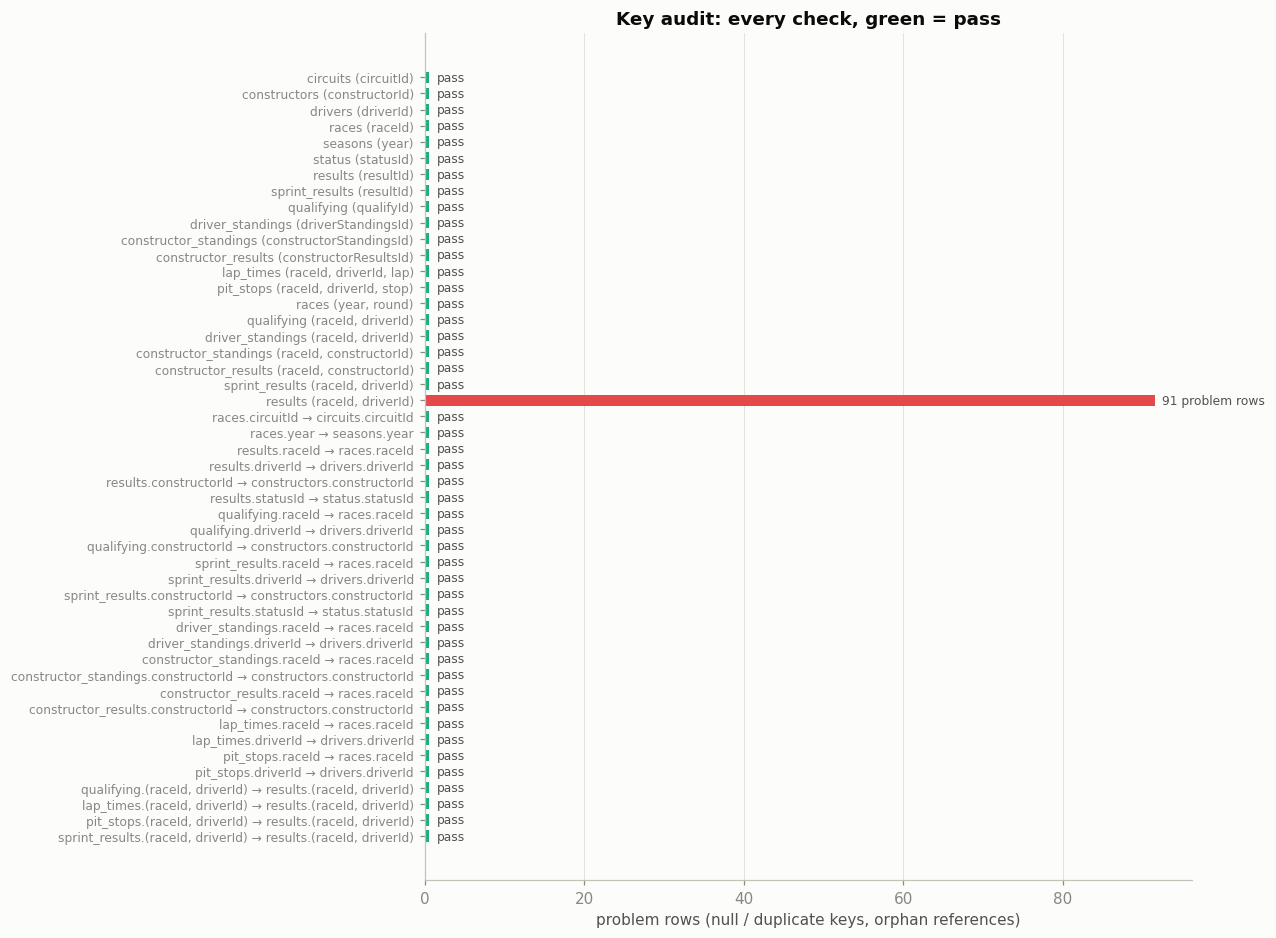

In [17]:
qr = clean["qualifying"].merge(clean["results"][["raceId", "driverId", "constructorId"]], on=["raceId", "driverId"],
                               suffixes=("_quali", "_result"))
mismatch = (qr["constructorId_quali"] != qr["constructorId_result"]).sum()
print(f"qualifying vs results constructor mismatch: {mismatch} of {len(qr):,} driver-race pairs")

checks = pd.concat([
    key_report.assign(check=key_report["table"] + " (" + key_report["key"] + ")", problems=key_report["null keys"] + key_report["duplicate keys"])[["check", "problems"]],
    fk_report.assign(check=fk_report["child"] + " → " + fk_report["parent"], problems=fk_report["orphans"] + fk_report["null refs"])[["check", "problems"]],
])
fig, ax = plt.subplots(figsize=(9, 10))
colors = [C[7] if p > 0 else C[2] for p in checks["problems"]]
ax.barh(checks["check"], checks["problems"].clip(lower=0) + 0.6, color=colors, height=0.7)
for y, p in enumerate(checks["problems"]):
    ax.text(p + 1.5, y, "pass" if p == 0 else f"{p} problem rows", va="center", fontsize=8, color=INK2)
ax.invert_yaxis()
ax.set_xlabel("problem rows (null / duplicate keys, orphan references)")
ax.set_title("Key audit: every check, green = pass")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
save_fig("clean_key_audit")
plt.show()

**Key audit result:**
- Every primary key is unique and non-null, and every foreign key reconciles, so there are no orphan races, drivers, constructors or statuses.
- Every qualifying, lap and pit-stop row belongs to a driver who has a result in that race.
- 10 of 10,494 qualifying rows name a different constructor than the result row. These are mostly late car swaps between qualifying and the race. We take the constructor from `results`, because that is the car that actually started.
- The **only** failed check is the modeling grain: `results (raceId, driverId)` has duplicates. Section 3.3 handles them.

### 3.3 Duplicate `(raceId, driverId)` rows (shared drives)

In the 1950s a driver could hand his car to a teammate or take over another car mid-race. Ergast records one row **per car** a driver drove, so these drivers have two or three rows in one race. A real example follows.

In [18]:
res = clean["results"].merge(clean["races"][["raceId", "year", "name"]], on="raceId") \
                      .merge(clean["drivers"][["driverId", "surname"]], on="driverId") \
                      .merge(clean["status"], on="statusId")
example = res[(res["year"] == 1957) & (res["name"] == "British Grand Prix") & res["surname"].isin(["Moss", "Brooks"])]
example[["resultId", "year", "name", "surname", "number", "grid", "laps", "positionOrder", "points", "status"]].sort_values(["surname", "resultId"])

,resultId,year,name,surname,number,grid,laps,positionOrder,points,status
18805,18806,1957,British Grand Prix,Brooks,20.0000,3,90,1,4.0000,Finished
20290,20293,1957,British Grand Prix,Brooks,18.0000,1,51,12,0.0000,Engine
18816,18817,1957,British Grand Prix,Moss,18.0000,1,51,12,0.0000,Engine
20288,20291,1957,British Grand Prix,Moss,20.0000,3,90,1,5.0000,Finished


**Reading the example (1957 British GP).** Moss started car #18 from pole. When its engine failed he took over Brooks's car #20, which Brooks had started from P3, and won. Ergast gives each man **both** cars' rows, and **each row carries the grid slot of that car**, not of the driver.

**Which row to keep?** We compared the candidate rules:

In [19]:
dups = res[res.duplicated(["raceId", "driverId"], keep=False)].sort_values("resultId")
first_row = dups.drop_duplicates(["raceId", "driverId"], keep="first").set_index(["raceId", "driverId"])
best_row = dups.sort_values(["positionOrder", "resultId"]).drop_duplicates(["raceId", "driverId"]).set_index(["raceId", "driverId"])
best_row = best_row.loc[first_row.index]
nonzero = dups[dups["grid"] > 0].groupby(["raceId", "driverId"]).size().reindex(first_row.index).fillna(0)
any_podium = dups.groupby(["raceId", "driverId"])["positionOrder"].min().le(3)

rule_table = pd.DataFrame({
    "rule": ["keep row with non-zero grid", "keep row with best positionOrder", "keep first entry (lowest resultId) = car the driver started in"],
    "pairs where rule cannot decide": [int((nonzero != 1).sum()), 0, 0],
    "pairs where the kept grid slot belongs to a different car than the first entry": [np.nan, int((best_row["resultId"] != first_row["resultId"]).sum()), 0],
})
display(rule_table)
print(f"{len(first_row)} duplicate pairs; in {int(any_podium.sum())} of them the driver was classified on the podium in at least one car")
print(f"if we used only the kept row's own positionOrder, {int(((first_row['positionOrder'] <= 3) != any_podium.loc[first_row.index]).sum())} officially credited podiums would be lost")

,rule,pairs where rule cannot decide,pairs where the kept grid slot belongs to a different car than the first entry
0,keep row with non-zero grid,85,NaN
1,keep row with best positionOrder,0,64.0000
2,keep first entry (lowest resultId) = car the d...,0,0.0000


85 duplicate pairs; in 22 of them the driver was classified on the podium in at least one car
if we used only the kept row's own positionOrder, 16 officially credited podiums would be lost


**Our rule: one row per driver = the car he started in; the label = was he classified on the podium in any car.**

1. **Rows: keep the first entry, i.e. the lowest `resultId`.** The prediction is made before the start, so the only legitimate pre-race information is the car the driver *started* in: its grid slot and its constructor.
   - The *non-zero grid* rule never decides here: in 82 of the 85 pairs **both** rows have a grid slot, because each row carries its car's slot, and in the other 3 **neither** does (the driver failed to qualify in both cars).
   - The *best positionOrder* rule would give 64 drivers the grid slot of a car they did not start in, for example Moss at P3 in 1957 when he started from pole. That is post-start information leaking into a pre-race feature.
   - Ergast lists the driver's original entry first. We checked this against documented shared drives: Moss and Brooks in the 1957 British GP, Fangio in the 1956 Italian GP (pole in #22, then took Collins's #26), and Moss in the 1960 Argentine GP (pole in #36, then took Trintignant's #38). In every case the lowest `resultId` is the car the driver started in.
2. **Label: `podium = 1` if the driver was classified 1st–3rd in any of his cars.** The question is "does *this driver* finish on the podium", and officially these drivers are credited with that result. Using only the started car's position would wrongly turn 16 credited podiums into non-podiums.

**Impact:** 85 pairs (176 rows → 85 rows), all from 1950–1964 except one 1978 driver who failed to qualify in two cars. As section 7 shows, none of these rows ends up in the final training window, so the rule matters for the data-engineering questions rather than for the model.

In [20]:
res_c = clean["results"].copy()
grp = res_c.groupby(["raceId", "driverId"])
res_c["podium"] = (grp["positionOrder"].transform("min") <= 3).astype(int)   # credited in any car
res_c["n_cars_driven"] = grp["resultId"].transform("size")
res_dedup = res_c.sort_values("resultId").drop_duplicates(["raceId", "driverId"], keep="first")
assert not res_dedup.duplicated(["raceId", "driverId"]).any()
print(f"results: {len(res_c):,} rows -> {len(res_dedup):,} rows after the shared-drive rule "
      f"({len(res_c) - len(res_dedup)} rows removed)")

results: 26,759 rows -> 26,668 rows after the shared-drive rule (91 rows removed)


### 3.4 The modeling population: which rows are real "predictions"?

Each row should answer the question *"this driver is on the grid: will he finish in the top 3?"*. Two kinds of row do not fit that question:

1. **The Indianapolis 500 (1950–1960).** It was a separate American oval race that counted for the championship, but almost none of its entrants raced in Formula 1 (computed below). Its grid structure and entrants are a different population, and it would distort the home-race analysis (Q2), because American drivers almost always "won at home". It is identified **by race name**, not by circuit: circuitId 19 (Indianapolis) also hosted the normal US Grand Prix from 2000 to 2007, and those races are kept.
2. **Non-starters:** `positionText = F` (failed to qualify or pre-qualify) and `W` (withdrawn, did not start). They never took the start, and section 2.5 showed they are where most `grid = 0` values come from. A non-starter's "podium = 0" is known before the race and only inflates the number of easy negatives. *Caveat:* a few modern `W` rows are cars that failed on the formation lap, which is after our cutoff. They are a tiny share of modern rows (printed below), so we accept this.

The remaining `grid = 0` rows are **pit-lane starts**. They get `grid_pos` = one slot behind the last car on the grid, plus a `pit_lane_start = 1` flag. That keeps them at the back without treating 0 as pole.

In [21]:
indy_ids = clean["races"].loc[clean["races"]["name"] == "Indianapolis 500", "raceId"]
indy_drivers = res_dedup.loc[res_dedup["raceId"].isin(indy_ids), "driverId"].unique()
other_drivers = res_dedup.loc[~res_dedup["raceId"].isin(indy_ids), "driverId"].unique()
american = clean["drivers"].set_index("driverId").loc[indy_drivers, "nationality"].eq("American").mean()
print(f"Indianapolis 500: {len(indy_ids)} races, {len(indy_drivers)} different drivers; "
      f"{np.isin(indy_drivers, other_drivers).mean():.0%} of them ever entered another championship race; {american:.0%} American")

steps = [("raw results rows", len(clean["results"]))]
steps.append(("after shared-drive rule (3.3)", len(res_dedup)))
pop = res_dedup[~res_dedup["raceId"].isin(indy_ids)].copy()
steps.append(("after removing Indianapolis 500", len(pop)))
non_starter = pop["positionText"].isin(["F", "W"])
removed_ns = pop[non_starter]
pop = pop[~non_starter].copy()
steps.append(("after removing non-starters (F, W)", len(pop)))
modern = removed_ns.merge(clean["races"][["raceId", "year"]], on="raceId")["year"] >= 2003
n_modern = res_dedup.merge(clean["races"][["raceId", "year"]], on="raceId")["year"].ge(2003).sum()
print(f"non-starters removed in 2003+: {int(modern.sum())} of {n_modern:,} rows ({modern.sum() / n_modern:.2%})")
waterfall = pd.DataFrame(steps, columns=["step", "rows"])
waterfall["removed"] = -waterfall["rows"].diff().fillna(0).astype(int)
waterfall

Indianapolis 500: 11 races, 107 different drivers; 4% of them ever entered another championship race; 99% American
non-starters removed in 2003+: 60 of 8,970 rows (0.67%)


,step,rows,removed
0,raw results rows,26759,0
1,after shared-drive rule (3.3),26668,91
2,after removing Indianapolis 500,26287,381
3,"after removing non-starters (F, W)",24586,1701


In [22]:
# Build the clean driver-race base table (one row per starter per race)
races_info = clean["races"][["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race_name"})
circ_info = clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name", "country": "circuit_country"})
base = (pop.merge(races_info, on="raceId", how="left")
           .merge(circ_info, on="circuitId", how="left")
           .merge(clean["status"], on="statusId", how="left"))

base["pit_lane_start"] = (base["grid"] == 0).astype(int)
last_slot = base.groupby("raceId")["grid"].transform("max")
base["grid_pos"] = np.where(base["grid"] == 0, last_slot + 1, base["grid"])
base["field_size"] = base.groupby("raceId")["driverId"].transform("size")
base = base.sort_values(["date", "raceId", "grid_pos"]).reset_index(drop=True)

assert not base.duplicated(["raceId", "driverId"]).any(), "grain violated"
assert base[["raceId", "driverId", "constructorId", "grid_pos", "positionOrder", "podium", "date"]].notna().all().all()
print(f"base table: {len(base):,} rows, {base['raceId'].nunique():,} races, {base['year'].min()}–{base['year'].max()}; "
      f"unique (raceId, driverId): {not base.duplicated(['raceId', 'driverId']).any()}")
print(f"pit-lane starts kept: {base['pit_lane_start'].sum()}  |  podium rate: {base['podium'].mean():.1%}")
base[["raceId", "year", "round", "race_name", "driverId", "constructorId", "grid", "grid_pos", "pit_lane_start",
      "field_size", "positionOrder", "status", "podium"]].head()

base table: 24,586 rows, 1,114 races, 1950–2024; unique (raceId, driverId): True
pit-lane starts kept: 87  |  podium rate: 13.7%


,raceId,year,round,race_name,driverId,constructorId,grid,grid_pos,pit_lane_start,field_size,positionOrder,status,podium
0,833,1950,1,British Grand Prix,642,51,1,1,0,23,1,Finished,1
1,833,1950,1,British Grand Prix,786,51,2,2,0,23,2,Finished,1
2,833,1950,1,British Grand Prix,579,51,3,3,0,23,12,Oil leak,0
3,833,1950,1,British Grand Prix,686,51,4,4,0,23,3,Finished,1
4,833,1950,1,British Grand Prix,669,105,5,5,0,23,14,Out of fuel,0


## 4. EDA after cleaning: what the cleaning changed

This section repeats key views from section 2 on the clean `base` table to show the effect of each cleaning step.

In [23]:
def is_finished(status):
    """Reached the chequered flag: 'Finished' or lapped ('+1 Lap', '+2 Laps', ...)."""
    return status.eq("Finished") | status.str.match(r"^\+\d+ Laps?$")

base["finished"] = is_finished(base["status"]).astype(int)
res_raw["finished"] = is_finished(res_raw.merge(raw["status"], on="statusId", how="left")["status"]).astype(int).values

q_keys_clean = clean["qualifying"][["raceId", "driverId"]].assign(has_quali=1)
base = base.merge(q_keys_clean, on=["raceId", "driverId"], how="left")
base["has_quali"] = base["has_quali"].fillna(0).astype(int)

compare = pd.DataFrame({
    "rows": [len(res_raw), len(base)],
    "races": [res_raw["raceId"].nunique(), base["raceId"].nunique()],
    "duplicate (raceId, driverId)": [int(res_raw.duplicated(["raceId", "driverId"]).sum()), int(base.duplicated(["raceId", "driverId"]).sum())],
    "rows with grid = 0": [int((res_raw["grid"] == 0).sum()), int(base["pit_lane_start"].sum())],
    "podium rate": [res_raw["is_podium"].mean(), base["podium"].mean()],
    "finish rate": [res_raw["finished"].mean(), base["finished"].mean()],
    "rows with qualifying data": [cov["has_quali"].mean(), base["has_quali"].mean()],
}, index=["raw results", "clean base table"]).T
rate_rows = ["podium rate", "finish rate", "rows with qualifying data"]
compare.apply(lambda row: row.map("{:.1%}".format) if row.name in rate_rows else row.map("{:,.0f}".format), axis=1)

,raw results,clean base table
rows,"26,759","24,586"
races,"1,125","1,114"
"duplicate (raceId, driverId)",91,0
rows with grid = 0,"1,638",87
podium rate,12.7%,13.7%
finish rate,56.7%,60.7%
rows with qualifying data,39.2%,42.4%


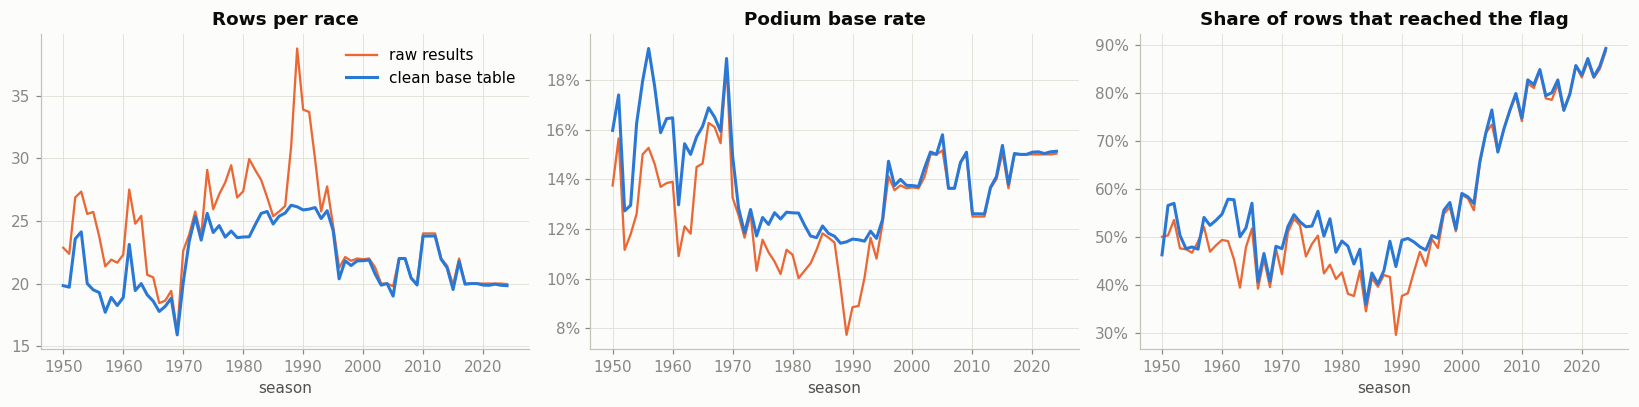

In [24]:
season_clean = base.groupby("year").agg(rows=("raceId", "size"), races=("raceId", "nunique"),
                                        podium_rate=("podium", "mean"), finish_rate=("finished", "mean"))
season_clean["rows_per_race"] = season_clean["rows"] / season_clean["races"]
season_raw["finish_rate"] = res_raw.groupby("year")["finished"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title in [(axes[0], "rows_per_race", "Rows per race"),
                       (axes[1], "podium_rate", "Podium base rate"),
                       (axes[2], "finish_rate", "Share of rows that reached the flag")]:
    ax.plot(season_raw.index, season_raw[col], color=C[1], linewidth=1.5, label="raw results")
    ax.plot(season_clean.index, season_clean[col], color=C[0], label="clean base table")
    ax.set_title(title)
    ax.set_xlabel("season")
for ax in axes[1:]:
    pct_axis(ax)
axes[0].legend()
plt.tight_layout()
save_fig("eda_before_after")
plt.show()

**Effect of the cleaning** (orange = raw, blue = clean):
- **Rows per race.** Removing non-starters cuts the oversized fields of the late 1980s and early 1990s: 1989 had about 39 entries per race but only 26 starters. Modern seasons barely change, because almost everyone who enters also starts.
- **Podium rate.** The raw dip to 7.7% in 1989 was caused by rows that never raced. After cleaning, the base rate follows roughly 3 ÷ (cars on the grid). It is about 12% in the large-field 1980s and about 15% today. The 1950s are higher, at 16–19%, because the fields were small and the Indianapolis 500 is gone.
- **Finish rate.** Reliability rose enormously: only about 40–55% of starters reached the flag before 1990, compared with about 85–90% today. A front-row start therefore converted to a podium far less reliably in early decades, so the relationship between features and target **drifts across eras**. This matters for choosing the training window (section 7).

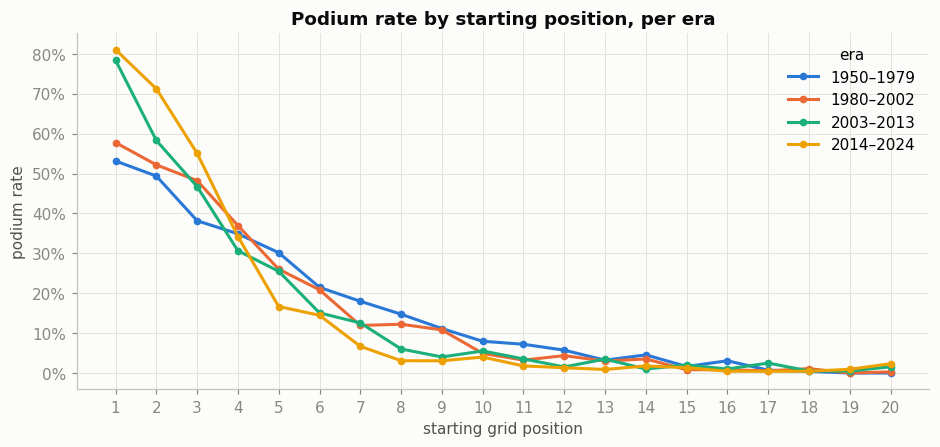

era,1950–1979,1980–2002,2003–2013,2014–2024
grid_pos,,,,
1,53%,58%,78%,81%
2,49%,52%,58%,71%
3,38%,48%,47%,55%
5,30%,26%,26%,17%
10,8%,5%,6%,4%


In [25]:
eras = pd.cut(base["year"], [1949, 1979, 2002, 2013, 2024], labels=["1950–1979", "1980–2002", "2003–2013", "2014–2024"])
by_grid = base[base["pit_lane_start"] == 0].assign(era=eras).query("grid_pos <= 20") \
    .groupby(["era", "grid_pos"], observed=True)["podium"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, era in enumerate(by_grid.columns):
    ax.plot(by_grid.index, by_grid[era], marker="o", markersize=4, color=C[i], label=era)
ax.set_xticks(range(1, 21))
pct_axis(ax)
ax.set_xlabel("starting grid position")
ax.set_ylabel("podium rate")
ax.set_title("Podium rate by starting position, per era")
ax.legend(title="era")
save_fig("eda_podium_by_grid")
plt.show()
display(by_grid.loc[[1, 2, 3, 5, 10]].map("{:.0%}".format))

**Grid position is the dominant signal.**
- The podium rate falls steeply and non-linearly with starting position. Pole converts 53% of the time before 1980 and 81% since 2014; from 10th place the rate is only 4–8%. So grid position is the first feature group.
- The curve **steepens in recent eras**: P1 converts more often in 2014–2024 than before 1980, while the back of the grid converts less often. This is another sign of era drift.
- The shape is roughly exponential, which a linear model on raw `grid_pos` cannot represent. We add a `front_row` indicator to help linear models capture the jump at the front.

## 5. Data-engineering questions

All three answers start from the clean `base` table (one row per starter per race, Indianapolis 500 excluded; built from `results → races → circuits → status`) and add `qualifying` (Q1), `drivers` (Q2) and `constructors` (Q3).

Many circuit and constructor groups are small (100% from 6 races is weak evidence), so rates come with **Wilson 95% confidence intervals**. The cell also defines two small plotting helpers used by all three questions.

In [26]:
def wilson(successes, n, z=1.96):
    """Wilson score interval for a binomial proportion -> (low, high)."""
    successes, n = np.asarray(successes, float), np.asarray(n, float)
    p = np.where(n > 0, successes / np.maximum(n, 1), np.nan)
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def dumbbell(ax, before, after, labels, names, title, xlabel):
    """One row per item: a dot per period, joined by a line (top row = first item)."""
    y = np.arange(len(labels))[::-1]
    ax.hlines(y, before, after, color=GRID, linewidth=2.5, zorder=1)
    for vals, color, name in [(before, C[1], names[0]), (after, C[0], names[1])]:
        ax.scatter(vals, y, s=55, color=color, label=name, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
    pct_axis(ax, "x"); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.legend(loc="lower right", ncol=2); ax.grid(axis="y", visible=False)

def ci_bars(ax, df, group_col, x_labels, names=None, legend_loc="upper left"):
    """Side-by-side bars of df['rate'] with Wilson CIs (df['lo'], df['hi']), one colour per group."""
    for i, (key, g) in enumerate(df.groupby(group_col, sort=False)):
        x = np.arange(len(g)) + (i - 0.5) * 0.38
        ax.bar(x, g["rate"], width=0.36, color=C[i], label=names[key] if names else key)
        ax.errorbar(x, g["rate"], yerr=[g["rate"] - g["lo"], g["hi"] - g["rate"]], fmt="none", ecolor=INK2, capsize=2, linewidth=1)
    ax.set_xticks(range(len(x_labels))); ax.set_xticklabels(x_labels)
    pct_axis(ax); ax.legend(loc=legend_loc); ax.grid(axis="x", visible=False)

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

- **Front-row start** = `grid` 1 or 2, i.e. where the car **actually started**, after penalties. Pit-lane starters (`grid = 0`) are never front-row starts.
- **Conversion rate** = podiums ÷ front-row starts, per circuit, for **1950–2013 vs 2014–2024** (the turbo-hybrid era onwards).
- To compare rankings fairly, a circuit is ranked only with **≥ 10 front-row starts in both periods** (≥ 5 races each).
- **Joins:** `results → races → circuits`, plus `qualifying` for the qualifying-vs-grid comparison below.

Overall front-row → podium conversion: {'1950–2013': '56.6% of 1767 starts', '2014–2024': '76.2% of 453 starts'}
Front-row starters who reached the flag: {'1950–2013': '70%', '2014–2024': '92%'}
16 circuits with >= 10 front-row starts in both periods; Spearman rank correlation between periods = -0.08 (p = 0.76)


starts                rate                rank          
period                         1950–2013 2014–2024 1950–2013 2014–2024 1950–2013 2014–2024
circuit_name                                                                              
Circuit de Monaco                    120        19    0.5000    0.8947        15         1
Suzuka Circuit                        50        18    0.7000    0.8889         1         2
Yas Marina Circuit                    10        22    0.6000    0.8636         6         3
Circuit de Barcelona-Catalunya        45        22    0.6667    0.8182         3         4
Circuit de Spa-Francorchamps          91        22    0.5495    0.8182        12         4
Autódromo José Carlos Pace            62        19    0.5968    0.7895         8         6
Shanghai International Circuit        20        14    0.6500    0.7857         5         7
Circuit Gilles Villeneuve             68        18    0.5294    0.7778        13         8
Silverstone Circuit                   94        24    0.5638    0.7500        10         9
Red Bull Ring                         50        26    0.5200    0.7308        14        10
Autodromo Nazionale di Monza         128        22    0.4922    0.7273        16        11
Albert Park Grand Prix Circuit        36        18    0.5556    0.7222        11        12
Marina Bay Street Circuit             12        18    0.5833    0.7222         9        12
Bahrain International Circuit         18        24    0.6667    0.6667         3        14
Autódromo Hermanos Rodríguez          30        18    0.6000    0.6111         6        15
Hungaroring                           56        22    0.6786    0.5909         2        16

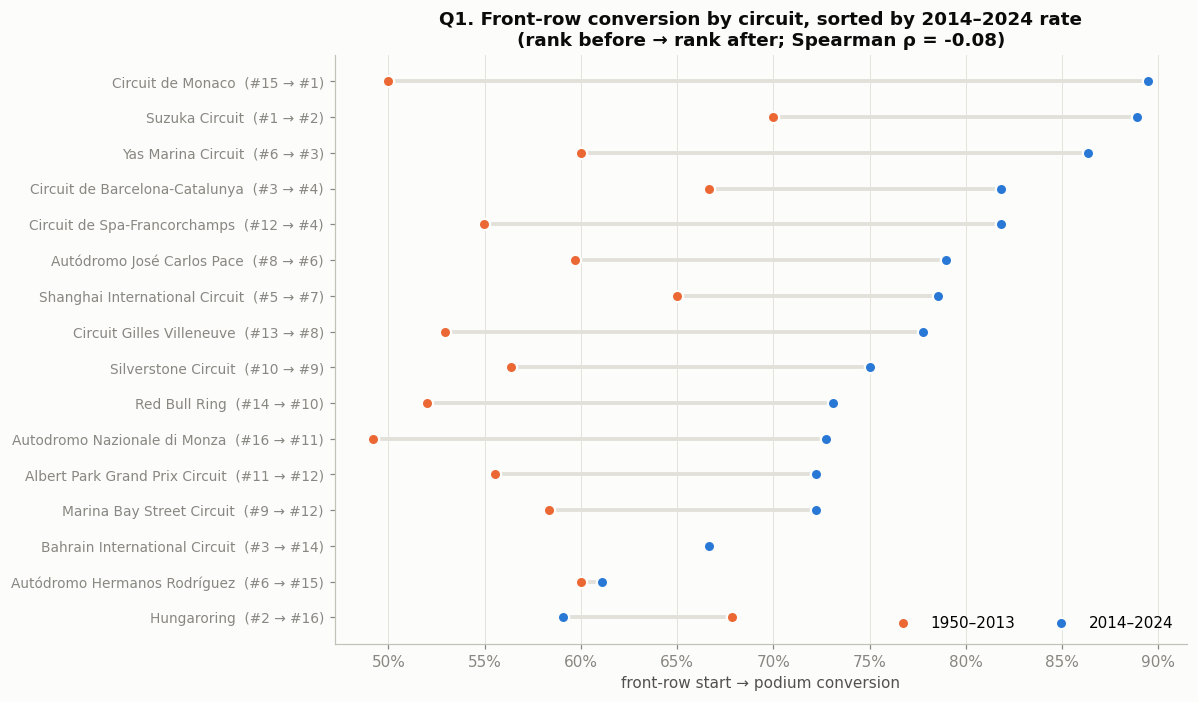

In [27]:
PRE, POST = "1950–2013", "2014–2024"
MIN_STARTS = 10
starters = base[base["pit_lane_start"] == 0].copy()
starters["period"] = np.where(starters["year"] >= 2014, POST, PRE)
front = starters[starters["grid"].isin([1, 2])]
overall = front.groupby("period")["podium"].agg(["size", "mean"])
print("Overall front-row → podium conversion:", {k: f"{v:.1%} of {n:.0f} starts" for k, (n, v) in overall.iterrows()})
print("Front-row starters who reached the flag:", front.groupby("period")["finished"].mean().map("{:.0%}".format).to_dict())

conv = front.groupby(["circuit_name", "period"])["podium"].agg(starts="size", rate="mean").unstack("period")
q1_table = conv[(conv["starts"] >= MIN_STARTS).all(axis=1)].astype({("starts", PRE): int, ("starts", POST): int})
for per in [PRE, POST]:
    q1_table[("rank", per)] = q1_table[("rate", per)].rank(ascending=False, method="min").astype(int)
q1_table = q1_table.sort_values(("rate", POST), ascending=False)
rho, p_rho = stats.spearmanr(q1_table[("rate", PRE)], q1_table[("rate", POST)])
print(f"{len(q1_table)} circuits with >= {MIN_STARTS} front-row starts in both periods; "
      f"Spearman rank correlation between periods = {rho:.2f} (p = {p_rho:.2f})")
display(q1_table)

fig, ax = plt.subplots(figsize=(10, 0.36 * len(q1_table) + 1.2))
dumbbell(ax, q1_table[("rate", PRE)], q1_table[("rate", POST)],
         [f"{c}  (#{a} → #{b})" for c, a, b in zip(q1_table.index, q1_table[("rank", PRE)], q1_table[("rank", POST)])],
         (PRE, POST), f"Q1. Front-row conversion by circuit, sorted by {POST} rate\n(rank before → rank after; Spearman ρ = {rho:.2f})",
         "front-row start → podium conversion")
save_fig("q1_front_row_by_circuit")
plt.show()

**Qualifying position vs grid position.** Qualifying sets the provisional order, but grid penalties (engine/gearbox parts, earlier offences) and disqualifications move drivers. We join `qualifying.position` on `(raceId, driverId)` and use **2003–2024** only, where qualifying coverage is complete (section 2.6).

rows           podium_rate          
period                                             2003–2013 2014–2024   2003–2013 2014–2024
case                                                                                        
qualified AND started front row                          389       426      0.6864    0.7676
qualified front row, started further back (pena...         9        27      0.2222    0.3333
started front row without qualifying there (pro...         9        27      0.5556    0.6667

2014–2024: share of front-row qualifiers who did NOT start from the front row = 6.0%; circuit ranking grid-based vs quali-based Spearman ρ = 0.90


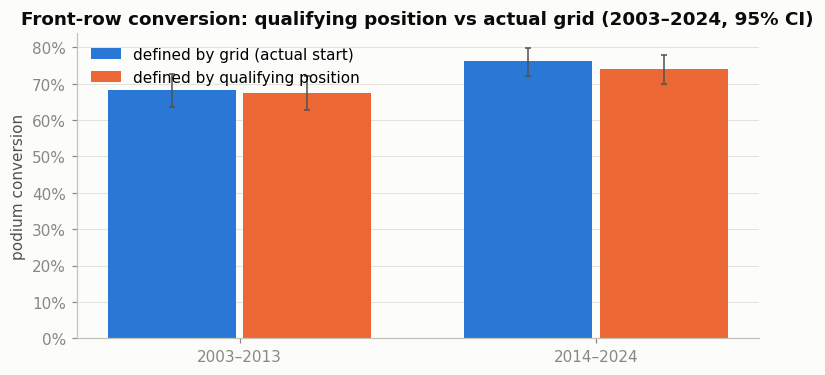

In [28]:
qpos = clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_position"})
fq = starters[starters["year"] >= 2003].merge(qpos, on=["raceId", "driverId"], how="left")
fq["period"] = np.where(fq["year"] >= 2014, POST, "2003–2013")
fq["quali_front"], fq["grid_front"] = fq["quali_position"].isin([1, 2]), fq["grid"].isin([1, 2])
fq["case"] = np.select(
    [fq["quali_front"] & fq["grid_front"], fq["quali_front"] & ~fq["grid_front"], ~fq["quali_front"] & fq["grid_front"]],
    ["qualified AND started front row", "qualified front row, started further back (penalty)", "started front row without qualifying there (promoted)"],
    default="neither")
display(fq[fq["case"] != "neither"].groupby(["case", "period"])["podium"].agg(rows="size", podium_rate="mean").unstack("period"))

by_def = pd.concat({label: fq[fq[col]].groupby("period")["podium"].agg(starts="size", podiums="sum")
                    for label, col in [("defined by grid (actual start)", "grid_front"), ("defined by qualifying position", "quali_front")]},
                   names=["definition"]).reset_index()
by_def["rate"] = by_def["podiums"] / by_def["starts"]
by_def["lo"], by_def["hi"] = wilson(by_def["podiums"], by_def["starts"])

post = fq[fq["period"] == POST]
circ_q = pd.DataFrame({"grid-based rate": post[post["grid_front"]].groupby("circuit_name")["podium"].mean(),
                       "quali-based rate": post[post["quali_front"]].groupby("circuit_name")["podium"].mean(),
                       "starts": post[post["grid_front"]].groupby("circuit_name").size()}).query("starts >= @MIN_STARTS")
rho_q = stats.spearmanr(circ_q["grid-based rate"], circ_q["quali-based rate"])[0]
print(f"{POST}: share of front-row qualifiers who did NOT start from the front row = "
      f"{(post['quali_front'] & ~post['grid_front']).sum() / post['quali_front'].sum():.1%}; "
      f"circuit ranking grid-based vs quali-based Spearman ρ = {rho_q:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ci_bars(ax, by_def, "definition", ["2003–2013", POST])
ax.set_ylabel("podium conversion")
ax.set_title("Front-row conversion: qualifying position vs actual grid (2003–2024, 95% CI)")
save_fig("q1_quali_vs_grid")
plt.show()

**Q1 answer.**

- **A front-row start became much more valuable:** it converted **56.6%** of the time in 1950–2013 (1,767 starts) and **76.2%** in 2014–2024 (453 starts).
- **Best converters in 2014–2024:** **Monaco (89%)**, **Suzuka (89%)**, **Yas Marina (86%)**, then Barcelona and Spa (82%). **Worst:** the **Hungaroring (59%)**, Mexico City (61%) and Bahrain (67%).
- **The ranking changes almost completely.** Across the 16 circuits, the Spearman correlation between the two periods is **ρ = −0.08 (p = 0.76)**: no relationship. **Monaco** went from 15th to **1st**, the **Hungaroring** from 2nd to **last**, Bahrain from 3rd to 14th.
- **Why (our interpretation):** before 2014 only 70% of front-row starters even reached the flag, against 92% since 2014 (printed above). The old ranking was therefore shaped largely by **reliability**; today it mostly reflects **how hard it is to overtake** (Monaco being the extreme). This explanation is plausible but not tested circuit by circuit.
- **Caveat:** each circuit has only 14–26 front-row starts after 2014, so the middle of the ranking is not robust; the top (Monaco, Suzuka) and bottom (Hungaroring) are more trustworthy.
- **Qualifying vs grid (2003–2024).** In 2014–2024, **6.0%** of front-row qualifiers did not start from the front row because of penalties. They reached the podium only **33%** of the time, against **77%** for drivers who qualified *and* started there; drivers *promoted* onto the front row converted **67%**. So the **grid** is the right definition of a front-row start. The qualifying-based circuit ranking is very similar (ρ = 0.90), but its rates are slightly lower because penalised drivers are counted.

**Grain:** driver-race. **Missingness:** none in `grid`; qualifying is incomplete before 2003, so that comparison uses 2003+. **Cutoff:** grid and qualifying position are both known before the start; the podium is the outcome.

### Q2. Do drivers podium more often at home, after controlling for starting position?

- **Home race** = the driver's nationality maps to the **country of the circuit** (taken from `circuits`, not the race name, so the San Marino GP at Imola counts as Italy). **Joins:** `results → drivers` and `results → races → circuits`.
- Demonyms are mapped to countries (British → UK, Dutch → Netherlands, Monegasque → Monaco, West and East German → Germany); an assertion checks that every nationality is covered.
- **Controlling for starting position:** home drivers might simply start further up, so we compare home and away rows **within the same grid band**, and pool those comparisons with the **Mantel–Haenszel odds ratio** (95% CI + Cochran–Mantel–Haenszel test).

In [29]:
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina", "Argentine-Italian": "Argentina",
    "Argentinian": "Argentina", "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium",
    "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China",
    "Colombian": "Colombia", "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands",
    "East German": "Germany", "Finnish": "Finland", "French": "France", "German": "Germany",
    "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy",
    "Japanese": "Japan", "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico",
    "Monegasque": "Monaco", "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal",
    "Rhodesian": "Rhodesia", "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain",
    "Swedish": "Sweden", "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
unmapped = set(clean["drivers"]["nationality"]) - set(NATIONALITY_TO_COUNTRY)
assert not unmapped, f"unmapped nationalities: {unmapped}"

base = base.merge(clean["drivers"][["driverId", "nationality", "dob", "surname", "forename"]], on="driverId", how="left")
base["driver_country"] = base["nationality"].map(NATIONALITY_TO_COUNTRY)
base["home_race"] = (base["driver_country"] == base["circuit_country"]).astype(int)

GRID_BINS = [0, 1, 2, 3, 5, 8, 12, 18, 100]
GRID_LABELS = ["P1", "P2", "P3", "P4–5", "P6–8", "P9–12", "P13–18", "P19+"]
base["grid_band"] = pd.cut(base["grid_pos"], GRID_BINS, labels=GRID_LABELS)
print(f"home-race rows: {base['home_race'].sum():,} of {len(base):,} ({base['home_race'].mean():.1%}); "
      f"countries with at least one home row: {base.loc[base['home_race'] == 1, 'driver_country'].nunique()}")

home-race rows: 1,931 of 24,586 (7.9%); countries with at least one home row: 25


,analysis,rows,home rows,home podium rate,away podium rate,odds ratio,CI low,CI high,p-value
0,"1 · all starters, no control (naive)",24586,1931,0.1191,0.1381,0.8438,NaN,NaN,NaN
1,"2 · all starters, controlled for grid band",24586,1931,0.1191,0.1381,0.9639,0.8101,1.1469,0.7146
2,3 · controlled for grid band × era,24586,1931,0.1191,0.1381,0.9412,0.7909,1.1200,0.5297
3,"4 · only drivers who have a home race, grid band",20444,1931,0.1191,0.1445,0.9546,0.8011,1.1376,0.6386
4,"5 · same driver at home vs away, grid band × d...",20444,1931,0.1191,0.1445,1.0006,0.8245,1.2143,0.9656
5,"6 · modern era 2003–2024, grid band × driver",7011,364,0.1429,0.1542,0.7811,0.5062,1.2052,0.3208


share of rows starting P13 or worse: home 50.6% vs away 45.5%; median grid: home 13 vs away 12


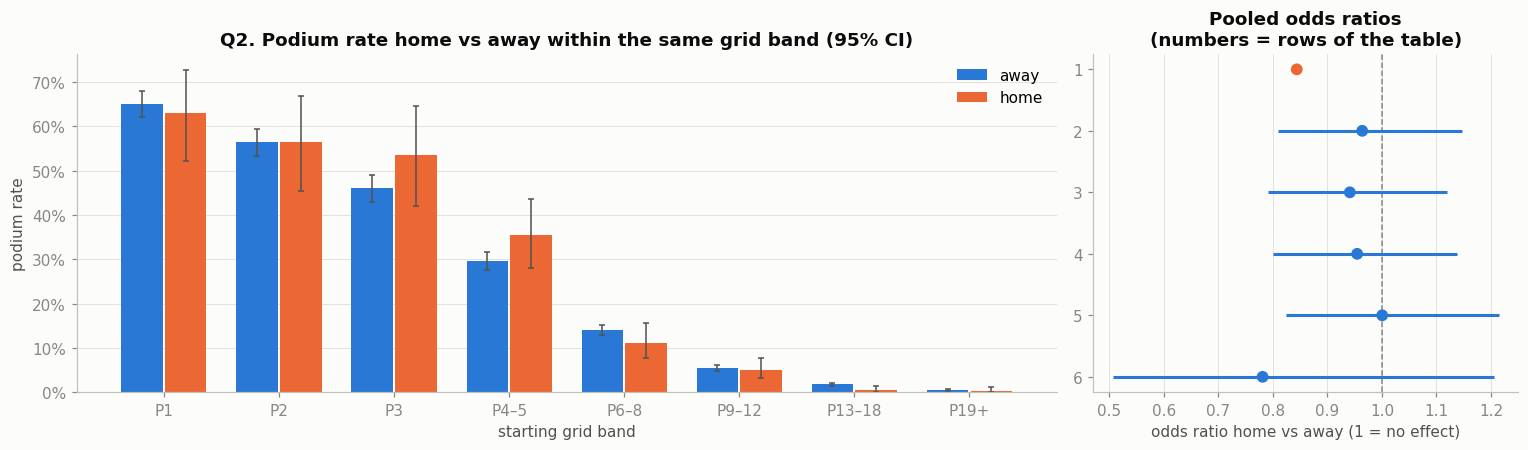

In [30]:
def mantel_haenszel(df, strata, exposure="home_race", outcome="podium"):
    """Pooled odds ratio across strata + 95% CI (Robins-Breslow-Greenland) + CMH chi-square test."""
    R = S = PR = PS_QR = QS = 0.0
    a_sum = e_sum = v_sum = 0.0
    for _, g in df.groupby(strata, observed=True):
        a = ((g[exposure] == 1) & (g[outcome] == 1)).sum(); b = ((g[exposure] == 1) & (g[outcome] == 0)).sum()
        c = ((g[exposure] == 0) & (g[outcome] == 1)).sum(); d = ((g[exposure] == 0) & (g[outcome] == 0)).sum()
        n = a + b + c + d
        if n < 2 or (a + b) == 0 or (c + d) == 0:
            continue
        r, s = a * d / n, b * c / n
        p, q = (a + d) / n, (b + c) / n
        R += r; S += s; PR += p * r; PS_QR += p * s + q * r; QS += q * s
        a_sum += a; e_sum += (a + b) * (a + c) / n
        v_sum += (a + b) * (c + d) * (a + c) * (b + d) / (n**2 * (n - 1))
    or_mh = R / S
    se = np.sqrt(PR / (2 * R**2) + PS_QR / (2 * R * S) + QS / (2 * S**2))
    chi2 = (abs(a_sum - e_sum) - 0.5) ** 2 / v_sum
    return {"odds ratio": or_mh, "CI low": or_mh * np.exp(-1.96 * se), "CI high": or_mh * np.exp(1.96 * se),
            "p-value": stats.chi2.sf(chi2, 1)}

def naive_or(df):
    t = pd.crosstab(df["home_race"], df["podium"])
    return {"odds ratio": (t.loc[1, 1] * t.loc[0, 0]) / (t.loc[1, 0] * t.loc[0, 1]), "CI low": np.nan, "CI high": np.nan, "p-value": np.nan}

has_home = base.groupby("driverId")["home_race"].transform("max") == 1
base["era_band"] = pd.cut(base["year"], [1949, 1979, 2002, 2013, 2024], labels=["1950–79", "1980–2002", "2003–13", "2014–24"])
analyses = [
    ("1 · all starters, no control (naive)", base, None),
    ("2 · all starters, controlled for grid band", base, ["grid_band"]),
    ("3 · controlled for grid band × era", base, ["grid_band", "era_band"]),
    ("4 · only drivers who have a home race, grid band", base[has_home], ["grid_band"]),
    ("5 · same driver at home vs away, grid band × driver", base[has_home], ["grid_band", "driverId"]),
    ("6 · modern era 2003–2024, grid band × driver", base[has_home & (base["year"] >= 2003)], ["grid_band", "driverId"]),
]
q2_table = pd.DataFrame([{"analysis": label, "rows": len(df), "home rows": int(df["home_race"].sum()),
                          "home podium rate": df.loc[df["home_race"] == 1, "podium"].mean(),
                          "away podium rate": df.loc[df["home_race"] == 0, "podium"].mean(),
                          **(mantel_haenszel(df, strata) if strata else naive_or(df))}
                         for label, df, strata in analyses])
display(q2_table)

back = base.groupby("home_race")["grid_pos"].apply(lambda g: (g >= 13).mean())
print(f"share of rows starting P13 or worse: home {back[1]:.1%} vs away {back[0]:.1%}; "
      f"median grid: home {base.loc[base['home_race'] == 1, 'grid_pos'].median():.0f} vs away {base.loc[base['home_race'] == 0, 'grid_pos'].median():.0f}")

band = base.groupby(["home_race", "grid_band"], observed=True)["podium"].agg(podiums="sum", rows="size").reset_index()
band["rate"] = band["podiums"] / band["rows"]
band["lo"], band["hi"] = wilson(band["podiums"], band["rows"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 1.3]})
ci_bars(axes[0], band, "home_race", GRID_LABELS, names={0: "away", 1: "home"}, legend_loc="upper right")
axes[0].set_xlabel("starting grid band"); axes[0].set_ylabel("podium rate")
axes[0].set_title("Q2. Podium rate home vs away within the same grid band (95% CI)")
ax, t = axes[1], q2_table.iloc[::-1].reset_index(drop=True)
ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
ax.hlines(t.index, t["CI low"], t["CI high"], color=C[0], linewidth=2)
ax.scatter(t["odds ratio"], t.index, color=[C[1] if np.isnan(lo) else C[0] for lo in t["CI low"]], s=45, zorder=3)
ax.set_yticks(t.index); ax.set_yticklabels([s.split(" · ")[0] for s in t["analysis"]])
ax.set_xlabel("odds ratio home vs away (1 = no effect)")
ax.set_title("Pooled odds ratios\n(numbers = rows of the table)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig("q2_home_advantage")
plt.show()

**Q2 answer: no, there is no measurable home advantage once starting position is controlled for.**

| analysis | odds ratio (95% CI) | reading |
|---|---|---|
| 1 · naive, no control | 0.84 | home drivers podium *less* often (11.9% vs 13.8%) |
| 2 · within the same grid band | 0.96 (0.81–1.15), p = 0.71 | no effect |
| 5 · same driver, same grid band | **1.00 (0.82–1.21), p = 0.97** | no effect at all |
| 6 · same, 2003–2024 only | 0.78 (0.51–1.21), p = 0.32 | no effect (wide CI) |

- **The naive comparison points the "wrong" way** because home races attract many one-off local entrants (especially in the 1950s–80s) who start at the back: 50.6% of home rows start P13 or worse, against 45.5% of away rows.
- **Within the same grid band** (analysis 2) the odds ratio is 0.96, with a CI comfortably including 1. The **strictest** comparison, the **same driver** at home vs away from the same band (analysis 5), gives exactly **1.00**.
- Individual bands differ a little (P3 and P4–5 slightly higher at home, P6–8 lower), but all their CIs overlap: noise. Any "home advantage" acts *before* the race (qualifying, who enters), not in converting a starting position into a podium.

This is an association analysis, not a causal estimate. **Grain:** one row per starter per race. **Missingness:** nationality is never missing and every nationality is mapped; drivers whose country never hosted a race are excluded in analyses 4–6. **Cutoff:** nationality and grid are known before the start.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Definition (from the brief):** a mechanical retirement is a **race start** that ended early because **a component of the car failed**; crashes, driver errors and regulation decisions are excluded.

- **Denominator:** race starts = rows of `base` (non-starters `F`/`W` already removed). **Numerator:** starts whose `status` is a component failure.
- **Joins:** `results → status` (reason), `results → races` (season), `results → constructors` (team).
- **All 139 status values are mapped explicitly**; assertions fail if any status is unmapped or in two groups. Statuses whose cause is ambiguous get their own class, so the answer is checked with a **strict** definition (component failures only) and a **broad** one (strict + ambiguous).

In [31]:
STATUS_GROUPS = {
    "mechanical": [
        "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
        "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure", "Throttle",
        "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak", "Water leak", "Fuel pump",
        "Track rod", "Oil pressure", "Engine fire", "Engine misfire", "Pneumatics", "Wheel bearing", "Fuel system",
        "Oil line", "Launch control", "Fuel", "Power loss", "Vibrations", "Drivetrain", "Ignition", "Chassis", "Battery",
        "Halfshaft", "Crankshaft", "Alternator", "Oil pump", "Fuel leak", "Injection", "Distributor", "Turbo",
        "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto",
        "Supercharger", "Power Unit", "ERS", "Brake duct", "Cooling system", "Fire", "Seat", "Driver Seat",
        "Safety belt", "Wheel rim", "Handling",
    ],
    # could be a component failure OR the result of contact / debris / pit error -> sensitivity check
    "ambiguous (possibly mechanical)": ["Wheel", "Tyre", "Rear wing", "Undertray", "Stalled", "Retired"],
    "accident / damage": ["Accident", "Collision", "Spun off", "Collision damage", "Damage", "Debris", "Puncture",
                          "Tyre puncture", "Front wing", "Broken wing", "Fatal accident"],
    "team operational error": ["Wheel nut", "Out of fuel", "Fuel rig", "Refuelling"],
    "regulation / sporting": ["Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify",
                              "Did not prequalify", "Withdrew", "Not classified", "Not restarted",
                              "Safety", "Safety concerns"],
    "driver health": ["Physical", "Injured", "Injury", "Driver unwell", "Illness", "Eye injury"],
}
status_map = {s: grp for grp, items in STATUS_GROUPS.items() for s in items}
all_status = clean["status"]["status"]
status_map.update({s: "finished" for s in all_status[is_finished(all_status)]})
missing_map = set(all_status) - set(status_map)
assert not missing_map, f"unmapped statuses: {missing_map}"
dupe_map = [s for s in all_status if sum(s in v for v in STATUS_GROUPS.values()) > 1]
assert not dupe_map, f"statuses in two groups: {dupe_map}"
base["status_group"] = base["status"].map(status_map)

print(f"all {len(all_status)} status values mapped into {len(set(status_map.values()))} groups\n")
for group, members in pd.Series(status_map).groupby(lambda s: status_map[s]):
    print(f"{group:>32}: {', '.join(sorted(members.index))}")

all 139 status values mapped into 7 groups

               accident / damage: Accident, Broken wing, Collision, Collision damage, Damage, Debris, Fatal accident, Front wing, Puncture, Spun off, Tyre puncture
 ambiguous (possibly mechanical): Rear wing, Retired, Stalled, Tyre, Undertray, Wheel
                   driver health: Driver unwell, Eye injury, Illness, Injured, Injury, Physical
                        finished: +1 Lap, +10 Laps, +11 Laps, +12 Laps, +13 Laps, +14 Laps, +15 Laps, +16 Laps, +17 Laps, +18 Laps, +19 Laps, +2 Laps, +20 Laps, +21 Laps, +22 Laps, +23 Laps, +24 Laps, +25 Laps, +26 Laps, +29 Laps, +3 Laps, +30 Laps, +38 Laps, +4 Laps, +42 Laps, +44 Laps, +46 Laps, +49 Laps, +5 Laps, +6 Laps, +7 Laps, +8 Laps, +9 Laps, Finished
                      mechanical: Alternator, Axle, Battery, Brake duct, Brakes, CV joint, Chassis, Clutch, Cooling system, Crankshaft, Differential, Distributor, Driver Seat, Driveshaft, Drivetrain, ERS, Electrical, Electronics, Engine, Engine fi

Field-wide mechanical-retirement rate per start: {'2014–2021': '8.9%', '2022–2024': '5.5%'} | broad: {'2014–2021': '10.6%', '2022–2024': '6.7%'}
2014–2021: top 3 (strict) = Lotus F1 17.3%, Toro Rosso 16.1%, Renault 13.1% | Spearman strict vs broad ranking = 0.95
2022–2024: top 3 (strict) = Alfa Romeo 12.5%, Alpine F1 Team 10.4%, AlphaTauri 6.8% | Spearman strict vs broad ranking = 0.68


,period,constructor,starts,mech,rate,ci_low,ci_high,rank,rate_broad,rank_broad
0,2014–2021,Lotus F1,75,13,0.1733,0.1042,0.2743,1,0.2400,1
1,2014–2021,Toro Rosso,242,39,0.1612,0.1202,0.2127,2,0.1777,2
2,2014–2021,Renault,199,26,0.1307,0.0907,0.1846,3,0.1457,4
3,2014–2021,McLaren,316,41,0.1297,0.0971,0.1713,4,0.1519,3
4,2014–2021,Red Bull,318,34,0.1069,0.0775,0.1457,5,0.1101,7
5,2014–2021,Sauber,199,21,0.1055,0.0701,0.1559,6,0.1307,5
6,2014–2021,AlphaTauri,77,7,0.0909,0.0447,0.1760,7,0.1039,8
7,2014–2021,Racing Point,75,6,0.0800,0.0372,0.1637,8,0.0800,11
8,2014–2021,Haas F1 Team,241,18,0.0747,0.0478,0.1150,9,0.1120,6
9,2014–2021,Williams,319,23,0.0721,0.0485,0.1059,10,0.0878,10


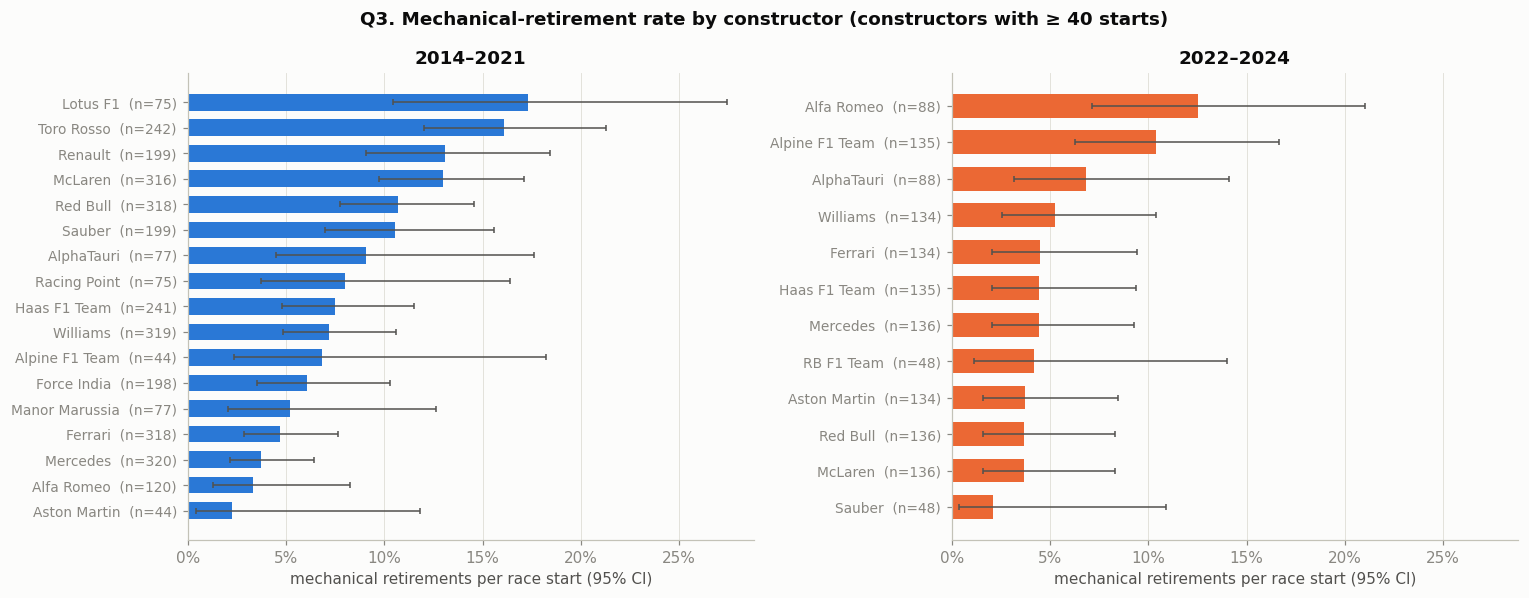

period,2014–2021,2022–2024
lineage,,
Toro Rosso → AlphaTauri → RB,14.4%,5.9%
Lotus F1 → Renault → Alpine,13.2%,10.4%
McLaren,13.0%,3.7%
Red Bull,10.7%,3.7%
Sauber ↔ Alfa Romeo,7.8%,8.8%
Haas F1 Team,7.5%,4.4%
Williams,7.2%,5.2%
Force India → Racing Point → Aston Martin,6.0%,3.7%
Ferrari,4.7%,4.5%


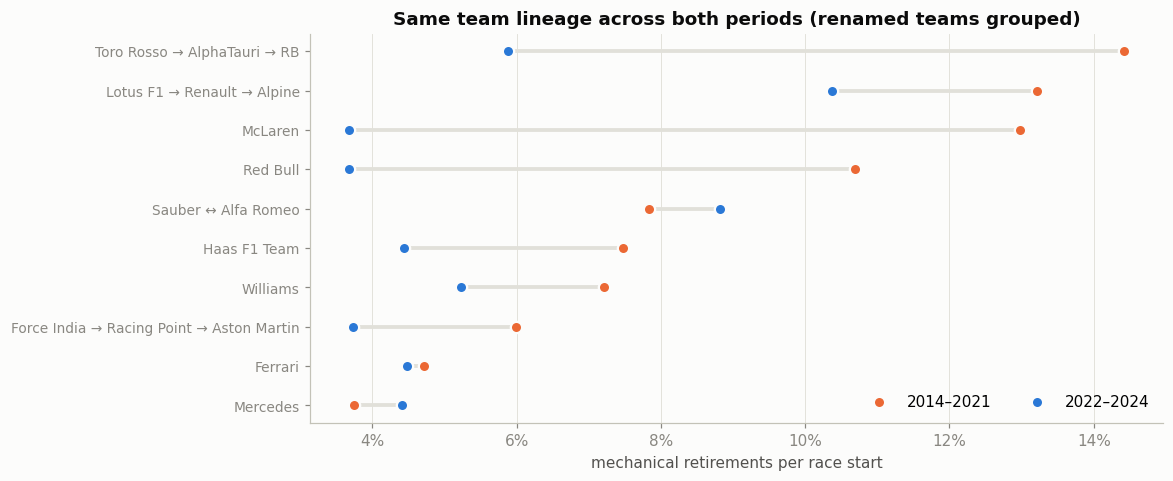

In [32]:
LINEAGE = {"Force India": "Force India → Racing Point → Aston Martin", "Racing Point": "Force India → Racing Point → Aston Martin",
           "Aston Martin": "Force India → Racing Point → Aston Martin",
           "Toro Rosso": "Toro Rosso → AlphaTauri → RB", "AlphaTauri": "Toro Rosso → AlphaTauri → RB", "RB F1 Team": "Toro Rosso → AlphaTauri → RB",
           "Lotus F1": "Lotus F1 → Renault → Alpine", "Renault": "Lotus F1 → Renault → Alpine", "Alpine F1 Team": "Lotus F1 → Renault → Alpine",
           "Sauber": "Sauber ↔ Alfa Romeo", "Alfa Romeo": "Sauber ↔ Alfa Romeo",
           "Marussia": "Marussia → Manor", "Manor Marussia": "Marussia → Manor"}
P1, P2 = "2014–2021", "2022–2024"

mod = base[base["year"].between(2014, 2024)].merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
mod["period"] = np.where(mod["year"] <= 2021, P1, P2)
mod["mech_strict"] = (mod["status_group"] == "mechanical").astype(int)
mod["mech_broad"] = mod["status_group"].isin(["mechanical", "ambiguous (possibly mechanical)"]).astype(int)
mod["lineage"] = mod["constructor"].map(LINEAGE).fillna(mod["constructor"])

def mech_rates(df, by, min_starts=40):
    g = df.groupby([by, "period"]).agg(starts=("mech_strict", "size"), mech=("mech_strict", "sum"),
                                       rate=("mech_strict", "mean"), rate_broad=("mech_broad", "mean")).reset_index()
    g["ci_low"], g["ci_high"] = wilson(g["mech"], g["starts"])
    g = g[g["starts"] >= min_starts]
    g["rank"] = g.groupby("period")["rate"].rank(ascending=False, method="min").astype(int)
    g["rank_broad"] = g.groupby("period")["rate_broad"].rank(ascending=False, method="min").astype(int)
    return g.sort_values(["period", "rate"], ascending=[True, False])

q3 = mech_rates(mod, "constructor")
print("Field-wide mechanical-retirement rate per start:", mod.groupby("period")["mech_strict"].mean().map("{:.1%}".format).to_dict(),
      "| broad:", mod.groupby("period")["mech_broad"].mean().map("{:.1%}".format).to_dict())
for period, g in q3.groupby("period"):
    print(f"{period}: top 3 (strict) =", ", ".join(f"{c} {r:.1%}" for c, r in zip(g["constructor"][:3], g["rate"][:3])),
          f"| Spearman strict vs broad ranking = {stats.spearmanr(g['rate'], g['rate_broad'])[0]:.2f}")
display(q3[["period", "constructor", "starts", "mech", "rate", "ci_low", "ci_high", "rank", "rate_broad", "rank_broad"]].reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for ax, (period, g), color in zip(axes, q3.groupby("period"), [C[0], C[1]]):
    g = g.sort_values("rate")
    ax.barh(range(len(g)), g["rate"], xerr=[g["rate"] - g["ci_low"], g["ci_high"] - g["rate"]], color=color, height=0.65,
            error_kw={"ecolor": INK2, "capsize": 2, "linewidth": 1})
    ax.set_yticks(range(len(g))); ax.set_yticklabels([f"{c}  (n={n})" for c, n in zip(g["constructor"], g["starts"])], fontsize=9)
    ax.set_title(period); pct_axis(ax, "x"); ax.set_xlabel("mechanical retirements per race start (95% CI)"); ax.grid(axis="y", visible=False)
fig.suptitle("Q3. Mechanical-retirement rate by constructor (constructors with ≥ 40 starts)", fontweight="bold", color=INK)
plt.tight_layout()
save_fig("q3_mechanical_by_constructor")
plt.show()

lin = mech_rates(mod, "lineage").pivot(index="lineage", columns="period", values="rate").dropna().sort_values(P1, ascending=False)
display(lin.map("{:.1%}".format))
fig, ax = plt.subplots(figsize=(10, 4.6))
dumbbell(ax, lin[P1], lin[P2], lin.index, (P1, P2), "Same team lineage across both periods (renamed teams grouped)",
         "mechanical retirements per race start")
save_fig("q3_lineage")
plt.show()

**Q3 answer.**

| | highest mechanical-retirement rate (strict definition) | field-wide rate |
|---|---|---|
| **2014–2021** | **Lotus F1 17.3%** (2014–15), **Toro Rosso 16.1%**, **Renault 13.1%**, McLaren 13.0% | 8.9% of starts |
| **2022–2024** | **Alfa Romeo 12.5%**, **Alpine 10.4%**, AlphaTauri 6.8% | 5.5% of starts |

- **2014–2021:** the least reliable cars were the teams with immature hybrid power units: Lotus, Toro Rosso and Renault all used Renault engines, McLaren used Honda in 2015–2017. **Mercedes (3.8%)** and **Ferrari (4.7%)** were among the most reliable.
- **2022–2024:** reliability improved across the field (8.9% → 5.5%). **Alpine** (Renault power) is near the top again; **Red Bull and McLaren** dropped to 3.7%, among the lowest.
- **Same organisation across periods** (lineage chart): the Enstone team (Lotus F1 → Renault → Alpine) stayed high in both periods; Toro Rosso → AlphaTauri → RB improved strongly.
- **Robustness:** the 2014–2021 ranking barely changes when ambiguous statuses count as mechanical (Spearman 0.95). For 2022–2024 it is less stable (0.68), because teams sit close together at 2–7% with about 135 starts each; only Alfa Romeo and Alpine stand out clearly.

**Grain:** one row per race start. **Missingness:** status is never missing and every status is mapped. **Cutoff:** status is post-race, so it is used **only** for this question and for *past-race* reliability features, never as a feature of the current race.

## 6. Feature selection & engineering

**The rule for every feature:** it must be known **after qualifying and before the lights go out**.
- **Current race:** only the grid and qualifying. No status, points, laps, pit stops or lap times.
- **Earlier races:** anything, as long as the computation looks strictly backwards: form features use `shift(1)`, standings come from **after the previous round**.

Groups are chosen from the EDA hypotheses (sections 2, 4, 5), checked with evidence in 6.3, and measured after training by the ablation (section 11).

| group | features | why (hypothesis from EDA) |
|---|---|---|
| **grid** | `grid_pos`, `front_row`, `pit_lane_start` | podium rate falls steeply with starting slot (section 4); the front row is a jump |
| **qualifying** | `quali_pos`, `quali_gap_pct`, `grid_vs_quali` | raw pace beyond the slot; Q1 showed penalised front-row qualifiers convert far less |
| **driver form** | podium rate & average finish over the last 5 starts, DNF rate over the last 10, career starts & career podium rate | the same driver tends to be fast for several races |
| **constructor form** | team podium rate & average finish over the last 5 races, mechanical-DNF rate over the last 10 | car performance dominates F1; Q3 showed reliability differs by team |
| **standings** | championship position & points share (driver and team) and wins **before** this race | the season-to-date summary of who is fast this year |
| **context** | `field_size` | base rate ≈ 3 ÷ field size (section 4) |

**Deliberately not used:** `home_race` (Q2: no effect once the grid is controlled; re-tested in section 11), sprint results (only from 2021, never in the ≤ 2019 training data), anything from `lap_times`/`pit_stops` (post-race), and `year` (test seasons lie outside the training range).

In [33]:
TRAIN_END, VAL_YEARS, TEST_START = 2019, (2020, 2021), 2022   # justified in section 7

fe = base.sort_values(["date", "raceId", "grid_pos"]).reset_index(drop=True)

# finishing position among starters, normalised to 0 (won) .. 1 (last): comparable across field sizes and eras
finish_rank = fe.groupby("raceId")["positionOrder"].rank(method="first")
fe["finish_pct"] = (finish_rank - 1) / (fe["field_size"] - 1)
fe["dnf"] = 1 - fe["finished"]
fe["mech_dnf"] = (fe["status_group"] == "mechanical").astype(int)

# ---- grid group (known once the grid is fixed)
fe["front_row"] = (fe["grid_pos"] <= 2).astype(int)

# ---- qualifying group (known after qualifying)
q = clean["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].rename(columns={"position": "quali_pos"})
q["best_lap"] = q[["q1", "q2", "q3"]].min(axis=1)
q["pole_lap"] = q.groupby("raceId")["best_lap"].transform("min")
q["quali_gap_pct"] = 100 * (q["best_lap"] / q["pole_lap"] - 1)
fe = fe.drop(columns="has_quali").merge(q[["raceId", "driverId", "quali_pos", "quali_gap_pct"]], on=["raceId", "driverId"], how="left")
fe["grid_vs_quali"] = fe["grid_pos"] - fe["quali_pos"]          # > 0: dropped back (penalty / pit lane)

print(f"feature table so far: {len(fe):,} rows; quali_pos missing in {fe['quali_pos'].isna().mean():.1%} of rows "
      f"({fe.loc[fe['year'] >= 2003, 'quali_pos'].isna().mean():.2%} from 2003)")

feature table so far: 24,586 rows; quali_pos missing in 57.6% of rows (0.24% from 2003)


### 6.1 Leakage-safe form features (past races only)

`past_mean` is the single helper behind every form feature: group by driver (or constructor), **shift by one race** so the current race is excluded, then average over a rolling window. A driver's first start therefore has no form (`NaN`): nothing is known about them yet.

In [34]:
def past_mean(df, key, col, window=None):
    """Mean of `col` over the previous `window` races of each `key` (expanding if window is None). Current race excluded."""
    shifted = df.groupby(key)[col].shift(1)
    grouped = shifted.groupby(df[key])
    if window is None:
        return grouped.transform(lambda s: s.expanding().mean())
    return grouped.transform(lambda s: s.rolling(window, min_periods=1).mean())

# ---- driver form
fe["drv_podium_rate_last5"] = past_mean(fe, "driverId", "podium", 5)
fe["drv_finish_pct_last5"] = past_mean(fe, "driverId", "finish_pct", 5)
fe["drv_dnf_rate_last10"] = past_mean(fe, "driverId", "dnf", 10)
fe["drv_career_podium_rate"] = past_mean(fe, "driverId", "podium")
fe["drv_career_starts"] = fe.groupby("driverId").cumcount()            # starts before this one

# ---- constructor form: aggregate each team's cars per race first, then roll over the team's races
con_race = (fe.groupby(["raceId", "constructorId"])
              .agg(date=("date", "first"), con_podium=("podium", "mean"),
                   con_finish=("finish_pct", "mean"), con_mech=("mech_dnf", "mean"))
              .reset_index().sort_values(["date", "raceId"]).reset_index(drop=True))
con_race["con_podium_rate_last5"] = past_mean(con_race, "constructorId", "con_podium", 5)
con_race["con_finish_pct_last5"] = past_mean(con_race, "constructorId", "con_finish", 5)
con_race["con_mech_dnf_rate_last10"] = past_mean(con_race, "constructorId", "con_mech", 10)
fe = fe.merge(con_race[["raceId", "constructorId", "con_podium_rate_last5", "con_finish_pct_last5", "con_mech_dnf_rate_last10"]],
              on=["raceId", "constructorId"], how="left")

### 6.2 Standings *before* the race

`driver_standings` and `constructor_standings` are recorded **after** each race, so the row with the same `raceId` already contains this race's result (leakage). We take the standings after the **previous round of the same season** instead.
- **Round 1:** everyone has 0 points and the championship position is genuinely unknown (`NaN`). Drivers who had not scored or entered yet get 0 points, no position.
- Points systems changed many times (8 points for a win in 1950, 25 since 2010), so points are a **share of the leader's points**, comparable across eras.

In [35]:
rounds = clean["races"].sort_values(["year", "round"])[["raceId", "year", "round"]].copy()
rounds["prev_raceId"] = rounds.groupby("year")["raceId"].shift(1)
fe = fe.merge(rounds[["raceId", "prev_raceId"]], on="raceId", how="left")

ds = clean["driver_standings"][["raceId", "driverId", "points", "position", "wins"]].rename(
    columns={"raceId": "prev_raceId", "points": "drv_points_before", "position": "drv_champ_pos_before", "wins": "drv_wins_before"})
ds["drv_leader_points"] = ds.groupby("prev_raceId")["drv_points_before"].transform("max")
cs = clean["constructor_standings"][["raceId", "constructorId", "points", "position"]].rename(
    columns={"raceId": "prev_raceId", "points": "con_points_before", "position": "con_champ_pos_before"})
cs["con_leader_points"] = cs.groupby("prev_raceId")["con_points_before"].transform("max")

fe = fe.merge(ds, on=["prev_raceId", "driverId"], how="left").merge(cs, on=["prev_raceId", "constructorId"], how="left")
for who in ["drv", "con"]:
    pts, lead = fe[f"{who}_points_before"].fillna(0), fe[f"{who}_leader_points"]
    fe[f"{who}_points_share_before"] = np.where(lead > 0, pts / lead, 0.0)
fe["drv_wins_before"] = fe["drv_wins_before"].fillna(0)
fe.loc[fe["year"] < 1958, "con_points_share_before"] = np.nan   # no constructors' championship before 1958

assert not fe.duplicated(["raceId", "driverId"]).any()
print("standings check, round 1 rows: max driver points share =", fe.loc[fe["round"] == 1, "drv_points_share_before"].max(),
      "| champ position known:", int(fe.loc[fe["round"] == 1, "drv_champ_pos_before"].notna().sum()))

standings check, round 1 rows: max driver points share = 0.0 | champ position known: 0


**Proving the features are leakage-safe.**
1. **Independent recomputation:** one driver's form is recomputed from scratch using only races dated *before* the target race, for 200 random rows, and must equal the vectorised value.
2. **The leaky alternative:** we build the *unshifted* standings (same `raceId`, i.e. after this race) and measure how much better they "predict" the podium. A large jump shows that version contains the answer.

In [36]:
def recompute_form(driver_id, race_id, window=5):
    race_date = fe.loc[fe["raceId"] == race_id, "date"].iloc[0]
    past = fe[(fe["driverId"] == driver_id) & (fe["date"] < race_date)].sort_values("date")
    return past["podium"].tail(window).mean() if len(past) else np.nan

rng = np.random.default_rng(RANDOM_STATE)
sample = fe.iloc[rng.choice(len(fe), 200, replace=False)]
recomputed = np.array([recompute_form(d, r) for d, r in zip(sample["driverId"], sample["raceId"])])
assert np.allclose(recomputed, sample["drv_podium_rate_last5"].values, equal_nan=True)
print("200 random rows: vectorised driver form == brute-force recomputation from strictly earlier races ✓")

ds_same = clean["driver_standings"][["raceId", "driverId", "points"]].rename(columns={"points": "pts_after"})
ds_same["lead_after"] = ds_same.groupby("raceId")["pts_after"].transform("max")
leak = fe[(fe["year"] >= 2003) & (fe["year"] <= TRAIN_END)].merge(ds_same, on=["raceId", "driverId"], how="left")
leak["share_after"] = np.where(leak["lead_after"] > 0, leak["pts_after"].fillna(0) / leak["lead_after"], 0)
r1 = leak["round"] == 1
print(f"ROC-AUC of driver points share: BEFORE the race (ours) = {roc_auc_score(leak['podium'], leak['drv_points_share_before']):.3f} | "
      f"AFTER the race (leaky) = {roc_auc_score(leak['podium'], leak['share_after']):.3f} | "
      f"leaky version in round 1 alone = {roc_auc_score(leak.loc[r1, 'podium'], leak.loc[r1, 'share_after']):.3f}")

200 random rows: vectorised driver form == brute-force recomputation from strictly earlier races ✓
ROC-AUC of driver points share: BEFORE the race (ours) = 0.855 | AFTER the race (leaky) = 0.937 | leaky version in round 1 alone = 1.000


The leaky standings reach ROC-AUC **0.937** against **0.855** for ours, and **in round 1 alone** they are a *perfect* predictor (AUC = 1.000): after the first race, the only drivers with points are the ones who just scored them. That is exactly the "information from the future" the brief warns about; our shifted version cannot see the current race.

### 6.3 Evidence for each feature

Computed on the **training seasons only** (≤ 2019), so validation and test never influence feature decisions: univariate ROC-AUC of each feature, binned podium rate ("effect" plots), Spearman correlations (redundancy) and missingness by season.

,feature,group,AUC (oriented),direction,missing (train)
0,quali_pos,qualifying,0.9053,lower → more podiums,0.6308
1,quali_gap_pct,qualifying,0.8867,lower → more podiums,0.6366
2,grid_pos,grid,0.8835,lower → more podiums,0.0000
3,drv_champ_pos_before,standings,0.8370,lower → more podiums,0.1238
4,con_champ_pos_before,standings,0.8296,lower → more podiums,0.1244
5,con_podium_rate_last5,constructor_form,0.8286,higher → more podiums,0.0114
6,drv_podium_rate_last5,driver_form,0.8121,higher → more podiums,0.0298
7,drv_career_podium_rate,driver_form,0.8080,higher → more podiums,0.0298
8,con_finish_pct_last5,constructor_form,0.8073,lower → more podiums,0.0114
9,con_points_share_before,standings,0.8010,higher → more podiums,0.0512


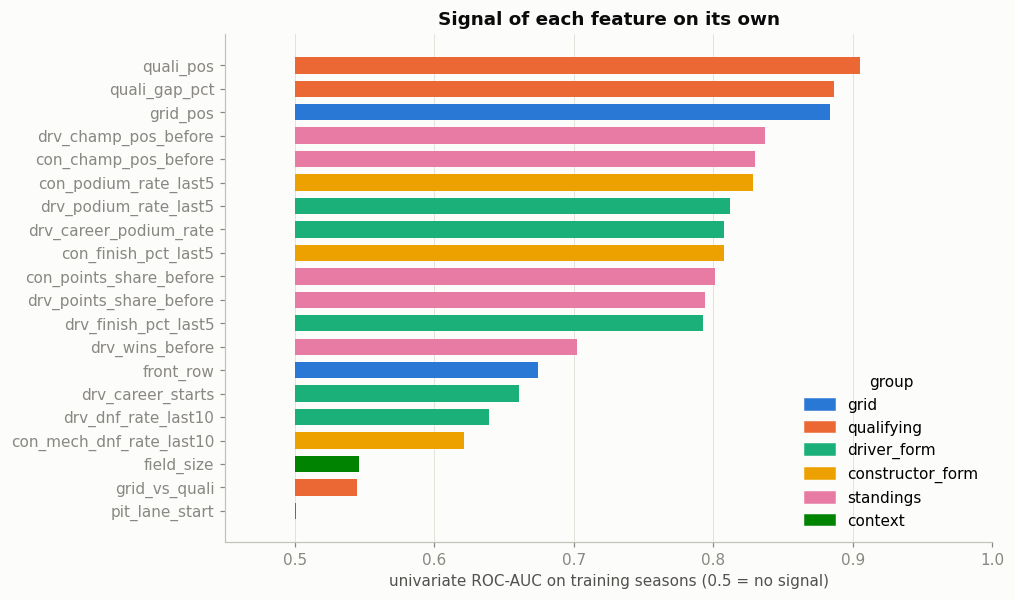

In [37]:
FEATURE_GROUPS = {
    "grid": ["grid_pos", "front_row", "pit_lane_start"],
    "qualifying": ["quali_pos", "quali_gap_pct", "grid_vs_quali"],
    "driver_form": ["drv_podium_rate_last5", "drv_finish_pct_last5", "drv_dnf_rate_last10",
                    "drv_career_starts", "drv_career_podium_rate"],
    "constructor_form": ["con_podium_rate_last5", "con_finish_pct_last5", "con_mech_dnf_rate_last10"],
    "standings": ["drv_champ_pos_before", "drv_points_share_before", "drv_wins_before",
                  "con_champ_pos_before", "con_points_share_before"],
    "context": ["field_size"],
}
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]
GROUP_OF = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
GROUP_COLOR = dict(zip(FEATURE_GROUPS, C))
group_legend = lambda ax, **kw: ax.legend([plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[g]) for g in FEATURE_GROUPS],
                                          FEATURE_GROUPS.keys(), title="group", **kw)

ev = fe[fe["year"] <= TRAIN_END]
uni = []
for f in FEATURES:
    m = ev[f].notna()
    auc = roc_auc_score(ev.loc[m, "podium"], ev.loc[m, f])
    uni.append({"feature": f, "group": GROUP_OF[f], "AUC (oriented)": max(auc, 1 - auc),
                "direction": "higher → more podiums" if auc >= 0.5 else "lower → more podiums", "missing (train)": 1 - m.mean()})
uni = pd.DataFrame(uni).sort_values("AUC (oriented)", ascending=False).reset_index(drop=True)
display(uni)

fig, ax = plt.subplots(figsize=(9, 6))
u = uni.iloc[::-1]
ax.barh(u["feature"], u["AUC (oriented)"] - 0.5, left=0.5, color=[GROUP_COLOR[g] for g in u["group"]], height=0.7)
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("univariate ROC-AUC on training seasons (0.5 = no signal)")
ax.set_title("Signal of each feature on its own")
group_legend(ax, loc="lower right")
ax.grid(axis="y", visible=False)
save_fig("feat_univariate_auc")
plt.show()

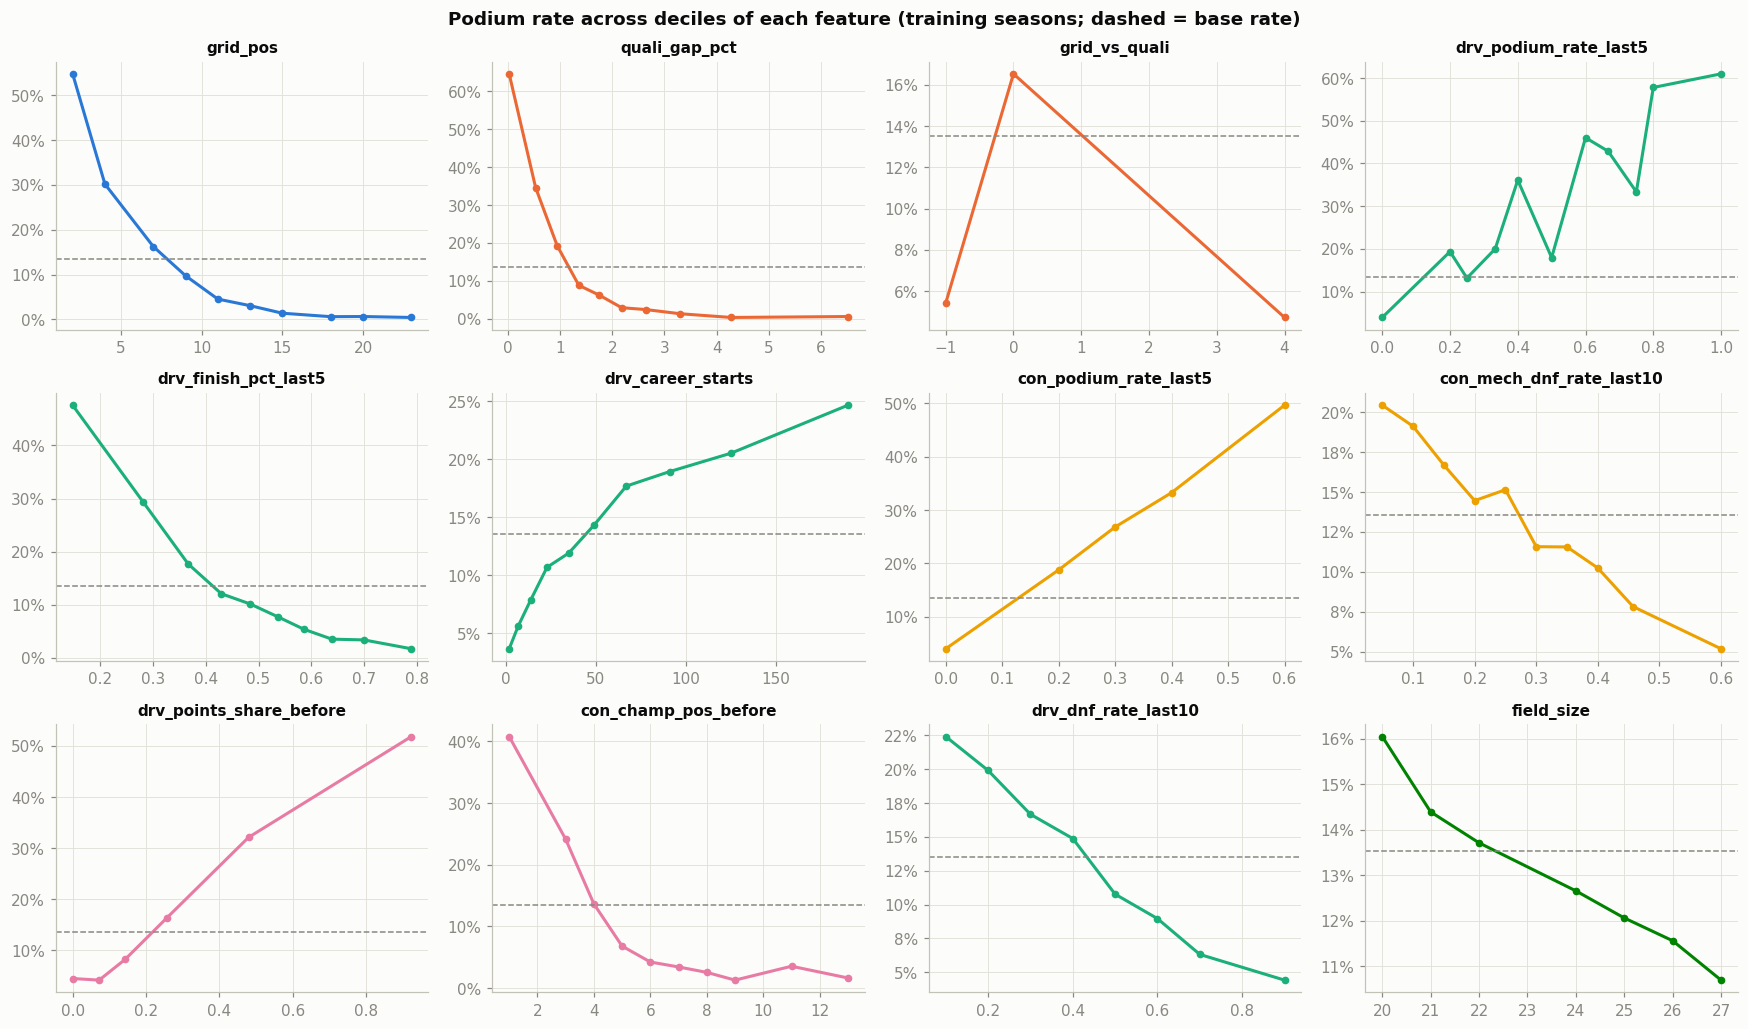

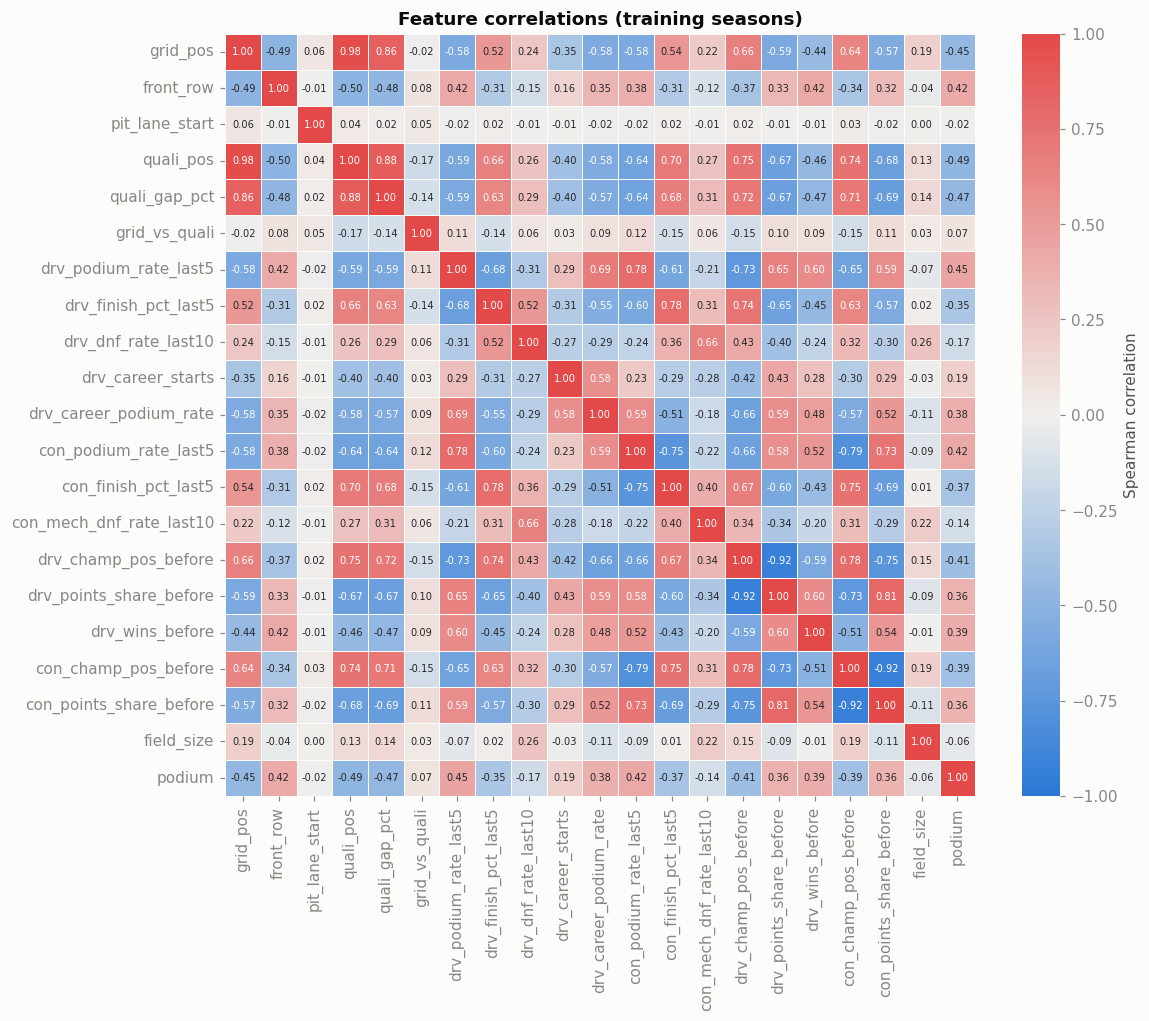

Most correlated feature pairs:
grid_pos                 quali_pos                 0.9800
con_champ_pos_before     con_points_share_before   0.9200
drv_champ_pos_before     drv_points_share_before   0.9200
quali_pos                quali_gap_pct             0.8800
grid_pos                 quali_gap_pct             0.8600
drv_points_share_before  con_points_share_before   0.8100


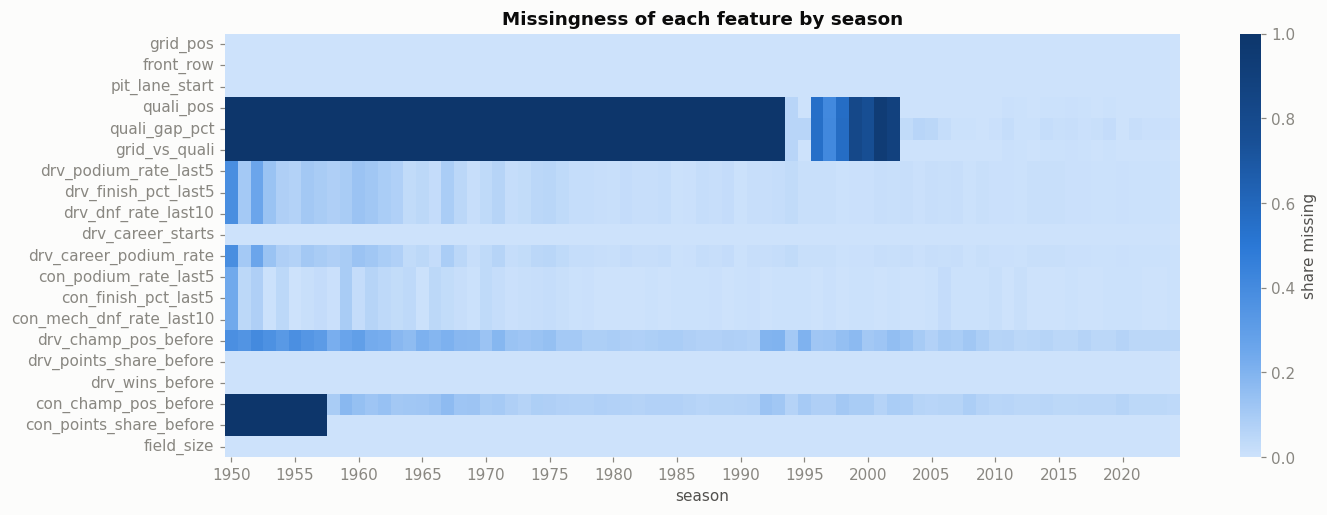

In [38]:
# Effect plots: podium rate across deciles (or values) of each feature
plot_feats = ["grid_pos", "quali_gap_pct", "grid_vs_quali", "drv_podium_rate_last5", "drv_finish_pct_last5",
              "drv_career_starts", "con_podium_rate_last5", "con_mech_dnf_rate_last10", "drv_points_share_before",
              "con_champ_pos_before", "drv_dnf_rate_last10", "field_size"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
for ax, f in zip(axes.ravel(), plot_feats):
    d = ev[[f, "podium"]].dropna()
    key = pd.qcut(d[f], 10, duplicates="drop") if d[f].nunique() > 12 else d[f]
    g = d.groupby(key, observed=True).agg(x=(f, "median"), rate=("podium", "mean"))
    ax.plot(g["x"], g["rate"], marker="o", markersize=4, color=GROUP_COLOR[GROUP_OF[f]])
    ax.axhline(ev["podium"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_title(f, fontsize=10); pct_axis(ax)
fig.suptitle("Podium rate across deciles of each feature (training seasons; dashed = base rate)", fontweight="bold", color=INK)
plt.tight_layout()
save_fig("feat_effect_plots")
plt.show()

# Redundancy: Spearman correlations
corr = ev[FEATURES + ["podium"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Feature correlations (training seasons)")
save_fig("feat_correlations")
plt.show()
pairs = corr.drop(index="podium", columns="podium").where(np.triu(np.ones((len(FEATURES),) * 2, bool), 1)).stack()
print("Most correlated feature pairs:\n" + pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

# Missingness by season
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(fe.groupby("year")[FEATURES].apply(lambda d: d.isna().mean()).T, cmap=SEQ, vmin=0, vmax=1,
            cbar_kws={"label": "share missing"}, ax=ax, xticklabels=5)
ax.set_title("Missingness of each feature by season")
ax.set_xlabel("season")
save_fig("feat_missingness")
plt.show()

**What the evidence says (training seasons only):**
- **Strongest signals:** starting position (`quali_pos` 0.91, `quali_gap_pct` 0.89, `grid_pos` 0.88), then championship position before the race (0.83–0.84), **car strength** (`con_podium_rate_last5` 0.83) and driver form (0.79–0.81). The effect plots are monotone for all of them: the podium rate rises from about 0 in the bottom deciles to 40–60% in the top decile of team or driver form.
- **Weak but kept:** reliability (`*_dnf_rate`, 0.62–0.64), `grid_vs_quali` (0.54), `field_size` (0.55) and `pit_lane_start` (0.50, too rare to matter alone). They plausibly *interact* with position (a front-row start in an unreliable car is less certain); the ablation (section 11) tests whether they help instead of assuming it.
- **Redundancy:** grid ↔ qualifying position (ρ = 0.98) and standings position ↔ points share (0.92). This is fine for regularised linear models and tree ensembles, but importance is **shared** between correlated features (section 12), and removing one group can be compensated by another (section 11).
- **Missingness has structure:** qualifying is missing before 1994 and through most of 1996–2002, standings positions in every round 1, form only at debuts. All are imputed inside the model pipeline **with a missing-indicator column**, so the model still sees that a value was absent (section 8).

In [39]:
ID_COLS = ["raceId", "year", "round", "date", "race_name", "circuit_name", "driverId", "forename", "surname", "constructorId"]
modeling_table = fe[ID_COLS + FEATURES + ["podium"]].copy()
assert not modeling_table.duplicated(["raceId", "driverId"]).any()
modeling_table.to_csv(os.path.join(OUT_DIR, "modeling_table.csv"), index=False)
print(f"modeling table: {modeling_table.shape[0]:,} rows × {len(FEATURES)} features (+ ids, target); "
      f"unique (raceId, driverId) ✓; saved to {os.path.join(OUT_DIR, 'modeling_table.csv')}")
modeling_table.sample(5, random_state=RANDOM_STATE)

modeling table: 24,586 rows × 20 features (+ ids, target); unique (raceId, driverId) ✓; saved to ./modeling_table.csv


,raceId,year,round,date,race_name,circuit_name,driverId,forename,surname,constructorId,grid_pos,front_row,pit_lane_start,quali_pos,quali_gap_pct,grid_vs_quali,drv_podium_rate_last5,drv_finish_pct_last5,drv_dnf_rate_last10,drv_career_starts,drv_career_podium_rate,con_podium_rate_last5,con_finish_pct_last5,con_mech_dnf_rate_last10,drv_champ_pos_before,drv_points_share_before,drv_wins_before,con_champ_pos_before,con_points_share_before,field_size,podium
2559,707,1965,9,1965-10-03,United States Grand Prix,Watkins Glen,360,Bruce,McLaren,170,2,1,0,NaN,NaN,NaN,0.0000,0.5630,0.4000,62,0.3226,0.0000,0.5937,0.4833,7.0000,0.1852,0.0000,5.0000,0.2407,18,0
516,813,1953,6,1953-07-18,British Grand Prix,Silverstone Circuit,687,Peter,Whitehead,87,14,0,0,NaN,NaN,NaN,0.0000,0.6937,0.5000,8,0.1250,0.0000,0.5886,0.1867,NaN,0.0000,0.0000,NaN,NaN,27,0
17078,69,2006,17,2006-10-08,Japanese Grand Prix,Suzuka Circuit,9,Robert,Kubica,2,12,0,0,12.0000,2.4057,0.0000,0.2500,0.5476,0.2500,4,0.2500,0.2000,0.4952,0.1000,16.0000,0.0517,0.0000,5.0000,0.1955,22,0
16114,96,2004,7,2004-05-30,European Grand Prix,Nürburgring,30,Michael,Schumacher,6,1,1,0,1.0000,0.0000,0.0000,0.8000,0.1053,0.1000,200,0.6350,0.7000,0.1158,0.0500,1.0000,1.0000,5.0000,1.0000,1.0000,20,1
6725,524,1979,13,1979-09-09,Italian Grand Prix,Autodromo Nazionale di Monza,207,Mario,Andretti,32,10,0,0,NaN,NaN,NaN,0.0000,0.8759,0.7000,93,0.1935,0.0000,0.7012,0.4833,10.0000,0.2727,0.0000,4.0000,0.4625,24,0


## 7. Train / validation / test split

| set | seasons | used for |
|---|---|---|
| **train** | ≤ 2019 | fitting models and preprocessing |
| **validation** | 2020–2021 | choosing the training window, hyperparameters, thresholds and the final model |
| **test** | 2022–2024 | reported **once**, at the end; never used for any choice |

**Why chronological and not random:**
1. **It mirrors real use:** we predict *future* races from the past. A random split would train on 2023 to predict 2015.
2. **Form and standings are autocorrelated within a season**, so mixing a season across sets would grade the model on races it effectively saw.
3. **All drivers of one race stay in the same set** (rows of one race are not independent: each race has about 3 podiums).
4. **The test seasons are a genuine regime change** (the 2022 ground-effect rules), which a random split would hide.

Validation = the two hybrid-era seasons closest to the test period (2020 was a shortened 17-race COVID season, noted as a limitation).

The cell below also defines the shared tools used by every model: the preprocessing pipeline, the F1-optimal threshold (chosen on validation only) and the metrics.

In [40]:
def make_preprocessor():
    """Median imputation + missing-indicator columns, then standardisation. Fitted on training data only."""
    return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("scale", StandardScaler())])

def make_model(estimator):
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])

def best_f1_threshold(y, p):
    """Probability threshold that maximises F1 (to be applied to VALIDATION predictions only)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(thr[np.nanargmax(f1)])

def top3_precision(race_ids, y, p):
    """Race-level metric: pick the 3 highest-probability drivers of each race; share that really podiumed."""
    d = pd.DataFrame({"raceId": np.asarray(race_ids), "y": np.asarray(y), "p": np.asarray(p)})
    d["r"] = d.groupby("raceId")["p"].rank(ascending=False, method="first")
    return d.loc[d["r"] <= 3, "y"].mean()

def scores(y, p, threshold, race_ids=None):
    pred = (p >= threshold).astype(int)
    out = {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
           "F1": f1_score(y, pred, zero_division=0), "Precision": precision_score(y, pred, zero_division=0),
           "Recall": recall_score(y, pred, zero_division=0)}
    if race_ids is not None:
        out["Top-3 precision"] = top3_precision(race_ids, y, p)
    return out

def xy(df):
    return df[FEATURES], df["podium"].values

train_full = modeling_table[modeling_table["year"] <= TRAIN_END]
val = modeling_table[modeling_table["year"].between(*VAL_YEARS)]
test = modeling_table[modeling_table["year"] >= TEST_START]
X_val, y_val = xy(val)
X_test, y_test = xy(test)

### 7.1 Experiment: which seasons to train on?

All seasons since 1950 give the most data, but section 4 showed strong **era drift** (far lower reliability, a flatter grid-to-podium curve, no qualifying before 1994), so old seasons could *hurt* a model meant for 2022+. We test it: the logistic-regression baseline and default gradient boosting are trained on windows starting at meaningful boundaries, all ending in 2019, and scored on **validation**: **1950** (everything), **1981** (modern constructor era), **1994** (qualifying table starts), **2003** (qualifying complete), **2010** (refuelling ban, current points system).

mean validation PR-AUC over both models: {1950: 0.7179, 1981: 0.7185, 1994: 0.7193, 2003: 0.71, 2010: 0.7075}
chosen training window start: 1994


train rows                                      val PR-AUC                                     val ROC-AUC                    
model       Gradient boosting (default) Logistic regression Gradient boosting (default) Logistic regression Gradient boosting (default) Logistic regression
train start                                                                                                                                                
1950                        22,459.0000         22,459.0000                      0.7047              0.7312                      0.9254              0.9328
1981                        15,339.0000         15,339.0000                      0.6991              0.7380                      0.9236              0.9333
1994                        10,093.0000         10,093.0000                      0.7045              0.7342                      0.9275              0.9328
2003                         6,783.0000          6,783.0000                      0.6763              0.7436                      0.9248              0.9333
2010                         4,268.0000          4,268.0000                      0.6790              0.7359                      0.9246              0.9327

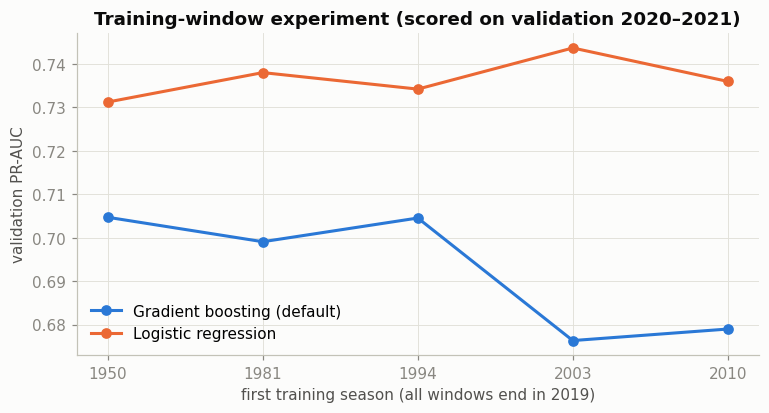

In [41]:
WINDOW_STARTS = [1950, 1981, 1994, 2003, 2010]
window_rows = []
for start in WINDOW_STARTS:
    tr = train_full[train_full["year"] >= start]
    for name, est in [("Logistic regression", LogisticRegression(max_iter=2000)),
                      ("Gradient boosting (default)", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
        p = make_model(est).fit(*xy(tr)).predict_proba(X_val)[:, 1]
        window_rows.append({"train start": start, "model": name, "train rows": len(tr),
                            "val PR-AUC": average_precision_score(y_val, p), "val ROC-AUC": roc_auc_score(y_val, p)})
window_df = pd.DataFrame(window_rows)
mean_by_start = window_df.groupby("train start")["val PR-AUC"].mean()
TRAIN_START = int(mean_by_start.idxmax())
print("mean validation PR-AUC over both models:", mean_by_start.round(4).to_dict())
print("chosen training window start:", TRAIN_START)
display(window_df.pivot(index="train start", columns="model", values=["train rows", "val PR-AUC", "val ROC-AUC"]))

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (name, g) in enumerate(window_df.groupby("model")):
    ax.plot(g["train start"].astype(str), g["val PR-AUC"], marker="o", color=C[i], label=name)
ax.set_xlabel("first training season (all windows end in 2019)")
ax.set_ylabel("validation PR-AUC")
ax.set_title("Training-window experiment (scored on validation 2020–2021)")
ax.legend()
save_fig("split_window_experiment")
plt.show()

**Result:**
- **The short windows are worst:** 2010–2019 (only 4,268 rows) has the lowest mean (0.708), and gradient boosting drops to about 0.68 PR-AUC for both 2003 and 2010. Too little data hurts more than era drift does.
- **The long windows (1950, 1981, 1994) are within 0.002 PR-AUC** of each other on the mean; with only 117 validation podiums that is noise. The two models do not even agree on the best window (logistic regression alone prefers 2003, gradient boosting 1950).
- **We take the best mean, a 1994 start (1994–2019, 10,093 rows)**, chosen automatically by the code. It is the season the qualifying table starts, so every training season has a qualifying table (though 1996–2002 is patchy; imputation + the missing indicator tell the model "no qualifying record" explicitly). It drops the low-reliability 1950s–1980s but keeps enough seasons to learn from. Every shared-drive duplicate (1950–1978) lies outside this window.

,seasons,races,rows,podiums,podium rate
train,1994–2019,470,10093,1410,14.0%
validation,2020–2021,39,775,117,15.1%
test,2022–2024,68,1352,204,15.1%


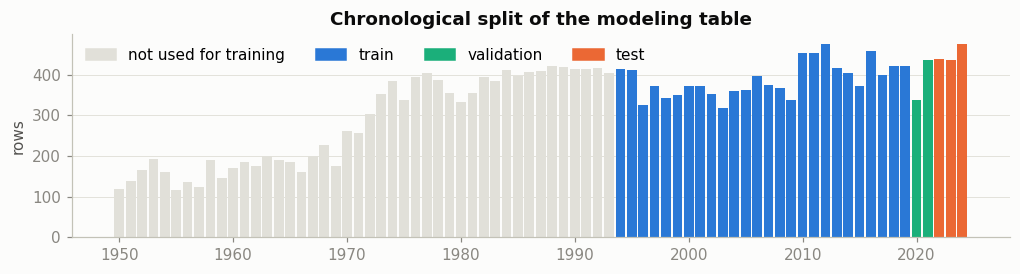

In [42]:
train = train_full[train_full["year"] >= TRAIN_START]
X_train, y_train = xy(train)
display(pd.DataFrame({
    "seasons": [f"{TRAIN_START}–{TRAIN_END}", "2020–2021", f"{TEST_START}–{test['year'].max()}"],
    "races": [d["raceId"].nunique() for d in (train, val, test)],
    "rows": [len(d) for d in (train, val, test)],
    "podiums": [int(d["podium"].sum()) for d in (train, val, test)],
    "podium rate": [f"{d['podium'].mean():.1%}" for d in (train, val, test)],
}, index=["train", "validation", "test"]))

fig, ax = plt.subplots(figsize=(11, 2.4))
per_year = modeling_table.groupby("year").size()
SPLIT_COLOR = lambda y: C[0] if TRAIN_START <= y <= TRAIN_END else C[2] if VAL_YEARS[0] <= y <= VAL_YEARS[1] else C[1] if y >= TEST_START else GRID
ax.bar(per_year.index, per_year.values, color=[SPLIT_COLOR(y) for y in per_year.index], width=0.85)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in [GRID, C[0], C[2], C[1]]],
          ["not used for training", "train", "validation", "test"], loc="upper left", ncol=4)
ax.set_ylabel("rows"); ax.set_title("Chronological split of the modeling table"); ax.grid(axis="x", visible=False)
save_fig("split_timeline")
plt.show()

## 8. Preprocessing & preprocessing-order experiments

### 8.1 The pipeline and its effect on the data

Every model uses the **same** preprocessing inside one scikit-learn `Pipeline`, so it is only ever fitted on the training rows:
1. **Median imputation + missing indicators.** The median is robust to the skewed features (career starts reach 300+, gap-to-pole has a long tail). The indicators matter because missingness has meaning here: missing championship position = round 1, missing form = debut, missing qualifying = no qualifying record. The extra 0/1 column lets the model treat those cases separately.
2. **Standardisation** (mean 0, std 1). Essential for logistic regression and the neural network (scale-sensitive optimisation and regularisation); trees are unaffected (monotone transform).

20 input features -> 32 model inputs; added indicators: ['missingindicator_quali_pos', 'missingindicator_quali_gap_pct', 'missingindicator_grid_vs_quali', 'missingindicator_drv_podium_rate_last5', 'missingindicator_drv_finish_pct_last5', 'missingindicator_drv_dnf_rate_last10', 'missingindicator_drv_career_podium_rate', 'missingindicator_con_podium_rate_last5', 'missingindicator_con_finish_pct_last5', 'missingindicator_con_mech_dnf_rate_last10', 'missingindicator_drv_champ_pos_before', 'missingindicator_con_champ_pos_before']


,missing before,median used,mean before,std before,min before,max before,mean after scaling,std after scaling
grid_pos,0.0000,11.0000,11.3550,6.3460,1.0000,26.0000,-0.0000,1.0000
front_row,0.0000,0.0000,0.0930,0.2900,0.0000,1.0000,-0.0000,1.0000
pit_lane_start,0.0000,0.0000,0.0020,0.0460,0.0000,1.0000,0.0000,1.0000
quali_pos,0.1780,11.0000,11.3450,6.3580,1.0000,26.0000,0.0000,1.0000
quali_gap_pct,0.1910,1.9610,2.5040,2.5720,0.0000,37.7970,-0.0000,1.0000
grid_vs_quali,0.1780,0.0000,-0.0010,1.4140,-9.0000,23.0000,-0.0000,1.0000
drv_podium_rate_last5,0.0120,0.0000,0.1410,0.2490,0.0000,1.0000,0.0000,1.0000
drv_finish_pct_last5,0.0120,0.5170,0.4970,0.2080,0.0000,1.0000,0.0000,1.0000
drv_dnf_rate_last10,0.0120,0.3000,0.3060,0.2200,0.0000,1.0000,0.0000,1.0000
drv_career_starts,0.0000,62.0000,82.6010,72.2750,0.0000,321.0000,0.0000,1.0000


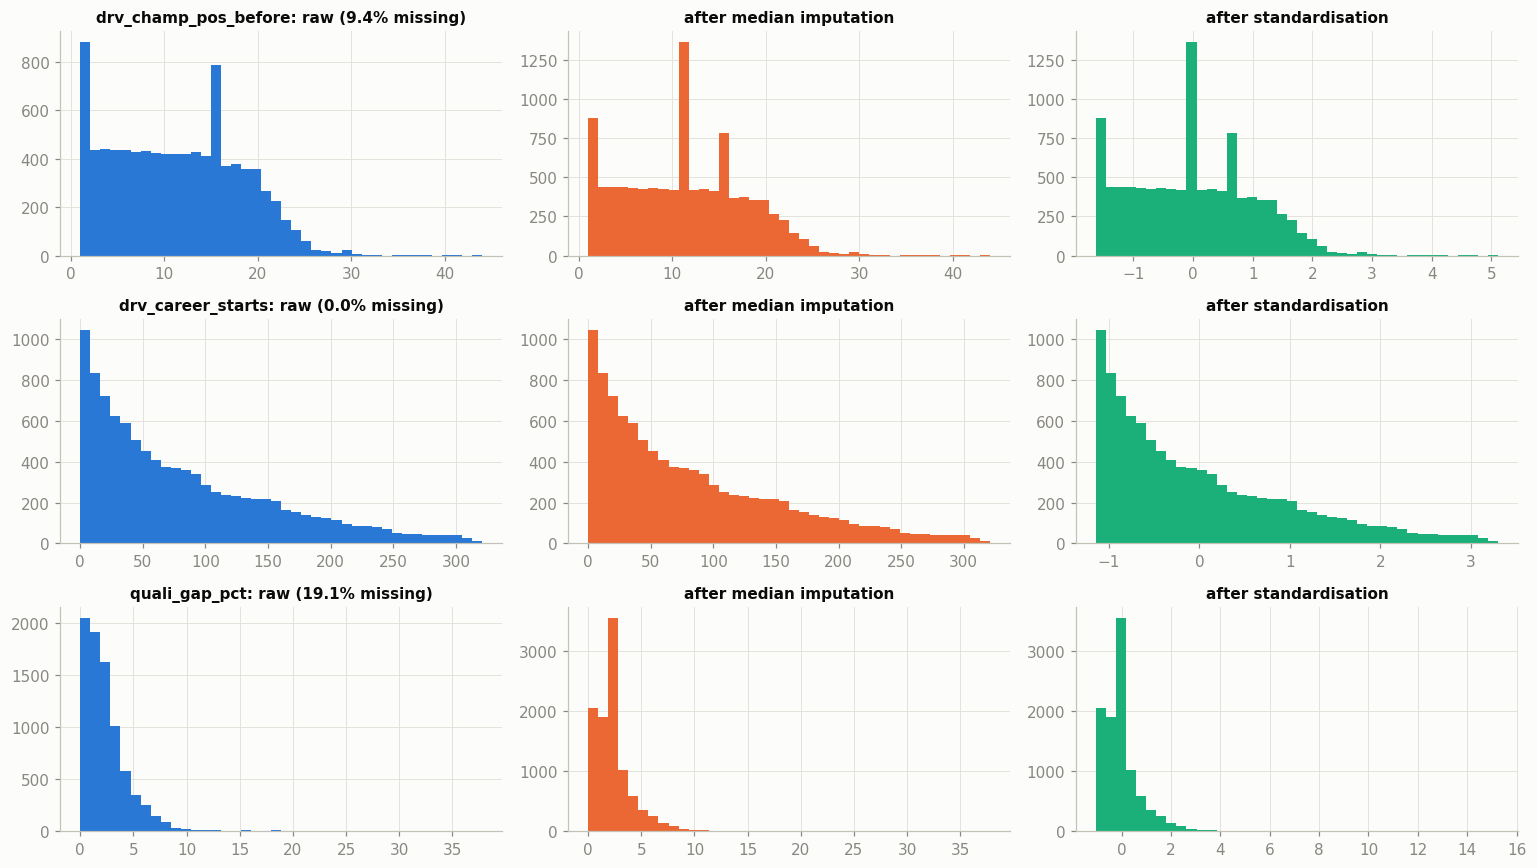

In [43]:
prep = make_preprocessor().fit(X_train)
imputer = prep.named_steps["impute"]
PREP_FEATURE_NAMES = list(prep.get_feature_names_out(FEATURES))
X_imp = pd.DataFrame(imputer.transform(X_train), columns=PREP_FEATURE_NAMES, index=X_train.index)
X_std = pd.DataFrame(prep.transform(X_train), columns=PREP_FEATURE_NAMES, index=X_train.index)
added = [c for c in PREP_FEATURE_NAMES if c.startswith("missingindicator")]
print(f"{len(FEATURES)} input features -> {len(PREP_FEATURE_NAMES)} model inputs; added indicators: {added}")
display(pd.DataFrame({
    "missing before": X_train.isna().mean(), "median used": pd.Series(imputer.statistics_, index=FEATURES),
    "mean before": X_train.mean(), "std before": X_train.std(), "min before": X_train.min(), "max before": X_train.max(),
    "mean after scaling": X_std[FEATURES].mean(), "std after scaling": X_std[FEATURES].std(),
}).round(3))

fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for row, f in enumerate(["drv_champ_pos_before", "drv_career_starts", "quali_gap_pct"]):
    for col, (data, title, color) in enumerate([(X_train[f].dropna(), f"{f}: raw ({X_train[f].isna().mean():.1%} missing)", C[0]),
                                                (X_imp[f], "after median imputation", C[1]), (X_std[f], "after standardisation", C[2])]):
        axes[row, col].hist(data, bins=40, color=color)
        axes[row, col].set_title(title, fontsize=10)
plt.tight_layout()
save_fig("prep_effect")
plt.show()

**Effect of each step:** imputation adds a spike at the median for features with real missingness. The clearest case is `drv_champ_pos_before`, missing for every round 1, which is why the indicator columns are added: otherwise an imputed "median position" would look like a genuine one. Standardisation does not change the *shape* of any distribution, only location and scale, so logistic-regression coefficients and network weights become comparable.

### 8.2 Preprocessing-order experiment 1: fit the preprocessing before or after the split?

A common mistake is to fit the imputer and scaler on the **whole** dataset and split afterwards, so the medians and scaling statistics contain information from validation and test. We compare, with the scale-sensitive logistic regression:
- **A (wrong order):** fit preprocessing on train + validation + test, then train.
- **B (our order):** split first, fit preprocessing on train only.

In [44]:
lr = LogisticRegression(max_iter=2000)
prep_all = make_preprocessor().fit(pd.concat([train, val, test])[FEATURES])   # A: sees val + test
model_a = clone(lr).fit(prep_all.transform(X_train), y_train)
pipe_b = make_model(clone(lr)).fit(X_train, y_train)                         # B: train only

exp1 = []
for label, predict in [("A · preprocessing fitted on ALL data (leaky)", lambda X: model_a.predict_proba(prep_all.transform(X))[:, 1]),
                       ("B · preprocessing fitted on TRAIN only", lambda X: pipe_b.predict_proba(X)[:, 1])]:
    p_val, p_test = predict(X_val), predict(X_test)
    thr = best_f1_threshold(y_val, p_val)
    for split, y, p in [("validation", y_val, p_val), ("test", y_test, p_test)]:
        exp1.append({"order": label, "split": split, **scores(y, p, thr)})
display(pd.DataFrame(exp1).pivot(index="order", columns="split", values=["PR-AUC", "ROC-AUC", "F1"]).round(4))

stat_shift = pd.DataFrame({
    "median (train only)": pipe_b.named_steps["prep"].named_steps["impute"].statistics_,
    "median (all data)": prep_all.named_steps["impute"].statistics_,
    "mean (train only)": pipe_b.named_steps["prep"].named_steps["scale"].mean_[:len(FEATURES)],
    "mean (all data)": prep_all.named_steps["scale"].mean_[:len(FEATURES)],
}, index=FEATURES)
stat_shift["mean shift (in train std)"] = (stat_shift["mean (all data)"] - stat_shift["mean (train only)"]) / X_train.std().values
stat_shift.sort_values("mean shift (in train std)", key=abs, ascending=False).head(6).round(3)

PR-AUC            ROC-AUC                F1           
split                                          test validation    test validation   test validation
order                                                                                              
A · preprocessing fitted on ALL data (leaky) 0.7264     0.7339  0.9375     0.9328 0.6641     0.7132
B · preprocessing fitted on TRAIN only       0.7264     0.7342  0.9374     0.9328 0.6654     0.7132

,median (train only),median (all data),mean (train only),mean (all data),mean shift (in train std)
field_size,22.0000,21.0000,21.6360,21.3310,-0.1700
drv_dnf_rate_last10,0.3000,0.2000,0.3060,0.2760,-0.1340
con_mech_dnf_rate_last10,0.1500,0.1000,0.1690,0.1500,-0.1310
drv_career_starts,62.0000,70.0000,82.6010,92.0180,0.1300
pit_lane_start,0.0000,0.0000,0.0020,0.0060,0.0870
quali_gap_pct,1.9610,1.8360,2.4000,2.3020,-0.0380


**Result of experiment 1:** the two orders give practically the same scores (validation PR-AUC 0.7339 vs 0.7342; test 0.7264 vs 0.7264). The leak is real (fitting on all data shifts the scaling means by up to 0.17 training standard deviations) but small here, because the training set is large and close in distribution to the later seasons. **That does not make A acceptable:** it still uses evaluation-season information, and with less data or more drift the damage grows. We keep **B**, enforced structurally: preprocessing lives *inside* the model `Pipeline`, so it can only be fitted on the data passed to `.fit()`.

### 8.3 Preprocessing-order experiment 2: resample the classes before or after the split?

Podiums are about 15% of rows, and a common response is **random oversampling** (duplicating podium rows until the classes balance). The order matters:
- **A (wrong):** oversample the whole table, then split. Validation is now balanced too, so it no longer looks like real races (about 3 podiums among about 20 drivers).
- **B (correct order):** split, then oversample the **training** rows only.
- **C (no resampling):** keep the natural balance and handle imbalance through the validation-chosen threshold.

For A we report the score on its own oversampled validation set (what a careless pipeline would report) *and* on the real validation seasons.

,model,order,train rows,val podium share,PR-AUC as reported (own val set),PR-AUC on real validation,F1 on real validation,mean predicted p (real val)
0,Logistic regression,A · oversample BEFORE split,17223,0.5126,0.9282,0.7301,0.7072,0.2940
1,Logistic regression,B · oversample AFTER split (train only),17366,0.1510,0.7305,0.7305,0.7072,0.2958
2,Logistic regression,C · no resampling,10093,0.1510,0.7342,0.7342,0.7132,0.1477
3,Gradient boosting,A · oversample BEFORE split,17223,0.5126,0.9169,0.6916,0.7082,0.2162
4,Gradient boosting,B · oversample AFTER split (train only),17366,0.1510,0.6717,0.6717,0.7101,0.2226
5,Gradient boosting,C · no resampling,10093,0.1510,0.7045,0.7045,0.7078,0.1376


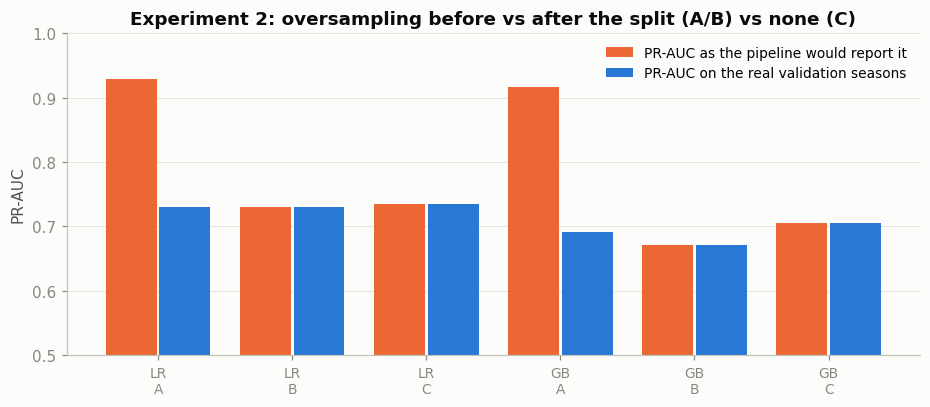

In [45]:
def oversample(df, seed=RANDOM_STATE):
    pos, neg = df[df["podium"] == 1], df[df["podium"] == 0]
    return pd.concat([df, pos.sample(len(neg) - len(pos), replace=True, random_state=seed)])

over_all = oversample(modeling_table[modeling_table["year"] >= TRAIN_START])   # A: before the split
val_a = over_all[over_all["year"].between(*VAL_YEARS)]
variants = [("A · oversample BEFORE split", over_all[over_all["year"] <= TRAIN_END]),
            ("B · oversample AFTER split (train only)", oversample(train)), ("C · no resampling", train)]

exp2 = []
for model_name, est in [("Logistic regression", LogisticRegression(max_iter=2000)),
                        ("Gradient boosting", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
    for label, tr in variants:
        pipe = make_model(clone(est)).fit(*xy(tr))
        p_val = pipe.predict_proba(X_val)[:, 1]
        is_a = label.startswith("A")
        exp2.append({"model": model_name, "order": label, "train rows": len(tr),
                     "val podium share": float(val_a["podium"].mean() if is_a else y_val.mean()),
                     "PR-AUC as reported (own val set)": average_precision_score(val_a["podium"], pipe.predict_proba(val_a[FEATURES])[:, 1])
                                                         if is_a else average_precision_score(y_val, p_val),
                     "PR-AUC on real validation": average_precision_score(y_val, p_val),
                     "F1 on real validation": scores(y_val, p_val, best_f1_threshold(y_val, p_val))["F1"],
                     "mean predicted p (real val)": p_val.mean()})
exp2 = pd.DataFrame(exp2)
display(exp2.round(4))

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(exp2))
ax.bar(x - 0.2, exp2["PR-AUC as reported (own val set)"], width=0.38, color=C[1], label="PR-AUC as the pipeline would report it")
ax.bar(x + 0.2, exp2["PR-AUC on real validation"], width=0.38, color=C[0], label="PR-AUC on the real validation seasons")
ax.set_xticks(x)
ax.set_xticklabels(exp2["model"].map({"Logistic regression": "LR", "Gradient boosting": "GB"}) + "\n" + exp2["order"].str[0], fontsize=9)
ax.set_ylim(0.5, 1.0); ax.set_ylabel("PR-AUC")
ax.set_title("Experiment 2: oversampling before vs after the split (A/B) vs none (C)")
ax.legend(loc="upper right", fontsize=9); ax.grid(axis="x", visible=False)
save_fig("prep_order_oversampling")
plt.show()

**Result of experiment 2:**
- **Oversampling before the split produces a fake result.** Order A reports a validation PR-AUC of **0.93 (LR) and 0.92 (GB)**, but that is an artefact: after oversampling, 52% of the "validation" rows are podiums against 15% in reality, and PR-AUC rises mechanically with the share of positives. On the **real** 2020–2021 races the same models score 0.73 and 0.69.
- **Oversampling does not help even in the correct order.** B is *worse* than no resampling C for both models (LR 0.731 vs 0.734, GB 0.672 vs 0.705), and it distorts the probabilities: the mean predicted podium probability becomes 0.30 against a real rate of 0.15, i.e. about 6 "podium finishers" per race.
- **Decision: no resampling.** The imbalance is handled where it belongs: the **decision threshold** is tuned on validation to maximise F1, and the evaluation uses imbalance-aware metrics (PR-AUC, F1).

## 9. Models

All models use **the same rows** (train 1994–2019), **the same 20 features** and **the same preprocessing pipeline**, so their scores are directly comparable. Hyperparameters are chosen by **validation PR-AUC**, each model's decision threshold maximises **validation F1**, and the test set is not touched until section 10.

**Metrics.**
- **Primary: PR-AUC.** Podiums are about 15% of rows. PR-AUC measures how well the model ranks the real podium finishers at the top, and unlike ROC-AUC it is not flattered by the many easy negatives (back-markers).
- **Secondary: F1 at the validation-chosen threshold:** the quality of the actual yes/no decision, balancing missed podiums against false alarms.
- **Also reported:** ROC-AUC, precision, recall, and a race-level **top-3 precision** (pick the 3 most likely drivers of each race: what share really finished on the podium?).

`register` stores a model's predictions and its validation threshold; `tune` fits every hyperparameter combination and keeps the full log, so every attempt stays visible.

In [46]:
results = {}          # model name -> dict with pipeline, threshold, predictions

def register(name, pipe, kind="model"):
    predict = (lambda X: pipe.predict_proba(X)[:, 1]) if kind == "model" else pipe
    p_tr, p_va, p_te = predict(X_train), predict(X_val), predict(X_test)
    thr = best_f1_threshold(y_val, p_va)
    results[name] = {"pipe": pipe, "threshold": thr, "p_train": p_tr, "p_val": p_va, "p_test": p_te}
    s_tr, s_va = scores(y_train, p_tr, thr), scores(y_val, p_va, thr)
    print(f"{name}: threshold={thr:.3f} | train PR-AUC={s_tr['PR-AUC']:.4f} F1={s_tr['F1']:.4f} | "
          f"val PR-AUC={s_va['PR-AUC']:.4f} ROC-AUC={s_va['ROC-AUC']:.4f} F1={s_va['F1']:.4f}")

def tune(make_estimator, grid):
    rows = []
    for params in grid:
        pipe = make_model(make_estimator(**params)).fit(X_train, y_train)
        p = pipe.predict_proba(X_val)[:, 1]
        rows.append({**{k: str(v) for k, v in params.items()}, "_params": params,
                     "train PR-AUC": average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1]),
                     "val PR-AUC": average_precision_score(y_val, p), "val ROC-AUC": roc_auc_score(y_val, p),
                     "val F1 (best thr)": scores(y_val, p, best_f1_threshold(y_val, p))["F1"]})
    log = pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)
    display(log.drop(columns="_params").round(4))
    print("chosen:", log.loc[0, "_params"])
    return log.loc[0, "_params"]

### 9.1 Reference rule: "the top 3 on the grid finish on the podium"

Not a learned model: the simplest possible reference point that every model must beat to justify its complexity. Its score is `1 / grid_pos` (P1 ranks highest) and its threshold is fixed by the rule itself (grid ≤ 3), not tuned.

In [47]:
register("Reference: grid ≤ 3 rule", lambda X: 1.0 / X["grid_pos"].values, kind="rule")
results["Reference: grid ≤ 3 rule"]["threshold"] = 1 / 3 - 1e-9          # fixed rule: grid 1–3 -> podium

Reference: grid ≤ 3 rule: threshold=0.333 | train PR-AUC=0.5900 F1=0.6238 | val PR-AUC=0.6478 ROC-AUC=0.9102 F1=0.6953


### 9.2 Baseline: logistic regression

**How it works:** `P(podium) = sigmoid(w · x + b)`, a weighted sum of the standardised features squashed to a probability. The weights maximise the likelihood of the training labels, with L2 regularisation (strength `1/C`) keeping them small and stable when features are correlated.

**Why it is the baseline:** the simplest reasonable statistical model; fast, interpretable coefficients, no interactions. Any more complex model must beat it.

**Limitations:** linear in the features, so it cannot represent the exponential decay of podium chance with grid position (except through the `front_row` indicator); no interactions ("front row *in a fast car*") unless engineered.

,C,class_weight,train PR-AUC,val PR-AUC,val ROC-AUC,val F1 (best thr)
0,1.0,None,0.6553,0.7342,0.9328,0.7132
1,10.0,None,0.6550,0.7337,0.9328,0.7132
2,10.0,balanced,0.6453,0.7327,0.9316,0.7104
3,1.0,balanced,0.6456,0.7325,0.9316,0.7104
4,0.1,None,0.6578,0.7318,0.9317,0.7126
5,0.1,balanced,0.6478,0.7309,0.9308,0.7104
6,0.01,None,0.6575,0.7244,0.9285,0.7059
7,0.01,balanced,0.6530,0.7227,0.9282,0.7012


chosen: {'C': 1.0, 'class_weight': None}
Logistic regression (baseline): threshold=0.217 | train PR-AUC=0.6553 F1=0.6394 | val PR-AUC=0.7342 ROC-AUC=0.9328 F1=0.7132
Logistic regression (tuned): threshold=0.217 | train PR-AUC=0.6553 F1=0.6394 | val PR-AUC=0.7342 ROC-AUC=0.9328 F1=0.7132


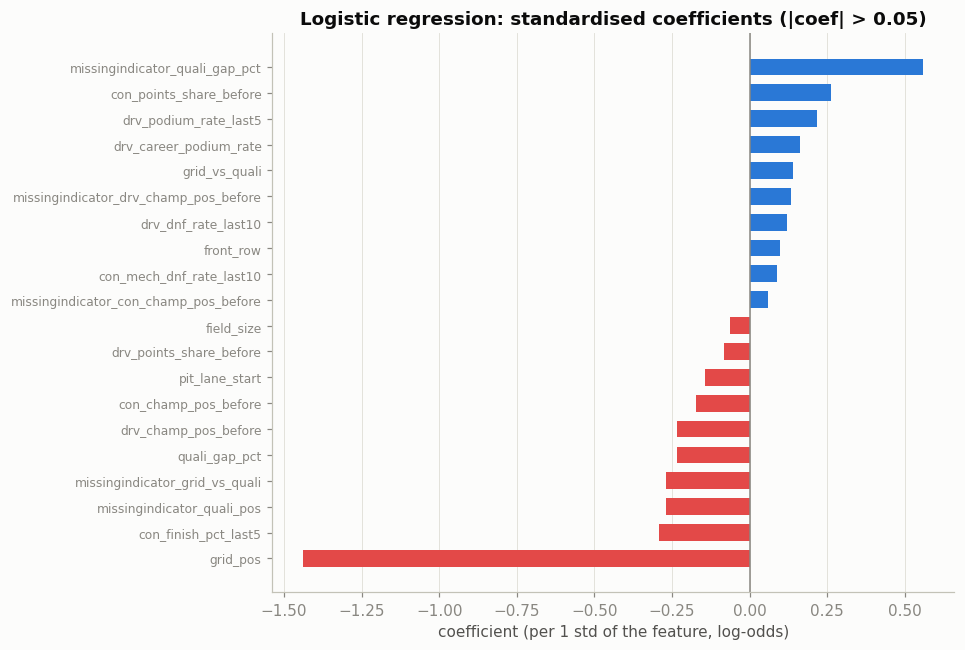

In [48]:
lr_best = tune(lambda **kw: LogisticRegression(max_iter=3000, **kw),
               [{"C": c, "class_weight": cw} for c in [0.01, 0.1, 1.0, 10.0] for cw in [None, "balanced"]])
register("Logistic regression (baseline)", make_model(LogisticRegression(max_iter=3000, C=1.0)).fit(X_train, y_train))
register("Logistic regression (tuned)", make_model(LogisticRegression(max_iter=3000, **lr_best)).fit(X_train, y_train))

coef = pd.Series(results["Logistic regression (tuned)"]["pipe"].named_steps["model"].coef_[0], index=PREP_FEATURE_NAMES)
coef = coef[coef.abs() > 0.05].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.28 * len(coef) + 1))
ax.barh(coef.index, coef.values, color=[C[0] if v > 0 else C[7] for v in coef.values], height=0.65)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("coefficient (per 1 std of the feature, log-odds)")
ax.set_title("Logistic regression: standardised coefficients (|coef| > 0.05)")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
save_fig("model_lr_coefficients")
plt.show()

### 9.3 Random forest

**How it works:** an average of many decision trees, each trained on a bootstrap sample of the rows and considering only a random subset of features at each split. Single trees overfit; averaging hundreds of de-correlated trees cancels much of that variance. Threshold splits (e.g. `grid_pos ≤ 2.5`, then `con_podium_rate_last5 > 0.4`) capture **non-linear effects and interactions** that logistic regression cannot.

**Limitations:** probabilities (averaged leaf frequencies) are often poorly calibrated; no extrapolation beyond training ranges; much less interpretable without XAI; deep trees memorise the training set, so the train–validation gap is controlled by tuning `max_depth` and `min_samples_leaf`.

In [49]:
make_rf = lambda **kw: RandomForestClassifier(n_estimators=400, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE, **kw)
rf_best = tune(make_rf, [{"max_depth": d, "min_samples_leaf": l} for d in [6, 10, None] for l in [5, 20, 50]])
register("Random forest", make_model(make_rf(**rf_best)).fit(X_train, y_train))

,max_depth,min_samples_leaf,train PR-AUC,val PR-AUC,val ROC-AUC,val F1 (best thr)
0,None,20,0.7476,0.7262,0.9351,0.7164
1,None,50,0.6978,0.7256,0.9339,0.7197
2,10,50,0.6973,0.7246,0.9339,0.7126
3,10,20,0.7431,0.7240,0.9347,0.7143
4,6,50,0.6918,0.7238,0.9329,0.7111
5,6,20,0.7121,0.7234,0.9331,0.7100
6,6,5,0.7295,0.7202,0.9328,0.7094
7,10,5,0.8461,0.7184,0.9357,0.7224
8,None,5,0.8978,0.7128,0.9344,0.7170


chosen: {'max_depth': None, 'min_samples_leaf': 20}
Random forest: threshold=0.235 | train PR-AUC=0.7476 F1=0.6713 | val PR-AUC=0.7262 ROC-AUC=0.9351 F1=0.7164


### 9.4 Gradient boosting (HistGradientBoosting)

**How it works:** trees are built **one after another**; each new small tree is fitted to the errors (gradient of the log-loss) of the ensemble so far, shrunk by the learning rate. The *histogram* variant bins every feature into at most 255 buckets (fast training), and early stopping on an internal split of the **training** rows decides how many trees to add.

**Limitations:** more hyperparameters, and it overfits easily with deep trees or a high learning rate (the *default* settings already scored below logistic regression in 7.1); no extrapolation; a black box without XAI.

In [50]:
make_gb = lambda **kw: HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE, **kw)
gb_best = tune(make_gb, [{"learning_rate": lr_, "max_leaf_nodes": leaves, "min_samples_leaf": msl, "l2_regularization": l2}
                         for lr_ in [0.03, 0.1] for leaves in [7, 15, 31] for msl in [20, 100] for l2 in [0.0, 1.0]])
register("Gradient boosting", make_model(make_gb(**gb_best)).fit(X_train, y_train))

,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,train PR-AUC,val PR-AUC,val ROC-AUC,val F1 (best thr)
0,0.03,31,100,0.0,0.7867,0.7185,0.9308,0.7250
1,0.03,7,100,0.0,0.7045,0.7172,0.9313,0.7077
2,0.1,31,100,0.0,0.7919,0.7169,0.9285,0.7154
3,0.1,31,100,1.0,0.7949,0.7165,0.9308,0.7115
4,0.03,31,100,1.0,0.7895,0.7163,0.9305,0.7203
5,0.03,15,100,0.0,0.7458,0.7121,0.9325,0.7119
6,0.03,15,100,1.0,0.7472,0.7108,0.9312,0.7160
7,0.03,7,100,1.0,0.7163,0.7098,0.9309,0.7059
8,0.1,15,100,1.0,0.7517,0.7096,0.9326,0.7251
9,0.1,7,100,1.0,0.7243,0.7094,0.9298,0.7077


chosen: {'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 100, 'l2_regularization': 0.0}
Gradient boosting: threshold=0.322 | train PR-AUC=0.7867 F1=0.7299 | val PR-AUC=0.7185 ROC-AUC=0.9308 F1=0.7250


### 9.5 Shallow neural network (MLP, 1–2 hidden layers)

**How it works:** a feed-forward multilayer perceptron. The 32 standardised inputs feed one or two hidden layers of ReLU units, and a sigmoid output gives the podium probability. Weights are learned with Adam by minimising the log-loss with an L2 penalty (`alpha`). **Early stopping** holds out 10% of the *training* rows and stops when their score stops improving. Implementation: scikit-learn's `MLPClassifier` (a standard library, as the brief allows).

**Architectures tried:** one hidden layer (16 or 32 units) and two hidden layers (32→16, 64→32), each with three regularisation strengths.

**Limitations:** stochastic training (results depend on the seed, checked below with 5 seeds); needs scaled inputs; the least interpretable model; on about 10k tabular rows with 20 features it has little room to beat tree ensembles or logistic regression.

,hidden_layer_sizes,alpha,train PR-AUC,val PR-AUC,val ROC-AUC,val F1 (best thr)
0,"(64, 32)",0.0001,0.6857,0.7392,0.9265,0.7078
1,"(64, 32)",0.01,0.6982,0.7361,0.9272,0.7173
2,"(64, 32)",0.001,0.6620,0.7242,0.9221,0.7083
3,"(32,)",0.001,0.6672,0.7166,0.9205,0.7227
4,"(32,)",0.01,0.6669,0.7166,0.9204,0.7227
5,"(32,)",0.0001,0.6670,0.7164,0.9205,0.7227
6,"(32, 16)",0.001,0.6939,0.7098,0.9232,0.7018
7,"(32, 16)",0.0001,0.6940,0.7097,0.9233,0.7074
8,"(32, 16)",0.01,0.6938,0.7088,0.9231,0.7074
9,"(16,)",0.001,0.5962,0.6761,0.9022,0.6781


chosen: {'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
Shallow neural network: threshold=0.403 | train PR-AUC=0.6857 F1=0.6677 | val PR-AUC=0.7392 ROC-AUC=0.9265 F1=0.7078


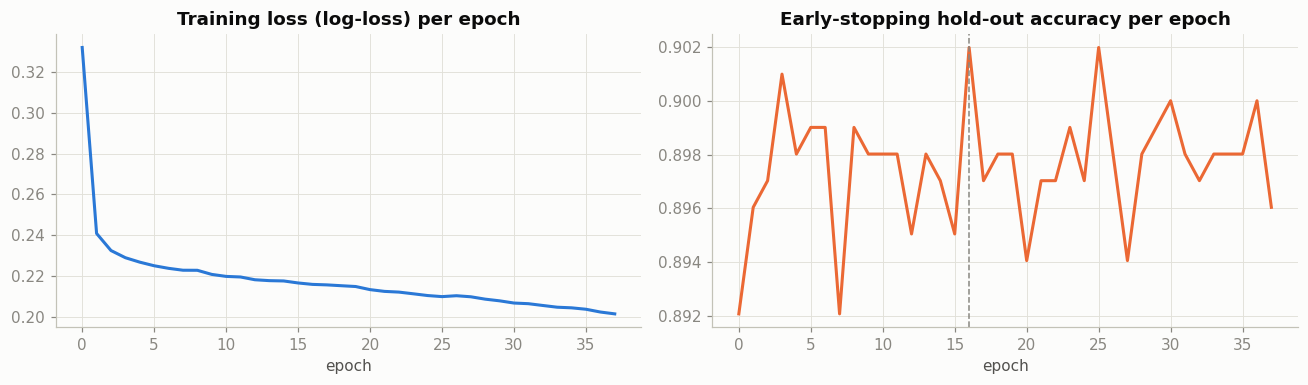

stopped after 38 epochs; best hold-out score at epoch 17
chosen architecture over 5 seeds: val PR-AUC mean 0.7273 ± 0.0057 (min 0.7209, max 0.7345); seed 42 gave 0.7392


In [51]:
def make_mlp(random_state=RANDOM_STATE, **kw):
    return MLPClassifier(activation="relu", solver="adam", learning_rate_init=1e-3, max_iter=500,
                         early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
                         random_state=random_state, **kw)
mlp_best = tune(make_mlp, [{"hidden_layer_sizes": h, "alpha": a} for h in [(16,), (32,), (32, 16), (64, 32)] for a in [1e-4, 1e-3, 1e-2]])
register("Shallow neural network", make_model(make_mlp(**mlp_best)).fit(X_train, y_train))

mlp = results["Shallow neural network"]["pipe"].named_steps["model"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(mlp.loss_curve_, color=C[0]); axes[0].set_title("Training loss (log-loss) per epoch")
axes[1].plot(mlp.validation_scores_, color=C[1]); axes[1].set_title("Early-stopping hold-out accuracy per epoch")
axes[1].axvline(int(np.argmax(mlp.validation_scores_)), color=MUTED, linestyle="--", linewidth=1)
for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()
save_fig("model_mlp_training")
plt.show()
print(f"stopped after {mlp.n_iter_} epochs; best hold-out score at epoch {int(np.argmax(mlp.validation_scores_)) + 1}")

# The network's result depends on its random initialisation: refit the chosen architecture with 5 seeds
seed_df = pd.DataFrame([{"seed": seed, "val PR-AUC": average_precision_score(
    y_val, make_model(make_mlp(random_state=seed, **mlp_best)).fit(X_train, y_train).predict_proba(X_val)[:, 1])} for seed in range(5)])
print(f"chosen architecture over 5 seeds: val PR-AUC mean {seed_df['val PR-AUC'].mean():.4f} ± {seed_df['val PR-AUC'].std():.4f} "
      f"(min {seed_df['val PR-AUC'].min():.4f}, max {seed_df['val PR-AUC'].max():.4f}); seed {RANDOM_STATE} gave "
      f"{average_precision_score(y_val, results['Shallow neural network']['p_val']):.4f}")

**What the tuning showed** (every attempt is kept in the tables above):
- **Logistic regression:** regularisation hardly matters (validation PR-AUC 0.732–0.734 for C from 0.1 to 10); `class_weight="balanced"` is slightly *worse*, consistent with the oversampling experiment (8.3). The tuning picks **C = 1, the default**, so the tuned model is identical to the baseline.
- **Random forest:** unrestricted trees memorise (`min_samples_leaf=5`, no depth limit: train PR-AUC 0.898 vs 0.713 validation). Larger leaves reduce this; the chosen setting (no depth limit, `min_samples_leaf=20`) narrows the gap to 0.748 vs 0.726.
- **Gradient boosting:** all of the 10 best settings use large leaves (`min_samples_leaf=100`). The chosen one (learning rate 0.03, 31 leaves) still fits the training seasons better than validation (0.787 vs 0.719) and does not beat logistic regression.
- **Neural network:** the two-layer 64→32 network with the weakest L2 scored best on validation (0.739), but the **seed check** shows this was partly luck: the same architecture averages **0.727 ± 0.006** over 5 other seeds (0.721–0.735), and seed 42 sits above all of them.


## 10. Model comparison

All metrics for every model on train, validation and the **unseen test set** (2022–2024). Test predictions use each model's validation-chosen threshold, so nothing about the test set influenced any choice.

In [52]:
model_names = list(results)
comparison = pd.DataFrame([{"model": name, "split": split, "threshold": r["threshold"], **scores(y, r[f"p_{key}"], r["threshold"], d["raceId"])}
                           for name, r in results.items()
                           for split, key, y, d in [("train", "train", y_train, train), ("validation", "val", y_val, val), ("test", "test", y_test, test)]])
METRICS = ["PR-AUC", "ROC-AUC", "F1", "Precision", "Recall", "Top-3 precision"]
comparison_wide = (comparison.pivot(index="model", columns="split", values=METRICS)
                   .reindex(columns=pd.MultiIndex.from_product([METRICS, ["train", "validation", "test"]])).loc[model_names])
comparison_wide.round(3)

PR-AUC                   ROC-AUC                       F1                   Precision                   Recall                   Top-3 precision                  
                                train validation   test   train validation   test  train validation   test     train validation   test  train validation   test           train validation   test
model                                                                                                                                                                                            
Reference: grid ≤ 3 rule       0.5900     0.6480 0.6470  0.9050     0.9100 0.9130 0.6240     0.6950 0.6490    0.6260     0.6980 0.6500 0.6220     0.6920 0.6470          0.6270     0.7010 0.6520
Logistic regression (baseline) 0.6550     0.7340 0.7260  0.9240     0.9330 0.9370 0.6390     0.7130 0.6650    0.5240     0.6520 0.5420 0.8210     0.7860 0.8630          0.6270     0.6920 0.6620
Logistic regression (tuned)    0.6550     0.7340 0.7260  0.9240     0.9330 0.9370 0.6390     0.7130 0.6650    0.5240     0.6520 0.5420 0.8210     0.7860 0.8630          0.6270     0.6920 0.6620
Random forest                  0.7480     0.7260 0.7140  0.9500     0.9350 0.9400 0.6710     0.7160 0.6680    0.5500     0.6360 0.5370 0.8600     0.8210 0.8820          0.6680     0.7010 0.6570
Gradient boosting              0.7870     0.7180 0.7030  0.9620     0.9310 0.9380 0.7300     0.7250 0.6920    0.6520     0.7070 0.6430 0.8290     0.7440 0.7500          0.7290     0.6750 0.6370
Shallow neural network         0.6860     0.7390 0.7160  0.9320     0.9270 0.9350 0.6680     0.7080 0.6540    0.6020     0.6830 0.6140 0.7500     0.7350 0.7010          0.6400     0.7010 0.6370

**Reading the table.**
- **Every learned model clearly beats the grid rule** on the primary metric: test PR-AUC 0.703–0.726 vs 0.647. ROC-AUC is about 0.94 for all models and 0.91 even for the rule, which shows why it is not our primary metric: the many obvious non-podiums inflate it.
- **Train vs validation:** for logistic regression and the network the train score is *lower* than validation (LR 0.655 vs 0.734). This is not underfitting: the training seasons include 1994–2002, with patchy qualifying data, low reliability and bigger fields, which are harder to predict than the modern validation and test seasons. The tree ensembles score *higher* on train (RF 0.748, GB 0.787 vs about 0.72 on validation) because they fit the training rows more closely.
- **Validation → test:** PR-AUC drops slightly (0.01–0.02), as expected after the 2022 regulation change. The F1 threshold transfers less well: LR's 0.22 gives recall 0.86 but precision only 0.54 on test, flagging about 5 drivers per race.
- **Top-3 precision:** picking each race's 3 most likely drivers gets about **2 of 3 podium places right** (0.64–0.66 on test), which is **no better than the grid rule (0.65)**: LR is slightly above it, random forest about equal, gradient boosting and the network slightly below. The models' advantage lies in *probabilities and ranking across the whole field*, not in picking the top 3.


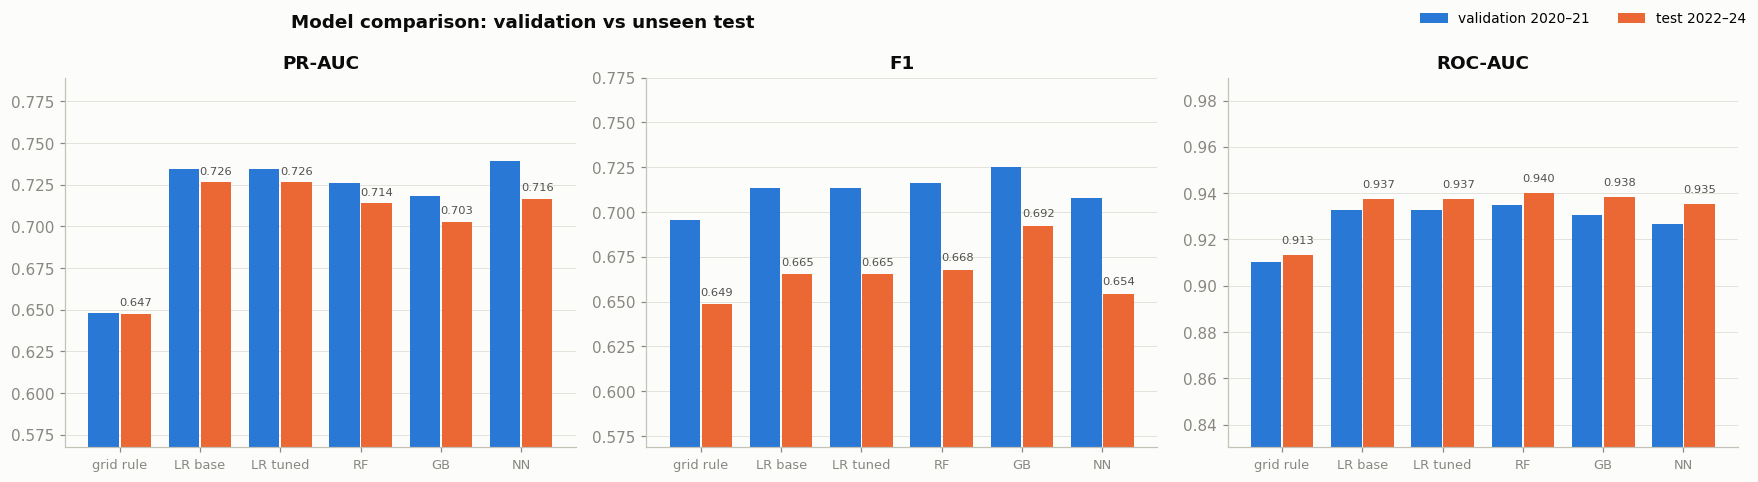

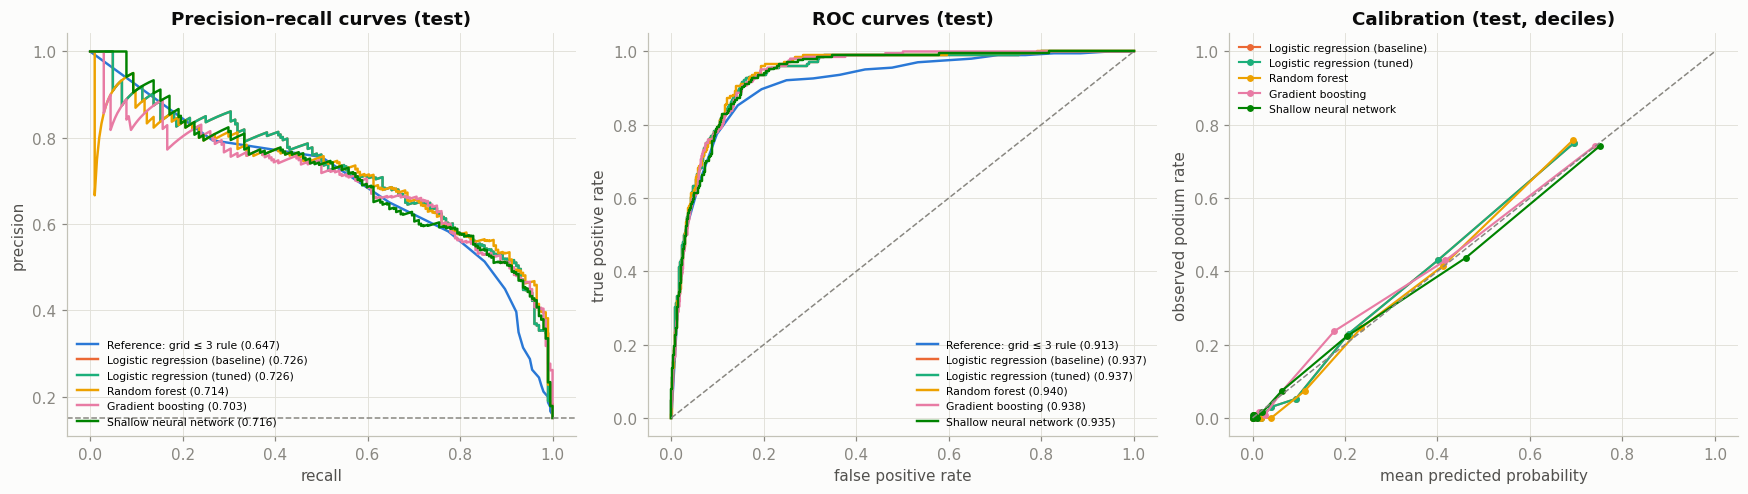

In [53]:
SHORT = {"Reference: grid ≤ 3 rule": "grid rule", "Logistic regression (baseline)": "LR base", "Logistic regression (tuned)": "LR tuned",
         "Random forest": "RF", "Gradient boosting": "GB", "Shallow neural network": "NN"}
x = np.arange(len(model_names))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, metric in zip(axes, ["PR-AUC", "F1", "ROC-AUC"]):
    v, t = (comparison[comparison["split"] == s].set_index("model").loc[model_names, metric] for s in ["validation", "test"])
    ax.bar(x - 0.2, v, width=0.38, color=C[0], label="validation 2020–21")
    ax.bar(x + 0.2, t, width=0.38, color=C[1], label="test 2022–24")
    for xi, val_ in zip(x, t):
        ax.text(xi + 0.2, val_ + 0.005, f"{val_:.3f}", ha="center", fontsize=7.5, color=INK2)
    ax.set_xticks(x); ax.set_xticklabels([SHORT[m] for m in model_names], fontsize=8.5)
    ax.set_ylim(max(0, min(v.min(), t.min()) - 0.08), min(1, max(v.max(), t.max()) + 0.05))
    ax.set_title(metric); ax.grid(axis="x", visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, fontsize=9)
fig.suptitle("Model comparison: validation vs unseen test", fontweight="bold", color=INK, x=0.3)
plt.tight_layout()
save_fig("compare_bars")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for i, name in enumerate(model_names):
    p = results[name]["p_test"]
    prec, rec, _ = precision_recall_curve(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(rec, prec, color=C[i], linewidth=1.6, label=f"{name} ({average_precision_score(y_test, p):.3f})")
    axes[1].plot(fpr, tpr, color=C[i], linewidth=1.6, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    if i > 0:                                   # calibration only for the learned models
        cal = pd.DataFrame({"p": p, "y": y_test}).groupby(pd.qcut(p, 10, duplicates="drop"), observed=True).mean()
        axes[2].plot(cal["p"], cal["y"], marker="o", markersize=3.5, color=C[i], linewidth=1.4, label=name)
axes[0].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
for ax in axes[1:]:
    ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
for ax, (xl, yl, title, loc) in zip(axes, [("recall", "precision", "Precision–recall curves (test)", "lower left"),
                                           ("false positive rate", "true positive rate", "ROC curves (test)", "lower right"),
                                           ("mean predicted probability", "observed podium rate", "Calibration (test, deciles)", "upper left")]):
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title); ax.legend(fontsize=7, loc=loc)
plt.tight_layout()
save_fig("compare_curves")
plt.show()

**Curves.** On the precision–recall curve the learned models dominate the grid rule over most of the range, especially at high recall, where the rule has to dig deep into the grid. The calibration plot shows all learned models are well calibrated on the unseen seasons (when they say 40%, about 40% of those drivers reach the podium), helped by *not* oversampling (8.3). The two logistic-regression lines overlap.

### 10.1 Selecting the final model

**Rule:** the highest **validation** PR-AUC (primary metric). For the neural network we use its **5-seed mean**, because its seed-42 run (0.739) sits above all 5 other seeds (0.721–0.735); choosing it on that run would be selecting on luck.

,val PR-AUC (seed 42 fit),val F1,val PR-AUC used for selection
model,,,
Logistic regression (baseline),0.7342,0.7132,0.7342
Logistic regression (tuned),0.7342,0.7132,0.7342
Shallow neural network,0.7392,0.7078,0.7273
Random forest,0.7262,0.7164,0.7262
Gradient boosting,0.7185,0.7250,0.7185


Selected model by validation PR-AUC (primary metric): Logistic regression (baseline)  (threshold 0.217)


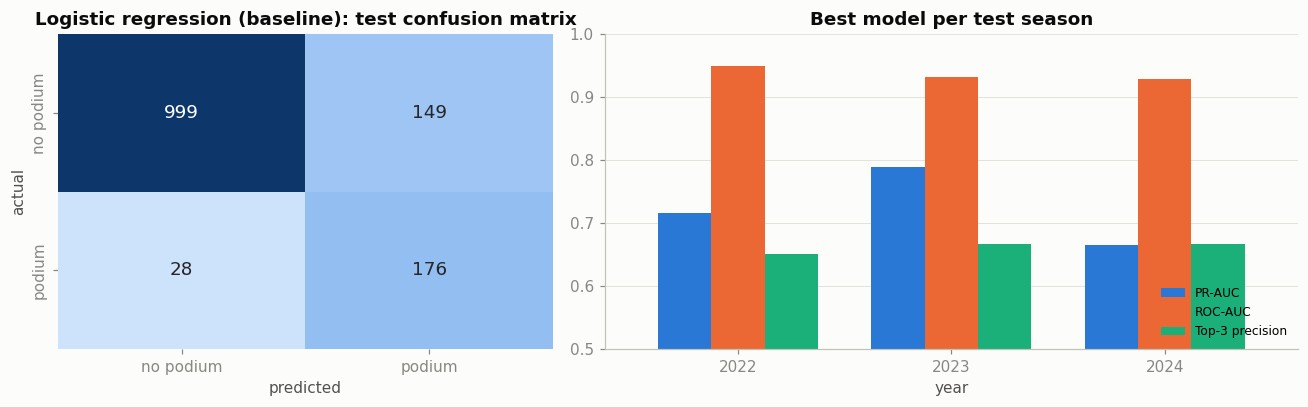

,PR-AUC,ROC-AUC,Top-3 precision
year,,,
2022,0.7160,0.9500,0.6520
2023,0.7900,0.9320,0.6670
2024,0.6650,0.9290,0.6670


In [54]:
selection = comparison[comparison["split"] == "validation"].set_index("model").drop(index="Reference: grid ≤ 3 rule")[["PR-AUC", "F1"]]
selection = selection.rename(columns={"PR-AUC": "val PR-AUC (seed 42 fit)", "F1": "val F1"})
selection["val PR-AUC used for selection"] = selection["val PR-AUC (seed 42 fit)"]
selection.loc["Shallow neural network", "val PR-AUC used for selection"] = seed_df["val PR-AUC"].mean()
selection = selection.sort_values("val PR-AUC used for selection", ascending=False)
display(selection.round(4))
BEST_MODEL = selection.index[0]
best = results[BEST_MODEL]
print(f"Selected model by validation PR-AUC (primary metric): {BEST_MODEL}  (threshold {best['threshold']:.3f})")

cm = confusion_matrix(y_test, (best["p_test"] >= best["threshold"]).astype(int))
per_season = pd.DataFrame({"year": test["year"].values, "y": y_test, "p": best["p_test"], "raceId": test["raceId"].values})
season_scores = per_season.groupby("year")[["y", "p", "raceId"]].apply(lambda d: pd.Series({
    "PR-AUC": average_precision_score(d["y"], d["p"]), "ROC-AUC": roc_auc_score(d["y"], d["p"]),
    "Top-3 precision": top3_precision(d["raceId"], d["y"], d["p"])}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(cm, annot=True, fmt="d", cmap=SEQ, cbar=False, ax=axes[0], annot_kws={"size": 12},
            xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("actual"); axes[0].set_title(f"{BEST_MODEL}: test confusion matrix")
season_scores.plot(kind="bar", ax=axes[1], color=C[:3], width=0.75, rot=0)
axes[1].set_ylim(0.5, 1); axes[1].set_title("Best model per test season")
axes[1].legend(fontsize=8, loc="lower right"); axes[1].grid(axis="x", visible=False)
plt.tight_layout()
save_fig("compare_best_model")
plt.show()
season_scores.round(3)

**Result.**
- **The selected model is logistic regression with C = 1** (the baseline; tuning chose the same setting, so the two rows are identical and the tie goes to the baseline): test PR-AUC **0.726** (primary), test F1 **0.665** at the validation threshold (secondary), ROC-AUC 0.937, top-3 precision 0.662.
- **Per test season** the scores follow how predictable each season was: **2023** is the easiest (PR-AUC 0.790; Red Bull won 21 of 22 races), **2024** the hardest (0.665; four different teams won races).
- **In plain terms:** given only the grid, qualifying and past form, the model ranks a real podium finisher above a driver who did not reach the podium about 94% of the time (ROC-AUC), and about 2 of the 3 drivers it rates most likely in each race reach the podium.

**Are the differences between models real?** The test set has only 68 races and 204 podiums, so a 0.01 PR-AUC difference could be luck. We resample **whole races** with replacement (1,000 bootstrap samples) and recompute each model's test PR-AUC, giving 95% intervals and the share of samples in which each model beats the logistic-regression baseline.

In [55]:
boot_rng = np.random.default_rng(RANDOM_STATE)
race_arr = test["raceId"].values
race_index = {r: np.flatnonzero(race_arr == r) for r in np.unique(race_arr)}
race_list = list(race_index)
boot = {name: [] for name in model_names}
for _ in range(1000):
    idx = np.concatenate([race_index[r] for r in boot_rng.choice(race_list, len(race_list), replace=True)])
    for name in model_names:
        boot[name].append(average_precision_score(y_test[idx], results[name]["p_test"][idx]))
boot = pd.DataFrame(boot)
base_name = "Logistic regression (baseline)"
pd.DataFrame({
    "test PR-AUC": [average_precision_score(y_test, results[m]["p_test"]) for m in model_names],
    "95% CI low": boot.quantile(0.025).values, "95% CI high": boot.quantile(0.975).values,
    "P(beats LR baseline)": [(boot[m] > boot[base_name]).mean() if m != base_name else np.nan for m in model_names],
}, index=model_names).round(3)

,test PR-AUC,95% CI low,95% CI high,P(beats LR baseline)
Reference: grid ≤ 3 rule,0.6470,0.5920,0.7090,0.0000
Logistic regression (baseline),0.7260,0.6670,0.7860,NaN
Logistic regression (tuned),0.7260,0.6670,0.7860,0.0000
Random forest,0.7140,0.6570,0.7770,0.1240
Gradient boosting,0.7030,0.6520,0.7590,0.0350
Shallow neural network,0.7160,0.6630,0.7700,0.1710


**Result of the bootstrap:** all learned models have **overlapping 95% intervals** (roughly 0.65–0.79). Random forest, gradient boosting and the network beat the logistic-regression baseline in only **4–17%** of samples (the tuned LR is the same model, so it never beats it), so none is better; the grid rule *never* beats it (0 of 1,000), so the gain from learning is real.

**Conclusion of the modeling:** the problem is close to additive ("where you start + how fast your car is + how good you are lately"), and logistic regression captures that as well as the flexible models do. The more complex models do not earn their added complexity here, which is a legitimate and useful result of the baseline comparison.


## 11. Feature-group ablation

Section 6 justified each group *before* training; the ablation measures what each group **actually contributes** after training: remove one group at a time, re-fit on the same rows, re-choose the threshold on validation, and measure the change in PR-AUC.
- We ablate the selected final model **and** gradient boosting (structurally different, non-linear), so the conclusions do not depend on one model family. Stochastic models would be averaged over 3 seeds.
- Grid and qualifying positions are 98% correlated, so we also remove them **together** ("starting position"); otherwise each stands in for the other.

Δ val PR-AUC                                    Δ test PR-AUC                                        Δ test F1                               
model                                   Gradient boosting Logistic regression (baseline) Gradient boosting Logistic regression (baseline) Gradient boosting Logistic regression (baseline)
ablation                                                                                                                                                                                  
none (all features)                                0.0000                         0.0000            0.0000                         0.0000            0.0000                         0.0000
− grid                                            -0.0029                        -0.0066           -0.0094                        -0.0166           -0.0256                        -0.0109
− qualifying                                      -0.0204                        -0.0095            0.0046                        -0.0010           -0.0298                         0.0013
− driver_form                                     -0.0077                        -0.0153           -0.0047                         0.0013           -0.0328                         0.0077
− constructor_form                                 0.0206                         0.0028           -0.0031                        -0.0070           -0.0143                         0.0037
− standings                                       -0.0017                        -0.0067            0.0003                        -0.0065           -0.0209                         0.0160
− context                                         -0.0059                        -0.0020            0.0002                         0.0012           -0.0123                        -0.0037
− starting position (grid + qualifying)           -0.0988                        -0.0845           -0.1147                        -0.1557           -0.1415                        -0.0971

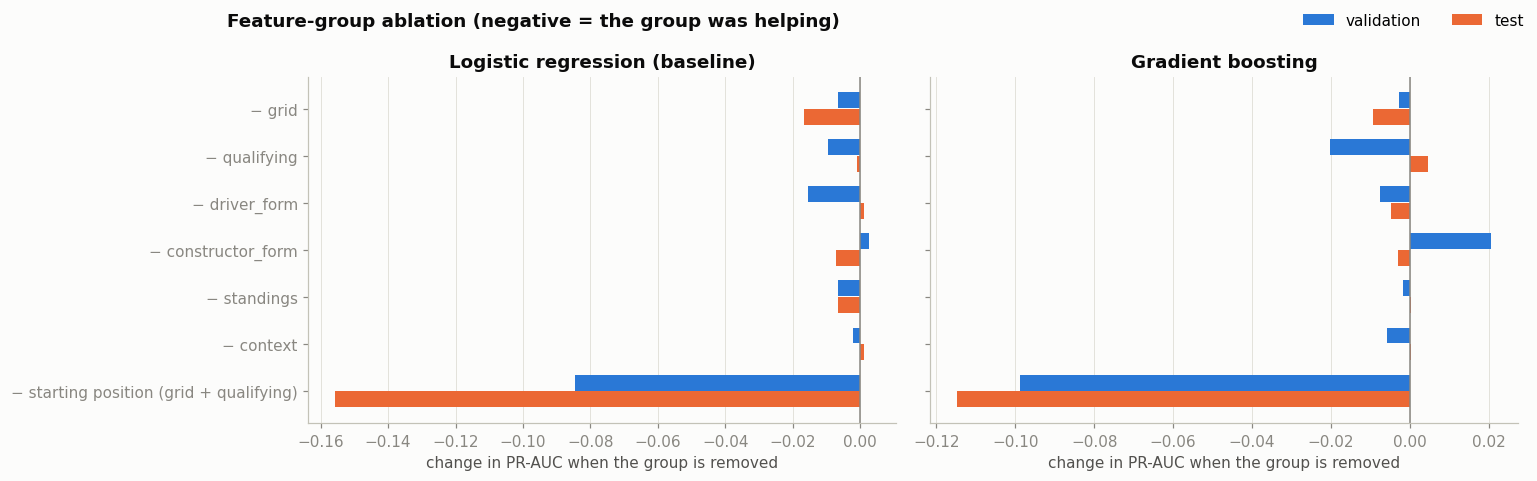

In [56]:
ABL_MODELS = [BEST_MODEL, "Gradient boosting" if BEST_MODEL != "Gradient boosting" else "Logistic regression (baseline)"]
STOCHASTIC = (MLPClassifier, RandomForestClassifier)
ABL_SEEDS = [RANDOM_STATE, 0, 1]     # stochastic models are averaged over 3 seeds so the deltas are not seed noise

ABLATIONS = {"none (all features)": []}
ABLATIONS.update({f"− {g}": fs for g, fs in FEATURE_GROUPS.items()})
ABLATIONS["− starting position (grid + qualifying)"] = FEATURE_GROUPS["grid"] + FEATURE_GROUPS["qualifying"]

abl_rows = []
for label, drop in ABLATIONS.items():
    feats = [f for f in FEATURES if f not in drop]
    for model_label in ABL_MODELS:
        template = results[model_label]["pipe"].named_steps["model"]
        runs = []
        for seed in (ABL_SEEDS if isinstance(template, STOCHASTIC) else [None]):
            est = clone(template) if seed is None else clone(template).set_params(random_state=seed)
            pipe = make_model(est).fit(X_train[feats], y_train)
            p_va, p_te = pipe.predict_proba(X_val[feats])[:, 1], pipe.predict_proba(X_test[feats])[:, 1]
            thr = best_f1_threshold(y_val, p_va)
            runs.append({"val PR-AUC": average_precision_score(y_val, p_va), "test PR-AUC": average_precision_score(y_test, p_te),
                         "val F1": scores(y_val, p_va, thr)["F1"], "test F1": scores(y_test, p_te, thr)["F1"]})
        abl_rows.append({"ablation": label, "model": model_label, "n features": len(feats), "runs": len(runs), **pd.DataFrame(runs).mean().to_dict()})
ablation = pd.DataFrame(abl_rows)
for col in ["val PR-AUC", "test PR-AUC", "val F1", "test F1"]:
    full = ablation[ablation["ablation"] == "none (all features)"].set_index("model")[col]
    ablation[f"Δ {col}"] = ablation[col] - ablation["model"].map(full)
display(ablation.pivot(index="ablation", columns="model", values=["Δ val PR-AUC", "Δ test PR-AUC", "Δ test F1"]).reindex(list(ABLATIONS)).round(4))

labels = [a for a in ABLATIONS if a != "none (all features)"]
y = np.arange(len(labels))[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, model_label in zip(axes, ABL_MODELS):
    d = ablation[ablation["model"] == model_label].set_index("ablation").loc[labels]
    ax.barh(y + 0.18, d["Δ val PR-AUC"], height=0.34, color=C[0], label="validation")
    ax.barh(y - 0.18, d["Δ test PR-AUC"], height=0.34, color=C[1], label="test")
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_title(model_label)
    ax.set_xlabel("change in PR-AUC when the group is removed"); ax.grid(axis="y", visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.suptitle("Feature-group ablation (negative = the group was helping)", fontweight="bold", color=INK, x=0.35)
plt.tight_layout()
save_fig("ablation")
plt.show()

**What the ablation shows** (Δ = change in PR-AUC; negative = the model got worse without the group):
- **Starting position is the backbone.** Removing grid and qualifying *together* costs by far the most: −0.08 on validation and **−0.16 on test** for logistic regression, −0.10 / −0.11 for gradient boosting. Removing either *alone* costs only 0 to −0.02, because the other covers for it (98% correlated), exactly the redundancy predicted in 6.3.
- **Driver form, standings and constructor form each add a little** (at most about −0.02), with signs not always consistent between validation and test: removing constructor form even *raises* validation PR-AUC (+0.003 LR, +0.021 GB) while lowering test. They overlap heavily (championship position, points share and recent team results all describe "a fast car this season"), so removing one leaves the others to carry the information.
- **`field_size` (context) adds nothing:** Δ ≈ 0 for both models (at most −0.006 on validation, +0.001 on test).
- **With only 117 and 204 podiums**, deltas below about 0.01–0.02 are within noise (see the bootstrap in section 10).
- **Decision: keep all groups.** None clearly hurts, and together they add about 0.08 PR-AUC over the grid rule. A smaller model (starting position + standings) would be almost as good, which is useful for a simpler product.

**Re-checking a feature we left out: `home_race`.** Q2 found no home effect once starting position is controlled for, so `home_race` was excluded before training. Adding it back tests that decision empirically.


In [57]:
home = fe["home_race"]
home_rows = []
for label, extra in [("without home_race (chosen)", False), ("with home_race", True)]:
    Xs = [X.assign(home_race=home.loc[d.index].values) if extra else X for X, d in [(X_train, train), (X_val, val), (X_test, test)]]
    pipe = make_model(LogisticRegression(max_iter=3000)).fit(Xs[0], y_train)
    home_rows.append({"feature set": label, "val PR-AUC": average_precision_score(y_val, pipe.predict_proba(Xs[1])[:, 1]),
                      "test PR-AUC": average_precision_score(y_test, pipe.predict_proba(Xs[2])[:, 1]),
                      "home_race coefficient": pipe.named_steps["model"].coef_[0][list(pipe.named_steps["prep"].get_feature_names_out()).index("home_race")]
                                               if extra else np.nan})
pd.DataFrame(home_rows).round(4)

,feature set,val PR-AUC,test PR-AUC,home_race coefficient
0,without home_race (chosen),0.7342,0.7264,NaN
1,with home_race,0.7290,0.7255,-0.0966


**Result:** adding `home_race` *lowers* validation PR-AUC by 0.005 and test by 0.001. Its coefficient is small and negative (−0.10 on the standardised scale), the same direction as the naive Q2 comparison and never a home *advantage*. This confirms empirically what Q2 found statistically: the home race adds no useful information once grid and form are known, so leaving it out was correct.


## 12. Explainability (XAI)

We explain the **selected model** (logistic regression, C = 1), always on held-out data: validation for permutation importance, test rows for SHAP and LIME.

> **Important: importance is not causation.** A feature being important to the model means the model **relies on it to make predictions**. It does **not** prove that the feature *causes* podium finishes. For example, `con_podium_rate_last5` is important because fast cars keep being fast, not because past podiums make a car faster. Correlated features also share and swap importance (grid ↔ qualifying, standings position ↔ points share), so one feature's importance depends on which others are present. Every statement below describes the model's behaviour, not how Formula 1 works.

### 12.1 Global: permutation importance

Shuffle one feature in the validation set (breaking its link with the target while keeping its distribution), measure the drop in PR-AUC, repeat 20 times. It is model-agnostic and runs on the full pipeline, imputation included. Because correlated features cover for each other, we also permute **whole feature groups** at once.

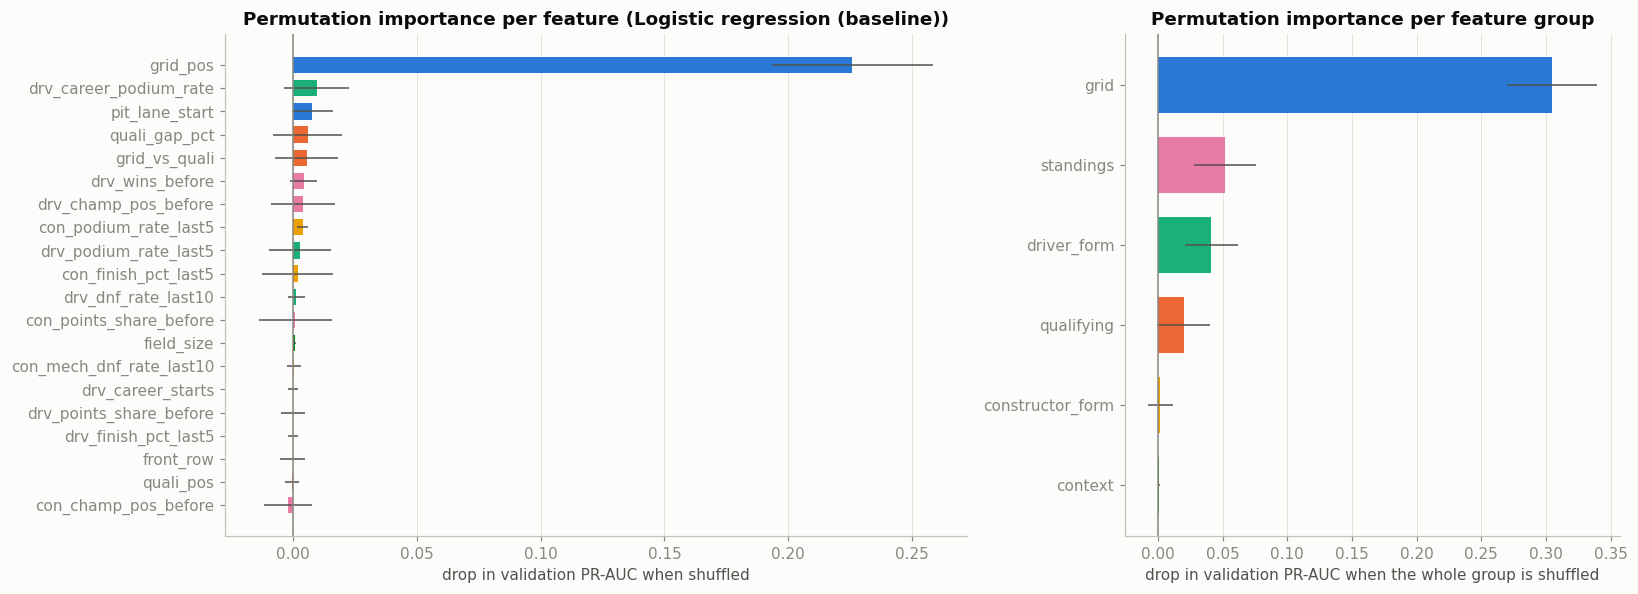

,group,importance,std
0,grid,0.3049,0.0347
4,standings,0.0518,0.0243
2,driver_form,0.0413,0.0206
1,qualifying,0.0200,0.0204
3,constructor_form,0.0017,0.0097
5,context,0.0008,0.0005


In [58]:
final_pipe = results[BEST_MODEL]["pipe"]
FINAL_THRESHOLD = results[BEST_MODEL]["threshold"]

perm = permutation_importance(final_pipe, X_val, y_val, scoring="average_precision", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean, "std": perm.importances_std,
                        "group": [GROUP_OF[f] for f in FEATURES]}).sort_values("importance", ascending=False)

perm_rng = np.random.default_rng(RANDOM_STATE)
base_ap = average_precision_score(y_val, final_pipe.predict_proba(X_val)[:, 1])
group_imp = []
for g, fs in FEATURE_GROUPS.items():
    drops = []
    for _ in range(20):
        Xp = X_val.copy()
        Xp[fs] = Xp[fs].values[perm_rng.permutation(len(Xp))]
        drops.append(base_ap - average_precision_score(y_val, final_pipe.predict_proba(Xp)[:, 1]))
    group_imp.append({"group": g, "importance": np.mean(drops), "std": np.std(drops)})
group_imp = pd.DataFrame(group_imp).sort_values("importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
for ax, d, key, xlabel, title in [(axes[0], perm_df, "feature", "drop in validation PR-AUC when shuffled", f"Permutation importance per feature ({BEST_MODEL})"),
                                  (axes[1], group_imp, "group", "drop in validation PR-AUC when the whole group is shuffled", "Permutation importance per feature group")]:
    d = d.iloc[::-1]
    colors = [GROUP_COLOR[GROUP_OF[v] if key == "feature" else v] for v in d[key]]
    ax.barh(d[key], d["importance"], xerr=d["std"], color=colors, height=0.7, error_kw={"ecolor": INK2, "linewidth": 1})
    ax.axvline(0, color=MUTED, linewidth=1); ax.set_xlabel(xlabel); ax.set_title(title); ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig("xai_permutation")
plt.show()
display(group_imp.round(4))

**Interpretation (permutation importance):**
- **The model relies overwhelmingly on `grid_pos`:** shuffling it drops validation PR-AUC by about 0.23. Every other single feature costs ≤ 0.01, because each has a correlated partner that covers for it.
- **Permuting whole groups gives a fairer picture:** grid (0.305) ≫ standings (0.052) > driver form (0.041) > qualifying (0.020) > constructor form (0.002) > context (≈ 0).
- **Constructor form looks unimportant only because the standings carry the same "fast car" information.** It is not irrelevant to F1; the model simply does not need it once the standings are present. Again: importance is not causation.

### 12.2 Global: SHAP

SHAP splits each prediction into additive per-feature contributions that sum from the average prediction (base value) to this row's prediction; plotting many rows gives a global picture of which features move predictions most, and in which direction.
- **Final model:** logistic regression is not tree-based, so we use the model-agnostic **permutation SHAP explainer** on the full pipeline, in probability units. Background = 100 training rows from **2003–2019** (complete qualifying, like the test seasons; with 1994–2002 rows SHAP would credit "having a qualifying record at all" instead of the qualifying values); 300 test rows are explained.
- **Cross-check:** exact **TreeSHAP** for gradient boosting, to see whether a very different model relies on the same features.


PermutationExplainer explainer: 301it [00:29,  9.09it/s]                         


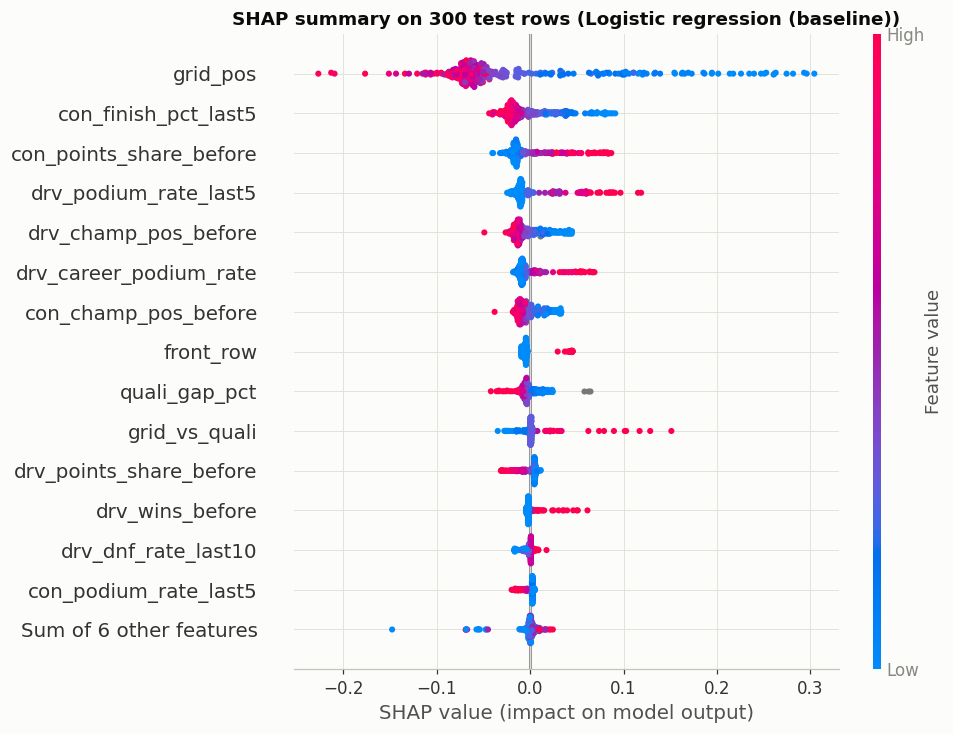

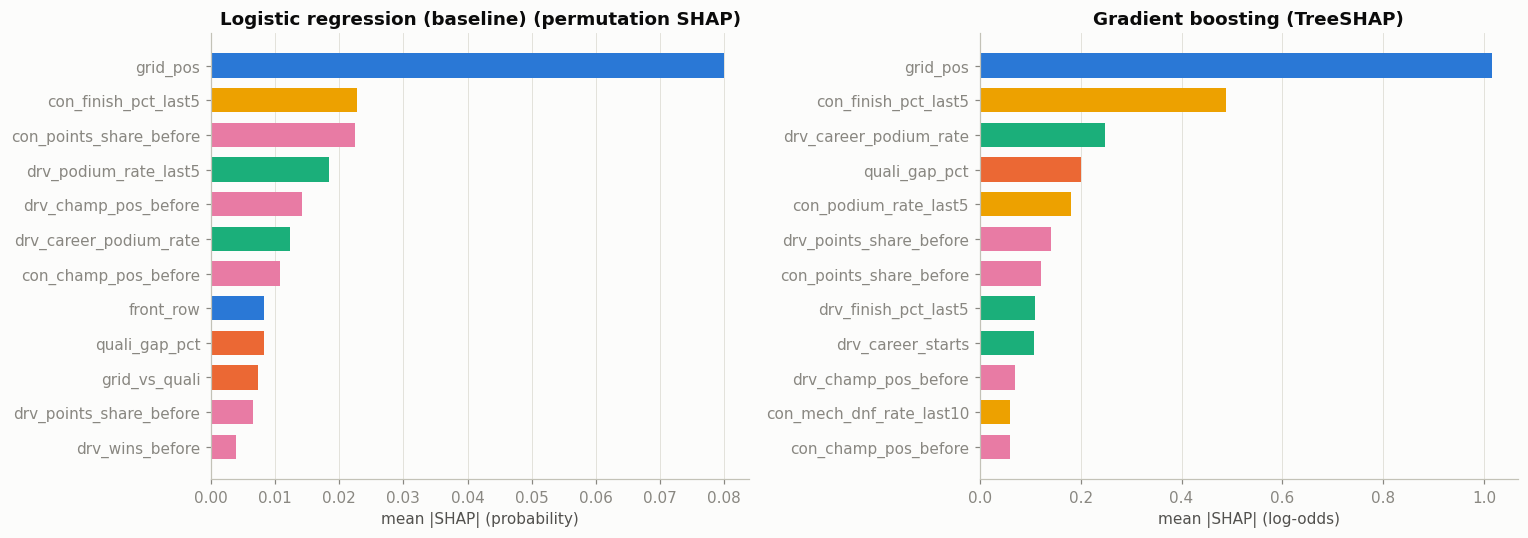

rank agreement between the two models' SHAP importances (Spearman): 0.43


In [59]:
modern_train = X_train[train["year"] >= 2003]
background = modern_train.sample(100, random_state=RANDOM_STATE)
explain_rows = X_test.sample(300, random_state=RANDOM_STATE)
predict_p = lambda X: final_pipe.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1]
shap_explainer = shap.Explainer(predict_p, shap.maskers.Independent(background), feature_names=FEATURES, seed=RANDOM_STATE)
shap_values = shap_explainer(explain_rows)

plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"SHAP summary on 300 test rows ({BEST_MODEL})")
save_fig("xai_shap_beeswarm")
plt.show()

shap_imp = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
gb_pipe = results["Gradient boosting"]["pipe"]
gb_shap = shap.TreeExplainer(gb_pipe.named_steps["model"])(gb_pipe.named_steps["prep"].transform(explain_rows))
gb_imp = pd.Series(np.abs(gb_shap.values).mean(axis=0), index=PREP_FEATURE_NAMES)[FEATURES].sort_values(ascending=False)  # indicators ≈ 0 on test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, imp, title, unit in [(axes[0], shap_imp, f"{BEST_MODEL} (permutation SHAP)", "mean |SHAP| (probability)"),
                             (axes[1], gb_imp, "Gradient boosting (TreeSHAP)", "mean |SHAP| (log-odds)")]:
    top = imp.head(12).iloc[::-1]
    ax.barh(top.index, top.values, color=[GROUP_COLOR[GROUP_OF[f]] for f in top.index], height=0.7)
    ax.set_title(title); ax.set_xlabel(unit); ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig("xai_shap_bar_models")
plt.show()
print("rank agreement between the two models' SHAP importances (Spearman):", round(stats.spearmanr(shap_imp[FEATURES], gb_imp[FEATURES])[0], 2))

**Interpretation (SHAP):**
- **`grid_pos` dominates:** a low grid number (blue dots) pushes the podium probability up by as much as +0.30, starting at the back pushes it down by as much as −0.23.
- **Car strength comes next** (`con_finish_pct_last5`, `con_points_share_before`: a low recent finishing percentage means the team has been finishing near the front, which pushes the prediction up), **then driver form and standings** (`drv_podium_rate_last5`, `drv_champ_pos_before`, `drv_career_podium_rate`). The qualifying features (`quali_gap_pct`, `grid_vs_quali`) come lower, because `grid_pos` already carries most of the same information.
- **All directions match F1 intuition:** further back on the grid, slower in qualifying or a pit-lane start lowers the prediction; a stronger record raises it. `grid_vs_quali > 0` (a penalty) *raises* the prediction for a given grid slot: a driver who qualified fast but was moved back is faster than the slot suggests.
- **SHAP and permutation importance agree on the top feature but rank the others differently**, as expected: SHAP measures how much a feature *moves predictions*, permutation importance how much *accuracy* is lost without it.
- **Gradient boosting (TreeSHAP)** also ranks `grid_pos` first by a wide margin, then `con_finish_pct_last5`, but leans more on career podium rate and the qualifying gap (overall rank agreement ≈ 0.4): with correlated features, different models pick different "representatives" of the same information, *who is fast*.

### 12.3 Local: explaining single predictions (SHAP waterfall + LIME)

Two drivers from **the same test-set race, the 2024 São Paulo Grand Prix** (a chaotic wet race): **Lando Norris** started from **pole** and finished 6th; **Max Verstappen** started **17th** and **won**. These hard cases show both how the model reasons and where it fails.


Lando Norris: grid 1, quali 1, predicted P(podium) = 0.78 -> podium (threshold 0.22); actual: no podium


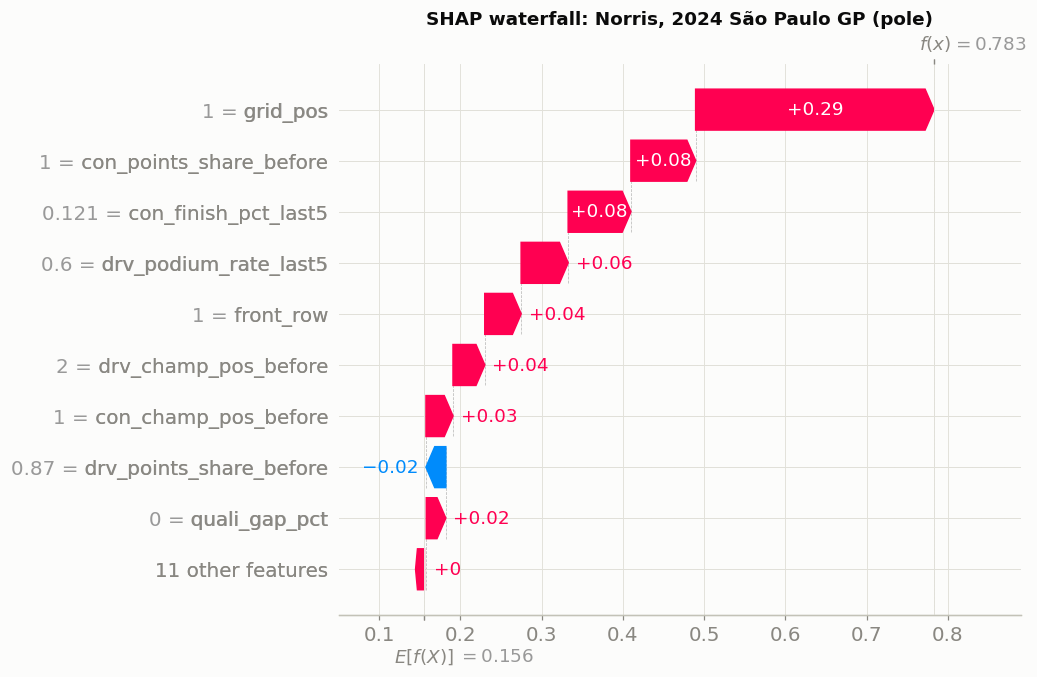

Max Verstappen: grid 17, quali 12, predicted P(podium) = 0.05 -> no podium (threshold 0.22); actual: PODIUM


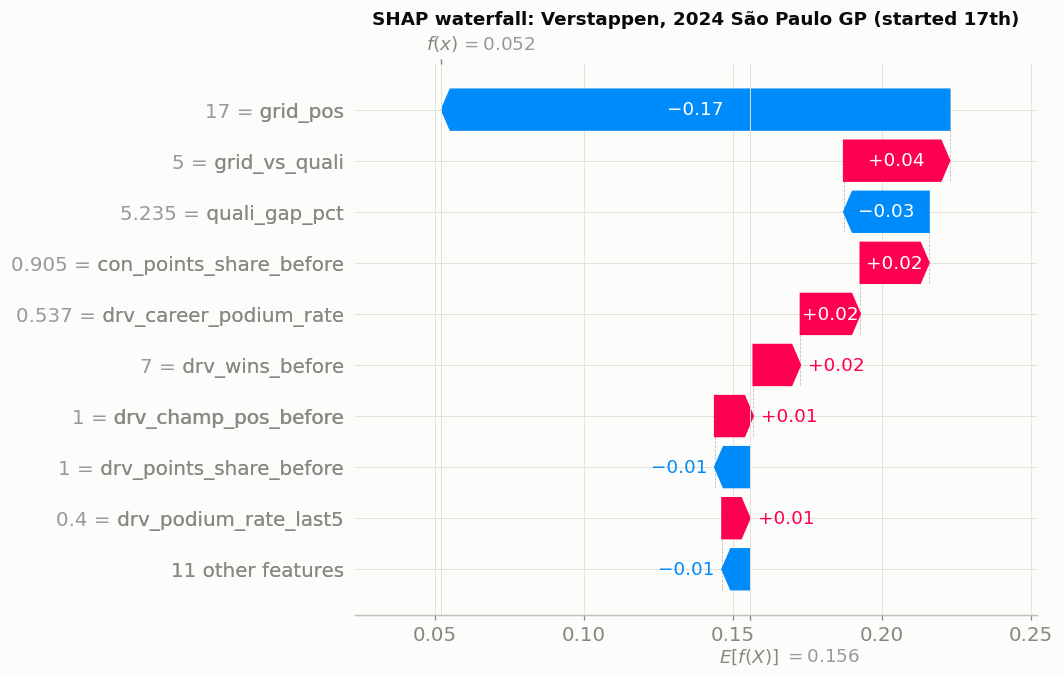

In [60]:
def row_for(year, race_contains, surname):
    m = modeling_table[(modeling_table["year"] == year) & modeling_table["race_name"].str.contains(race_contains) &
                       (modeling_table["surname"] == surname)]
    assert len(m) == 1, m
    return m

local_cases = {name: row_for(2024, "São Paulo", name) for name in ["Norris", "Verstappen"]}
for name, r in local_cases.items():
    p = final_pipe.predict_proba(r[FEATURES])[:, 1][0]
    print(f"{r['forename'].iloc[0]} {name}: grid {int(r['grid_pos'].iloc[0])}, quali {r['quali_pos'].iloc[0]:.0f}, "
          f"predicted P(podium) = {p:.2f} -> {'podium' if p >= FINAL_THRESHOLD else 'no podium'} (threshold {FINAL_THRESHOLD:.2f}); "
          f"actual: {'PODIUM' if r['podium'].iloc[0] else 'no podium'}")
    plt.figure(figsize=(9, 5))
    shap.plots.waterfall(shap_explainer(r[FEATURES])[0], max_display=10, show=False)
    plt.title(f"SHAP waterfall: {name}, 2024 São Paulo GP ({'pole' if name == 'Norris' else 'started 17th'})")
    save_fig(f"xai_local_{name.lower()}")
    plt.show()

**Interpretation (SHAP waterfalls):**
- **Norris, pole: P = 0.78**, from the average prediction of 0.156. Pole alone adds +0.29; strong team results (`con_points_share_before` +0.08, `con_finish_pct_last5` +0.08), good recent form (+0.06), the front row (+0.04) and 2nd in the championship (+0.04) add most of the rest. The model was confident and **wrong**: he finished 6th in a rain-hit race, which nothing visible before the start predicted.
- **Verstappen, 17th: P = 0.05.** Starting 17th removes 0.17 and a slow wet qualifying (5.2% off pole) another 0.03. His 5-place grid penalty (`grid_vs_quali = 5`) adds +0.04 back (the model knows he was faster than his slot), and his elite record and team (career podium rate 54%, 7 wins this season, team points share) add about +0.02 each. The model understood "very strong driver, very bad starting position" and still rated a win from 17th as rare, as it historically is.
- **The limit of a pre-race model:** it reasons sensibly, but a wet, chaotic race can overturn the grid.

**LIME** builds a different local explanation: it perturbs the row many times, asks the model for predictions on the copies, and fits a small **weighted linear model** around this one point; its weights say which feature ranges push this prediction up or down. LIME cannot take missing values, so it receives the imputed values (the pipeline's own imputation statistics), and its sampling distribution comes from the 2003–2019 training rows, as for the SHAP background.

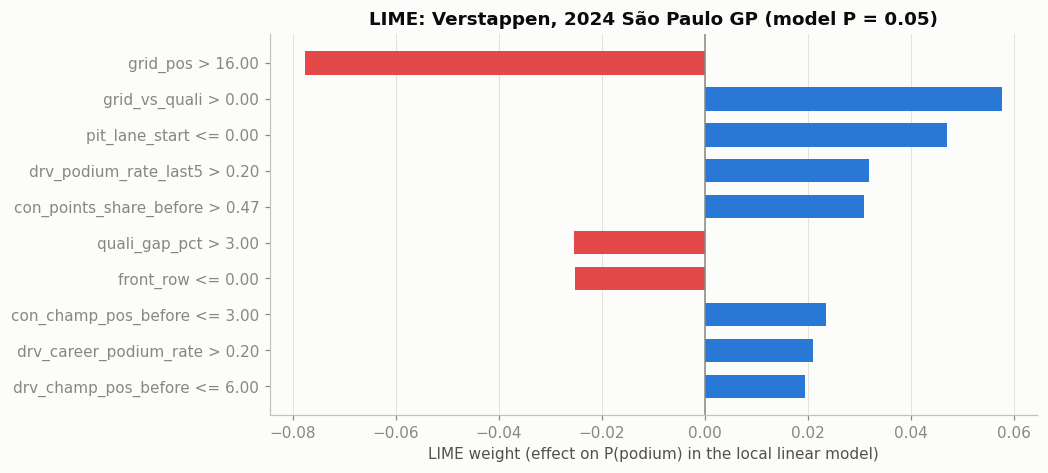

LIME local model fit R² = 0.29; local prediction = 0.14


In [61]:
imputer_final = final_pipe.named_steps["prep"].named_steps["impute"]
train_imputed = pd.DataFrame(imputer_final.transform(modern_train)[:, :len(FEATURES)], columns=FEATURES)
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=train_imputed.values, feature_names=FEATURES, class_names=["no podium", "podium"],
    mode="classification", discretize_continuous=True, random_state=RANDOM_STATE)
lime_fn = lambda a: final_pipe.predict_proba(pd.DataFrame(a, columns=FEATURES))
row_v = local_cases["Verstappen"][FEATURES].fillna(pd.Series(imputer_final.statistics_, index=FEATURES))
lime_exp = lime_explainer.explain_instance(row_v.values[0], lime_fn, num_features=10, num_samples=5000)

weights = pd.DataFrame(lime_exp.as_list(), columns=["condition", "weight"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(weights["condition"], weights["weight"], color=[C[0] if w > 0 else C[7] for w in weights["weight"]], height=0.65)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("LIME weight (effect on P(podium) in the local linear model)")
ax.set_title(f"LIME: Verstappen, 2024 São Paulo GP (model P = {lime_fn(row_v.values)[0, 1]:.2f})")
ax.grid(axis="y", visible=False)
save_fig("xai_lime_verstappen")
plt.show()
print(f"LIME local model fit R² = {lime_exp.score:.2f}; local prediction = {lime_exp.local_pred[0]:.2f}")

**Interpretation (LIME, Verstappen):**
- LIME agrees with SHAP on the main story: "grid_pos > 16" is the strongest negative weight, together with the slow qualifying gap (> 3%) and not starting on the front row; his penalty (`grid_vs_quali > 0`), strong form and a front-running team are positive.
- The local surrogate fits only loosely (**R² ≈ 0.3**, and its local prediction is 0.14 against the model's 0.05): LIME fits a linear model on *binned* features to a probability curve that is very steep near this row, so its exact weights are less reliable than the SHAP values. For a logistic-regression model SHAP is the more faithful local explanation; LIME serves as a qualitative cross-check.
- LIME's weights are on a different scale from SHAP's: coefficients of discretised "feature in range" conditions, not additive contributions to this exact prediction.


## 13. Inference function

`predict_podium(record)` takes the pre-race information about **one driver in one race** as a plain dictionary and returns the podium probability and the yes/no decision at the validation-chosen threshold.
- **Missing values** (`None`, `NaN`, or a left-out key) are allowed: the pipeline imputes them with the training medians and the missing-indicator columns tell the model they were absent. The function also returns which inputs were missing.
- **Derived features** (`front_row`, `grid_vs_quali`, `pit_lane_start`) are computed from `grid_pos` and `quali_pos` when not given, so a minimal record still yields consistent inputs.
- **Basic validation:** unknown keys are rejected and position-like values must be ≥ 1.

In [62]:
def predict_podium(record, model=final_pipe, threshold=FINAL_THRESHOLD):
    """Pre-race podium prediction for one driver in one race.

    record: dict with any subset of FEATURES (missing / None -> imputed by the pipeline).
    returns: dict with probability, decision, threshold and the list of missing inputs.
    """
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"unknown fields: {sorted(unknown)}")
    row = {f: (np.nan if record.get(f) is None else float(record.get(f))) for f in FEATURES}

    # derived features, filled only when the caller did not supply them
    if np.isnan(row["front_row"]) and not np.isnan(row["grid_pos"]):
        row["front_row"] = float(row["grid_pos"] <= 2)
    if np.isnan(row["pit_lane_start"]) and not np.isnan(row["grid_pos"]):
        row["pit_lane_start"] = 0.0
    if np.isnan(row["grid_vs_quali"]) and not (np.isnan(row["grid_pos"]) or np.isnan(row["quali_pos"])):
        row["grid_vs_quali"] = row["grid_pos"] - row["quali_pos"]

    for f in ["grid_pos", "quali_pos", "drv_champ_pos_before", "con_champ_pos_before", "field_size"]:
        if not np.isnan(row[f]) and row[f] < 1:
            raise ValueError(f"{f} must be >= 1, got {row[f]}")

    p = float(model.predict_proba(pd.DataFrame([row], columns=FEATURES))[0, 1])
    missing = [f for f in FEATURES if np.isnan(row[f])]
    return {"podium_probability": round(p, 4), "predicted_podium": p >= threshold, "threshold": round(threshold, 4),
            "n_missing_inputs": len(missing), "missing_inputs": missing}

**Demo 1, a complete record:** Max Verstappen at the 2023 Japanese GP, a real test-set row with every feature present; the function's output must equal the pipeline's prediction for that row.

**Demo 2, a partially-missing record:** the same row with its **qualifying record lost** (no qualifying position, gap to pole or penalty) and no team mechanical-DNF history. The pipeline imputes the gaps and the missing indicators tell the model they are gaps; the prediction stays high because grid, form and standings still say "fast driver in a fast car on pole".

In [63]:
complete_row = row_for(2023, "Japanese", "Verstappen")
complete_record = complete_row[FEATURES].iloc[0].to_dict()
out_complete = predict_podium(complete_record)
assert abs(out_complete["podium_probability"] - final_pipe.predict_proba(complete_row[FEATURES])[0, 1]) < 1e-4
print(complete_record)
print("Demo 1, complete record ->", out_complete, "| actual podium:", bool(complete_row["podium"].iloc[0]))

gapped_record = {**complete_record, "quali_pos": None, "quali_gap_pct": None, "grid_vs_quali": None, "con_mech_dnf_rate_last10": None}
print("Demo 2, gaps in record  ->", predict_podium(gapped_record))

{'grid_pos': 1.0, 'front_row': 1.0, 'pit_lane_start': 0.0, 'quali_pos': 1.0, 'quali_gap_pct': 0.0, 'grid_vs_quali': 0.0, 'drv_podium_rate_last5': 0.8, 'drv_finish_pct_last5': 0.04444444444444447, 'drv_dnf_rate_last10': 0.0, 'drv_career_starts': 178.0, 'drv_career_podium_rate': 0.5112359550561798, 'con_podium_rate_last5': 0.7, 'con_finish_pct_last5': 0.09795321637426897, 'con_mech_dnf_rate_last10': 0.0, 'drv_champ_pos_before': 1.0, 'drv_points_share_before': 1.0, 'drv_wins_before': 12.0, 'con_champ_pos_before': 1.0, 'con_points_share_before': 1.0, 'field_size': 20.0}
Demo 1, complete record -> {'podium_probability': 0.8868, 'predicted_podium': True, 'threshold': 0.217, 'n_missing_inputs': 0, 'missing_inputs': []} | actual podium: True
Demo 2, gaps in record  -> {'podium_probability': 0.8683, 'predicted_podium': True, 'threshold': 0.217, 'n_missing_inputs': 4, 'missing_inputs': ['quali_pos', 'quali_gap_pct', 'grid_vs_quali', 'con_mech_dnf_rate_last10']}


**Demo 3, almost everything missing, and why to be careful.** The function still answers, but the answer reflects what "missing" **meant in the training data**: missing driver form = a **debut**, missing standings = **round 1**, missing qualifying = a **patchy 1996–2002 season**, each imputed with the training *median* (a driver with no podiums). So "only grid = 1" is read as *a debutant on pole in round 1 with no qualifying record*, and the model is far more cautious than for an established pole-sitter. The comparison with gradient boosting shows this extrapolation is **model-dependent**, so for sparse records `n_missing_inputs` should be treated as a warning.

In [64]:
OTHER_MODEL = "Gradient boosting" if BEST_MODEL != "Gradient boosting" else "Logistic regression (baseline)"
other_pipe, other_thr = results[OTHER_MODEL]["pipe"], results[OTHER_MODEL]["threshold"]
sparse_cases = {
    "only grid_pos = 1": {"grid_pos": 1},
    "grid 4 + qualifying + strong team form": {"grid_pos": 4, "quali_pos": 3, "quali_gap_pct": 0.35,
                                               "con_podium_rate_last5": 0.6, "con_finish_pct_last5": 0.15},
    "same, but starting 14th": {"grid_pos": 14, "quali_pos": 14, "quali_gap_pct": 1.4,
                                "con_podium_rate_last5": 0.6, "con_finish_pct_last5": 0.15},
}
pd.DataFrame([{"record": label, "missing inputs": predict_podium(rec)["n_missing_inputs"],
               f"P(podium) {BEST_MODEL}": predict_podium(rec)["podium_probability"],
               f"P(podium) {OTHER_MODEL}": predict_podium(rec, model=other_pipe, threshold=other_thr)["podium_probability"]}
              for label, rec in sparse_cases.items()])

,record,missing inputs,P(podium) Logistic regression (baseline),P(podium) Gradient boosting
0,only grid_pos = 1,17,0.3981,0.1675
1,grid 4 + qualifying + strong team form,12,0.3464,0.3472
2,"same, but starting 14th",12,0.0396,0.0296


## 14. Limitations & conclusions

**Limitations.**
1. **Historical qualifying-coverage drift.** Qualifying starts in 1994, is patchy in 1996–2002 (down to 6% of rows) and complete only from 2003, so most 1996–2002 training rows carry *imputed* qualifying values with a missing flag. The model learns two regimes (with and without qualifying), and only the "with" regime applies to the test seasons.
2. **Era sensitivity.** Reliability, field sizes, points systems and overtaking difficulty all changed (sections 4 and 5), and the grid-to-podium curve steepened. A model trained on 1994–2019 averages over these eras; the 2022 regulation change is a real distribution shift, visible in the slightly lower test scores.
3. **Small evaluation sets.** Validation has 39 races / 117 podiums, test 68 races / 204 podiums. The bootstrap intervals overlap for all learned models, so we **cannot claim** any is clearly better than the logistic-regression baseline. Choosing the best of many configurations on a small validation set also inflates validation scores (the "winner's curse"); the network's lucky seed (0.739 vs a 0.727 mean) is an example, which is why stochastic models were selected on their seed average.
4. **Unpredictable race events are invisible before the start:** rain, safety cars, crashes, mechanical failures. The 2024 São Paulo GP shows the cost (pole-sitter rated very likely, the winner from 17th very unlikely); no pre-race feature set can capture that.
5. **Identity breaks.** Constructor renames (Toro Rosso → AlphaTauri → RB, Renault → Alpine, …) reset `constructorId`, so team history restarts at each rename; form features recover after 5–10 races.
6. **Data-handling judgement calls**, all documented above: the shared-drive rule, removing the Indianapolis 500 and the non-starters, pit-lane starters placed at the back, and the status grouping for Q3.
7. **Explanations are not causal** (section 12): they describe what the model relies on, not why drivers reach the podium.

**Conclusions.**
- A leakage-safe, one-row-per-driver-race table was built from 14 relational tables, with every key and foreign key verified and every cleaning rule backed by computed evidence.
- **Starting position and car strength dominate the prediction**, consistently across the EDA, the univariate evidence, the ablation, permutation importance and SHAP.
- All learned models clearly beat the "top 3 on the grid" rule on PR-AUC; among themselves they are statistically indistinguishable, and the simple **logistic-regression baseline holds up as well as the more complex models**. The final model, logistic regression (C = 1), reaches test PR-AUC **0.726**, F1 **0.665** and ROC-AUC **0.937**, is well calibrated, and about 2 of every 3 drivers it ranks top 3 in a race reach the podium.
- Its reasoning is transparent and intuitive (SHAP, LIME), and its failures are the races that no pre-race information could foresee.